# Data Understanding - Final

**Equipo PINU · Fase 2 de CRISP-DM**

- **Objetivo de negocio:** identificar problemas de cola mediante la detección de anomalías en el ordeñamiento.
- **Objetivo de minería de datos:** clasificar los posibles tipos de evento que se presentan en el ordeño.

Este notebook fusiona los EDA que hizo cada integrante del equipo. Se usó `understandingData.ipynb` como base (secciones 1 a 9) y de los demás archivos se agregó solo lo que no estaba cubierto, o la versión más completa cuando dos análisis eran parecidos:

| Archivo de origen | Qué se incorporó | Sección |
| :-- | :-- | :-- |
| `understandingData.ipynb` | Base: consulta de datos, tipos, nulos, duplicados, lactancia, patrones, clima, cola, sangre y mastitis, eventos | 1 a 9 |
| `eda_yael.ipynb` | Coherencia total vs cuartos, ceros de producción, atípicos, sangre por vaca, ordeños e intervalos atípicos por vaca | 11, 14, 18 |
| `dataUnderstanging.ipynb` | Producción diaria por vaca, hora, día y mes, medidas por cuarto, MDI vs conductividad y AMD | 12, 13, 14 |
| `exploracion_datos.py` | Perfil de calidad, cuartos y robots con chi-cuadrada, eventos vs intervalo y conductividad, clima con THI | 11, 13, 15, 17 |
| `exploracion_profunda.py` | Escalas temporales, eventos en el tiempo, persistencia, adaptación, correlaciones con significancia, VIF, PCA del ordeño y del clima | 11, 15, 16, 17 |
| `EDA.py` | Correlación de los eventos con las 13 variables climáticas | 17 |
| `eda_data_understanding_integrado.ipynb` | Concentrado consumido y su relación con la leche | 19 |

Los análisis repetidos (carga y limpieza de las dos fuentes, nulos, duplicados, distribuciones principales, matriz de correlación, lactancia y frecuencia de eventos) se conservaron solo en la versión de `understandingData.ipynb`. Las secciones 10 a 19 necesitan `scipy`, `scikit-learn` y `statsmodels` (están en `requirements.txt`). La sección 20 deja las fechas como `datetime` y las categóricas con one-hot. Cada sección termina con una **observación** y el notebook cierra con las **conclusiones** (sección 21).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

# Colores fijos para todas las graficas
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"

sns.set_theme(style="whitegrid", rc={
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": "#e6e5e1",
    "axes.edgecolor": "#c3c2b7",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.dpi": 110,
})

In [2]:
# Busca la raiz del repo (la carpeta que contiene Data) sin importar desde donde se ejecute
raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Data").exists())

# id_vaca y misc_eo_po son identificadores (hash), no cantidades: se leen como texto
bruto = pd.read_csv(raiz / "Data" / "dataset_vacas_anonimo.csv", dtype={"id_vaca": str, "misc_eo_po": str}, low_memory=False)

# El archivo junta dos fuentes con formatos distintos:
#   csv  (mar-jul 2025): hora "dd/mm/aaaa hh:mm a. m.", duracion "mm:ss", trae main_accion
#   xlsx (2022-2026):    hora "aaaa-mm-dd hh:mm:ss",   duracion "hh:mm:ss", no trae main_accion
es_csv = bruto["main_hora_de_inicio"].str.len() == 22
bruto["fuente"] = np.where(es_csv, "csv", "xlsx")

bruto["inicio"] = pd.Series(pd.NaT, index=bruto.index, dtype="datetime64[ns]")
bruto.loc[es_csv, "inicio"] = pd.to_datetime(
    bruto.loc[es_csv, "main_hora_de_inicio"].str.replace("a. m.", "AM", regex=False).str.replace("p. m.", "PM", regex=False),
    format="%d/%m/%Y %I:%M %p")
bruto.loc[~es_csv, "inicio"] = pd.to_datetime(bruto.loc[~es_csv, "main_hora_de_inicio"], format="%Y-%m-%d %H:%M:%S")

duracion = bruto["main_duracion_mm_ss"].where(bruto["main_duracion_mm_ss"].str.len() == 8, "00:" + bruto["main_duracion_mm_ss"])
bruto["duracion_seg"] = pd.to_timedelta(duracion).dt.total_seconds()

# Los registros de 2025 estan en las dos fuentes: se quitan del csv los que ya vienen en el xlsx (misma vaca y mismo minuto)
llaves_xlsx = set(zip(bruto.loc[~es_csv, "id_vaca"], bruto.loc[~es_csv, "inicio"].dt.floor("min")))
en_xlsx = np.array([(v, h) in llaves_xlsx for v, h in zip(bruto["id_vaca"], bruto["inicio"].dt.floor("min"))])
repetido = es_csv.to_numpy() & en_xlsx
n_repetidos_fuentes = int(repetido.sum())

df = bruto[~repetido].reset_index(drop=True)
df["main_accion"] = df["main_accion"].fillna("Ordeño")   # el xlsx solo trae ordeños: no registra rechazos
print(f"Registros: {df.shape[0]:,} | Columnas: {df.shape[1]} | Vacas: {df['id_vaca'].nunique()} | "
      f"{df['inicio'].min():%d/%m/%Y} a {df['inicio'].max():%d/%m/%Y}")
print(f"Registros del csv que ya estaban en el xlsx y se quitaron: {n_repetidos_fuentes:,}")

Registros: 280,915 | Columnas: 47 | Vacas: 207 | 13/07/2022 a 28/01/2026
Registros del csv que ya estaban en el xlsx y se quitaron: 5,302


## 1. Visualizar y consultar los datos

Cada instancia es una visita de una vaca. Las columnas vienen en grupos: `main_*` (resumen de la sesión), `estado_*` (eventos ocurridos), mediciones por cuarto de la ubre y `misc_*`.

In [3]:
df.head()

,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg,estado_numero_de_ordeno,estado_rcs_1000_celulas_ml,estado_patada,estado_incompleto,estado_pezones_no_encontrados,estado_amd_ubre,estado_amd_pezon,media_de_los_flujos_kg_min_di,media_de_los_flujos_kg_min_dd,media_de_los_flujos_kg_min_ti,media_de_los_flujos_kg_min_td,sangre_ppm_di,sangre_ppm_dd,sangre_ppm_ti,sangre_ppm_td,conductividad_ms_cm_di,conductividad_ms_cm_dd,conductividad_ms_cm_ti,conductividad_ms_cm_td,misc_eo_po,misc_usuario,misc_destino_leche,misc_razon_de_la_desviacion,flujos_maximos_kg_min_di,flujos_maximos_kg_min_dd,flujos_maximos_kg_min_ti,flujos_maximos_kg_min_td,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,main_intervalo_de_ordeno_hh_mm,contadores_monitorizacion_vaca_ubre,contadores_monitorizacion_vaca_di,contadores_monitorizacion_vaca_dd,contadores_monitorizacion_vaca_ti,contadores_monitorizacion_vaca_td,misc_programa_de_lavado,estado_mdi,fuente,inicio,duracion_seg
0,3d995085,01/03/2025 05:37 a. m.,Ordeño,09:58,23.96,1.0,NaN,NaN,NaN,NaN,1.0,NaN,1.26,1.74,1.86,1.62,0.0,0.0,0.0,0.0,4.92,5.16,5.48,5.21,7063e4b1,NaN,Tanque,NaN,1.74,2.16,2.40,2.10,6.11,5.56,3.33,8.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-01 05:37:00,598.0
1,3d995085,01/03/2025 07:15 p. m.,Ordeño,06:51,17.20,2.0,NaN,DI,NaN,NaN,1.0,NaN,1.14,1.80,2.04,1.74,0.0,0.0,0.0,0.0,4.58,4.84,5.26,4.88,7063e4b1,NaN,Tanque,NaN,2.10,2.34,2.52,2.28,3.23,4.86,2.69,6.42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-01 19:15:00,411.0
2,3d995085,02/03/2025 02:24 a. m.,Ordeño,07:23,11.13,1.0,NaN,NaN,NaN,NaN,1.0,TI,1.20,1.44,1.74,1.44,0.0,0.0,0.0,0.0,4.26,4.38,5.00,4.52,7063e4b1,NaN,Tanque,NaN,1.68,1.98,2.34,1.92,4.40,2.43,1.15,3.15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-02 02:24:00,443.0
3,3d995085,02/03/2025 07:51 p. m.,Ordeño,08:29,20.64,2.0,NaN,NaN,NaN,NaN,1.0,NaN,1.20,1.68,1.92,1.68,0.0,0.0,0.0,0.0,4.36,4.77,5.01,4.82,7063e4b1,NaN,Tanque,NaN,2.10,2.22,2.52,2.40,5.72,4.88,3.10,6.94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-02 19:51:00,509.0
4,3d995085,03/03/2025 06:00 a. m.,Ordeño,05:05,9.59,1.0,NaN,NaN,NaN,NaN,1.0,NaN,1.14,1.62,1.80,1.50,0.0,0.0,0.0,0.0,4.13,4.42,4.36,4.44,7063e4b1,NaN,Tanque,NaN,1.80,2.10,2.28,1.98,2.69,2.41,1.44,3.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-03 06:00:00,305.0


In [4]:
# Consulta: que tipo de visitas hay y en que robot ocurren
pd.crosstab(df["main_accion"], df["misc_eo_po"], margins=True, margins_name="Total")

misc_eo_po,55926a71,7063e4b1,86696b37,b96e85be,Total
main_accion,,,,,
Echada sin ordeñar,0,33,7,6,46
Ordeño,2,91405,91649,97643,280699
Rechazada,0,98,48,24,170
Total,2,91536,91704,97673,280915


In [5]:
# Consulta: cuantos registros tiene cada vaca
registros_vaca = df.groupby("id_vaca").size().sort_values()
print(f"Vacas: {registros_vaca.size} | min: {registros_vaca.min()} | mediana: {registros_vaca.median():.0f} | max: {registros_vaca.max()}")
print("\nVacas con menos de 30 registros:")
print(registros_vaca[registros_vaca < 30].to_string())

Vacas: 207 | min: 2 | mediana: 1268 | max: 3569

Vacas con menos de 30 registros:
id_vaca
f755352f     2
7fdc08e7    11
48f1f617    26


In [6]:
# Consulta: ejemplo de sesiones con ordeño incompleto
columnas_consulta = ["id_vaca", "main_hora_de_inicio", "main_duracion_mm_ss", "main_produccion_kg",
                     "estado_patada", "estado_incompleto", "estado_pezones_no_encontrados", "misc_eo_po"]
df[df["estado_incompleto"].notna()][columnas_consulta].head(8)

,id_vaca,main_hora_de_inicio,main_duracion_mm_ss,main_produccion_kg,estado_patada,estado_incompleto,estado_pezones_no_encontrados,misc_eo_po
40,3d995085,25/03/2025 12:35 p. m.,04:23,3.40,NaN,Todos,NaN,7063e4b1
49,3d995085,30/03/2025 02:36 p. m.,04:44,5.74,NaN,Todos,NaN,7063e4b1
76,3d995085,16/04/2025 08:21 p. m.,03:27,1.05,NaN,Todos,"DI,DD,TI",7063e4b1
86,3d995085,23/04/2025 10:25 p. m.,10:50,21.58,NaN,TI,TI,7063e4b1
88,3d995085,25/04/2025 12:24 p. m.,07:49,12.94,NaN,TI,NaN,7063e4b1
98,3d995085,30/04/2025 11:32 p. m.,11:08,18.78,NaN,TI,TI,7063e4b1
100,3d995085,02/05/2025 03:43 a. m.,07:21,13.61,NaN,TI,NaN,7063e4b1
101,3d995085,02/05/2025 09:54 p. m.,09:18,19.38,NaN,TI,TI,7063e4b1


In [7]:
# Estadisticos descriptivos de las variables numericas
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
main_produccion_kg,280699.0,14.816953,0.0,11.07,14.29,18.1,78.17,5.336473
estado_numero_de_ordeno,280699.0,1.837808,1.0,1.0,2.0,2.0,6.0,0.84483
estado_rcs_1000_celulas_ml,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_amd_ubre,280699.0,0.122113,0.0,0.0,0.0,0.0,1.0,0.327417
media_de_los_flujos_kg_min_di,275473.0,1.150722,0.0,0.9,1.14,1.38,4.98,0.397374
media_de_los_flujos_kg_min_dd,273424.0,1.178852,0.0,0.96,1.2,1.44,4.86,0.387916
media_de_los_flujos_kg_min_ti,276195.0,1.169156,0.0,0.9,1.14,1.44,5.1,0.487883
media_de_los_flujos_kg_min_td,269699.0,1.126345,0.0,0.84,1.14,1.44,4.98,0.466624
sangre_ppm_di,275473.0,34.371793,0.0,0.0,0.0,0.0,8000.0,347.635189
sangre_ppm_dd,273424.0,17.217677,0.0,0.0,0.0,0.0,7999.0,175.219175


**Observaciones:** El dataset unificado tiene 280,915 registros de 207 vacas entre julio de 2022 y enero de 2026, repartidos casi por igual en tres máquinas (de 92 a 98 mil cada una). El 99.9 % son ordeños: las 216 visitas rechazadas o de «echada sin ordeñar» solo existen en los datos de 2025, porque el archivo de 2022 a 2026 no las registra. El historial por vaca es muy desigual (mediana de 1,268 registros, máximo de 3,569, y tres vacas con menos de 30). Además, `sangre_ppm_*` es casi siempre 0 con máximos de 8,000, `conductividad_ms_cm_*` tiene mínimo 0 (imposible en leche) y no existe la hora de salida, solo la de inicio y la duración.

### Descripción de cada columna:

Cada fila es una visita de una vaca a una máquina de ordeño. Los sufijos `_di`, `_dd`, `_ti` y `_td` indican el cuarto de la ubre: delantero izquierdo, delantero derecho, trasero izquierdo y trasero derecho.

**Identificación y resumen de la sesión**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `id_vaca` | Identificador de la vaca, anonimizado con un hash. | Identificador |
| `main_hora_de_inicio` | Fecha y hora en que inició la visita. Tiene dos formatos según la fuente: `dd/mm/aaaa hh:mm a. m./p. m.` (csv, con minutos) y `aaaa-mm-dd hh:mm:ss` (xlsx, con segundos). | Fecha y hora (texto) |
| `main_accion` | Resultado de la visita: `Ordeño`, `Rechazada` (la vaca entró pero no fue ordeñada) o `Echada sin ordeñar`. | Categórica |
| `main_duracion_mm_ss` | Duración de la visita: `mm:ss` en el csv y `hh:mm:ss` en el xlsx. | Duración (texto) |
| `main_produccion_kg` | Leche total obtenida en el ordeño, en kg. Es la suma de los cuatro cuartos. | Numérica continua |

**Estado y eventos del ordeño**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `estado_numero_de_ordeno` | Número consecutivo del ordeño de la vaca en el día (1 a 5). | Numérica discreta |
| `estado_rcs_1000_celulas_ml` | Recuento de células somáticas, en miles de células por ml. Indicador de salud de la ubre. **Vacía en todos los registros.** | Numérica (sin datos) |
| `estado_patada` | Cuartos en los que la vaca pateó la pezonera. Vacío = no hubo patada. | Evento por cuarto |
| `estado_incompleto` | Cuartos cuyo ordeño no se completó. Vacío = ordeño completo. | Evento por cuarto |
| `estado_pezones_no_encontrados` | Cuartos en los que la máquina no logró localizar el pezón. Vacío = se encontraron todos. | Evento por cuarto |
| `estado_amd_ubre` | Alerta AMD a nivel de ubre (0 = sin alerta, 1 = con alerta). *Significado de AMD por confirmar.* | Binaria |
| `estado_amd_pezon` | Cuartos con alerta AMD. Vacío = sin alerta. *Significado de AMD por confirmar.* | Evento por cuarto |

En las columnas de evento por cuarto el valor es la lista de cuartos afectados (`TI`, `DI,TD`) o `Todos`.

**Mediciones por cuarto** (cuatro columnas cada una: `_di`, `_dd`, `_ti`, `_td`)

| Columnas | Descripción | Tipo |
| :-- | :-- | :-- |
| `media_de_los_flujos_kg_min_*` | Flujo promedio de leche del cuarto durante el ordeño, en kg/min. | Numérica continua |
| `flujos_maximos_kg_min_*` | Flujo máximo de leche alcanzado en el cuarto, en kg/min. | Numérica continua |
| `producciones_kg_*` | Leche obtenida del cuarto, en kg. | Numérica continua |
| `sangre_ppm_*` | Sangre detectada en la leche del cuarto, en partes por millón. Normalmente es 0. | Numérica continua |
| `conductividad_ms_cm_*` | Conductividad eléctrica de la leche del cuarto, en mS/cm. Valores altos se asocian con mastitis. Un 0 se interpreta como lectura faltante. | Numérica continua |

**Otros**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `misc_eo_po` | Máquina de ordeño en la que ocurrió la visita, anonimizada con un hash (3 máquinas). | Categórica |
| `misc_usuario` | Usuario que intervino en la sesión. **Vacía en todos los registros.** | Sin datos |
| `misc_destino_leche` | A dónde se envió la leche: `Tanque`, `Drenaje` (se desecha) o `Divert 1`, `2` y `3` (se desvía a una línea aparte). | Categórica |
| `misc_razon_de_la_desviacion` | Motivo por el que la leche no fue al tanque: «Sangre por pezón por encima del umbral» (1,498 registros) o «Separada manualmente» (44). | Categórica (casi sin datos) |

**Columnas que solo trae el xlsx (2022 a 2026)**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `main_intervalo_de_ordeno_hh_mm` | Tiempo desde el ordeño anterior de la vaca (`hh:mm:ss`). | Duración (texto) |
| `contadores_monitorizacion_vaca_*` | Contadores de monitoreo de la ubre y de cada cuarto. *Significado por confirmar.* | Numérica discreta |
| `misc_programa_de_lavado` | Programa de lavado asociado al registro; solo trae el valor «Local Aclarado» (15,695 registros). *Significado por confirmar.* | Categórica (casi sin datos) |
| `estado_mdi` | Valor numérico de monitoreo, con mediana de 1.1. *Significado por confirmar.* | Numérica continua |

**Columnas creadas al cargar**

| Columna | Descripción | Tipo |
| :-- | :-- | :-- |
| `fuente` | De qué fuente viene el registro (`csv` o `xlsx`). | Categórica |
| `inicio` | Hora de inicio ya convertida a fecha y hora. | Fecha y hora |
| `duracion_seg` | Duración de la visita en segundos. | Numérica continua |

## 2. Tipos de datos

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 280915 entries, 0 to 280914
Data columns (total 47 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   id_vaca                              280915 non-null  str           
 1   main_hora_de_inicio                  280915 non-null  str           
 2   main_accion                          280915 non-null  str           
 3   main_duracion_mm_ss                  280915 non-null  str           
 4   main_produccion_kg                   280699 non-null  float64       
 5   estado_numero_de_ordeno              280699 non-null  float64       
 6   estado_rcs_1000_celulas_ml           0 non-null       float64       
 7   estado_patada                        45119 non-null   str           
 8   estado_incompleto                    33517 non-null   str           
 9   estado_pezones_no_encontrados        33022 non-null   str           
 10  estado_

**Observaciones:** Pandas asigna un tipo distinto al real en varias columnas: la hora de inicio y la duración están como texto (la hora en dos formatos y la duración como `mm:ss` o `hh:mm:ss`, por eso al cargar se crean `inicio` y `duracion_seg`), y `estado_numero_de_ordeno` y `estado_amd_ubre` son `float` solo porque tienen nulos. Las cuatro columnas de evento (`patada`, `incompleto`, `pezones_no_encontrados`, `amd_pezon`) guardan la lista de cuartos afectados (`TI`, `DI,TD`, `Todos`) y no un sí o no, así que hay que convertirlas en variables utilizables. Hay 21 columnas de mediciones continuas (la producción total más 5 magnitudes por cuatro cuartos) y 8 columnas nuevas del xlsx cuyo significado hay que confirmar.

## 3. Nulos: cantidad y porcentaje

In [9]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
}).sort_values("porcentaje", ascending=False)

print(f"Celdas nulas: {df.isna().sum().sum():,} de {df.size:,} ({df.isna().sum().sum() / df.size:.1%})")
nulos

Celdas nulas: 2,272,782 de 13,203,005 (17.2%)


,nulos,porcentaje
misc_usuario,280913,100.00
estado_rcs_1000_celulas_ml,280915,100.00
misc_razon_de_la_desviacion,279373,99.45
misc_programa_de_lavado,265220,94.41
estado_amd_pezon,254674,90.66
estado_pezones_no_encontrados,247893,88.24
estado_incompleto,247398,88.07
estado_patada,235796,83.94
estado_mdi,23709,8.44
sangre_ppm_td,11216,3.99


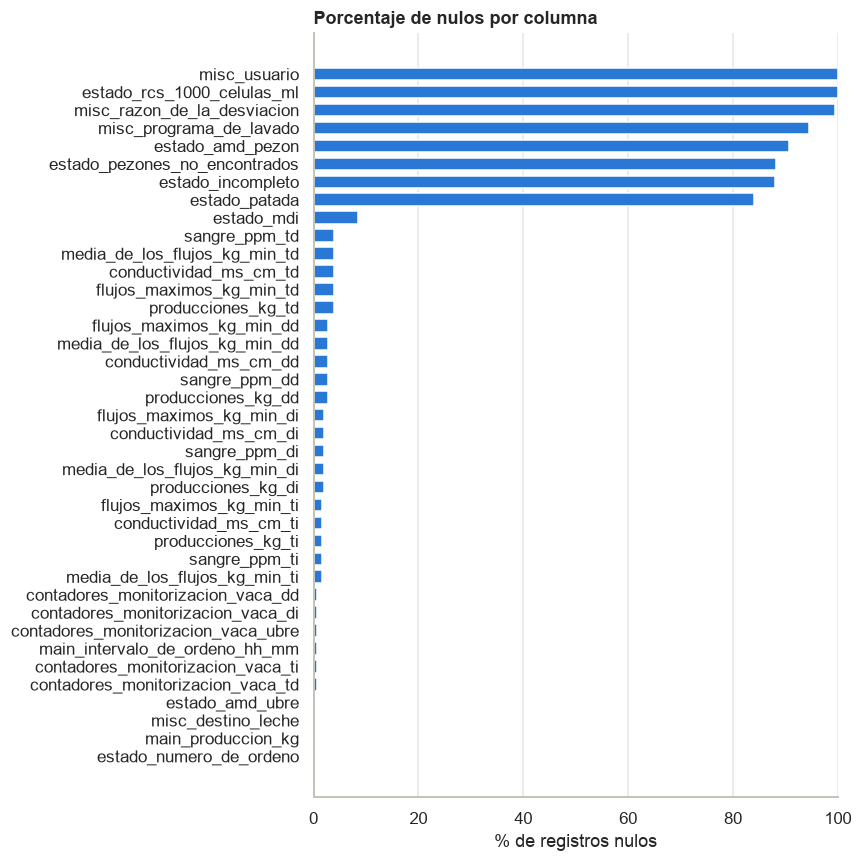

In [10]:
fig, ax = plt.subplots(figsize=(8, 8))
orden = nulos[nulos["nulos"] > 0].sort_values("porcentaje")
ax.barh(orden.index, orden["porcentaje"], color=AZUL, height=0.7)
ax.set_title("Porcentaje de nulos por columna")
ax.set_xlabel("% de registros nulos")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

El porcentaje por sí solo engaña: casi ningún nulo es un dato "perdido". Se revisa de dónde viene cada bloque.

In [11]:
df_sin_prod = df[df["main_produccion_kg"].isna()]
df_prod = df[df["main_produccion_kg"].notna()]

print(f"Registros con produccion: {df_prod.shape[0]:,} | Registros sin produccion: {df_sin_prod.shape[0]:,}")
print("Registros de echadas sin ordeñar: ", df[(df["main_accion"] == "Echada sin ordeñar")].shape[0])
print("Registros de rechazadas: ", df[(df["main_accion"] == "Rechazada")].shape[0])

Registros con produccion: 280,699 | Registros sin produccion: 216
Registros de echadas sin ordeñar:  46
Registros de rechazadas:  170


**Observaciones:** La producción total es nula solo en las 216 visitas que no fueron ordeño (170 rechazadas y 46 echadas sin ordeñar, todas del csv), que son 0.08 % de los registros; los 280,699 ordeños siempre la traen. Son nulos estructurales y no datos perdidos: no se deben imputar, y las mediciones por cuarto (flujos, sangre, conductividad) se analizan solo sobre los ordeños. Como el xlsx no trae `main_accion`, sus 278,968 registros se toman como ordeños y no se pueden contar rechazos antes de 2025.

In [12]:
# Nulos por cuarto: estan repartidos o concentrados en vacas especificas?
ordenos = df[df["main_produccion_kg"].notna()]
total = 0
for cuarto in ["di", "dd", "ti", "td"]:
    cuarto_nulo = ordenos[ordenos[f"producciones_kg_{cuarto}"] == 0]
    print(f"Cuarto {cuarto.upper()} distribucion en las máquinas: \n")
    nulos_por_maquina = cuarto_nulo.groupby("misc_eo_po").size().sort_values(ascending=False)
    print(nulos_por_maquina.to_string())
    print(f"Cuarto {cuarto.upper()} sin registro de produccion total: ", cuarto_nulo.shape[0])
    total += cuarto_nulo.shape[0]
print(f"Total de nulos en todos los cuartos: {total}")

Cuarto DI distribucion en las máquinas: 

misc_eo_po
86696b37    1954
7063e4b1    1451
b96e85be    1116
Cuarto DI sin registro de produccion total:  4521
Cuarto DD distribucion en las máquinas: 

misc_eo_po
b96e85be    1792
86696b37    1378
7063e4b1    1059
Cuarto DD sin registro de produccion total:  4229
Cuarto TI distribucion en las máquinas: 

misc_eo_po
7063e4b1    4369
86696b37    4237
b96e85be    4219
Cuarto TI sin registro de produccion total:  12825
Cuarto TD distribucion en las máquinas: 

misc_eo_po
b96e85be    4784
86696b37    4677
7063e4b1    3752
Cuarto TD sin registro de produccion total:  13213
Total de nulos en todos los cuartos: 34788


**Observaciones:** Aunque en estos ordeños se obtuvo leche de la vaca, en 28,615 de ellos (10.2 %) al menos un cuarto de la ubre quedó sin producción, y en total son 34,788 casos de cuarto sin leche. Los cuartos traseros concentran 26,038 (75 %) y fallan en cerca de 4.6 % de los ordeños cada uno, contra 1.5 % de los delanteros. La distribución es casi igual en las tres máquinas, así que no parece un problema de una máquina en particular. Un cuarto sin producción coincide con ordeño incompleto en 83 % de los casos (contra 4 % cuando todos los cuartos producen).

In [13]:
for cuarto in ["di", "dd", "ti", "td"]:
    es_cero = ordenos[ordenos[f"conductividad_ms_cm_{cuarto}"] == 0]
    sin_leche = ordenos[ordenos[f"producciones_kg_{cuarto}"] == 0]
    print(f"Cuarto {cuarto.upper()} con conductividad 0 de cada máquina: \n")
    cero_maquina = es_cero.groupby("misc_eo_po")
    sin_leche_maquina = sin_leche.groupby("misc_eo_po")
    for maquina in ordenos["misc_eo_po"].unique():
        n_cero = cero_maquina.size().get(maquina, 0)
        n_sin_leche = sin_leche_maquina.size().get(maquina, 0)
        print(f"Máquina {maquina}: conductividad 0 en {n_cero:,} ordeños; "
              f"sin leche en {n_sin_leche:,} ordeños")


Cuarto DI con conductividad 0 de cada máquina: 

Máquina 7063e4b1: conductividad 0 en 1,513 ordeños; sin leche en 1,451 ordeños
Máquina 86696b37: conductividad 0 en 1,976 ordeños; sin leche en 1,954 ordeños
Máquina b96e85be: conductividad 0 en 1,149 ordeños; sin leche en 1,116 ordeños
Máquina 55926a71: conductividad 0 en 0 ordeños; sin leche en 0 ordeños
Cuarto DD con conductividad 0 de cada máquina: 

Máquina 7063e4b1: conductividad 0 en 1,785 ordeños; sin leche en 1,059 ordeños
Máquina 86696b37: conductividad 0 en 1,382 ordeños; sin leche en 1,378 ordeños
Máquina b96e85be: conductividad 0 en 5,871 ordeños; sin leche en 1,792 ordeños
Máquina 55926a71: conductividad 0 en 0 ordeños; sin leche en 0 ordeños
Cuarto TI con conductividad 0 de cada máquina: 

Máquina 7063e4b1: conductividad 0 en 8,069 ordeños; sin leche en 4,369 ordeños
Máquina 86696b37: conductividad 0 en 9,444 ordeños; sin leche en 4,237 ordeños
Máquina b96e85be: conductividad 0 en 5,769 ordeños; sin leche en 4,219 ordeños


**Observaciones:** La conductividad de la leche no puede ser 0, así que esos valores son lecturas faltantes que `.isna()` no detecta. En DI el cero coincide con el cuarto sin leche en las tres máquinas (4,638 ceros contra 4,521 cuartos sin leche), pero en DD y TI hay más ceros que cuartos sin leche (9,038 contra 4,229 y 23,282 contra 12,825), o sea ceros con leche producida, que son fallas de lectura. El caso más grave es TD en la máquina `b96e85be`: 70,604 ceros (89 % de los de TD) contra 4,784 cuartos sin leche, lo que apunta a un sensor que no registra; en las otras dos máquinas los ceros de TD sí coinciden con los cuartos sin leche. Estos ceros deben tratarse como faltantes y reportarse al cliente.

**Tipos de nulo en el dataset**

| Tipo | Columnas | Qué significa | Tratamiento sugerido |
| :-- | :-- | :-- | :-- |
| Columna vacía (100 %) | `estado_rcs_1000_celulas_ml` | El recuento de células somáticas no se registra en ningún ordeño | Eliminar |
| Columna vacía (100 %) | `misc_usuario` | Usuario que intervino manualmente; no hay ninguno registrado en todo el periodo | Eliminar |
| Casi vacía (99.5 %) | `misc_razon_de_la_desviacion` | Solo 1,542 registros con motivo del desvío de la leche (casi todos por sangre) | Convertir a 0/1 (leche desviada) |
| Casi vacía (94.4 %) | `misc_programa_de_lavado` | Solo trae el valor «Local Aclarado» y solo en el xlsx | Confirmar su significado con el cliente |
| Nulo = "no ocurrió" (84–91 %) | `estado_patada`, `estado_incompleto`, `estado_pezones_no_encontrados`, `estado_amd_pezon` | La celda vacía significa que el evento **no** pasó | Convertir a 0/1, no imputar |
| Nulo estructural (0.08 %) | Todas las mediciones | Son las 216 visitas que no fueron ordeño | Separar por tipo de visita |
| Columnas de una sola fuente (0.7 %) | `main_intervalo_de_ordeno_hh_mm`, `contadores_monitorizacion_vaca_*`, `estado_mdi` | Solo existen en el xlsx; faltan en los 1,947 registros del csv que no estaban en el xlsx (`estado_mdi` falta además en 7.8 % del xlsx) | Calcular el intervalo con la hora de inicio |
| Cuarto no ordeñado | `*_di`, `*_dd`, `*_ti`, `*_td` | En 1 o 2 vacas por cuarto la medición falta en todos sus ordeños | Confirmar con el socio formador |
| Cero como nulo | `conductividad_ms_cm_*` | En DI, DD y TI el 0 aparece cuando el cuarto no dio leche. En TD, 28 % de los ordeños tienen 0 y la mayoría viene de la máquina `b96e85be` (72 % de sus ordeños, más de 90 % desde 2024) | Tratar como faltante y confirmar con el cliente |

Los problemas de calidad reales son los ceros de conductividad y los cuartos sin medición; el resto es información, no ausencia de ella.

## 4. Datos duplicados

In [14]:
duplicados = df.duplicated(subset=["id_vaca", "misc_eo_po", "main_hora_de_inicio"], keep=False)

print(f"Filas duplicadas por vaca, máquina y minuto de inicio:", duplicados.sum())
df[duplicados]

Filas duplicadas por vaca, máquina y minuto de inicio: 15


,id_vaca,main_hora_de_inicio,main_accion,main_duracion_mm_ss,main_produccion_kg,estado_numero_de_ordeno,estado_rcs_1000_celulas_ml,estado_patada,estado_incompleto,estado_pezones_no_encontrados,estado_amd_ubre,estado_amd_pezon,media_de_los_flujos_kg_min_di,media_de_los_flujos_kg_min_dd,media_de_los_flujos_kg_min_ti,media_de_los_flujos_kg_min_td,sangre_ppm_di,sangre_ppm_dd,sangre_ppm_ti,sangre_ppm_td,conductividad_ms_cm_di,conductividad_ms_cm_dd,conductividad_ms_cm_ti,conductividad_ms_cm_td,misc_eo_po,misc_usuario,misc_destino_leche,misc_razon_de_la_desviacion,flujos_maximos_kg_min_di,flujos_maximos_kg_min_dd,flujos_maximos_kg_min_ti,flujos_maximos_kg_min_td,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,main_intervalo_de_ordeno_hh_mm,contadores_monitorizacion_vaca_ubre,contadores_monitorizacion_vaca_di,contadores_monitorizacion_vaca_dd,contadores_monitorizacion_vaca_ti,contadores_monitorizacion_vaca_td,misc_programa_de_lavado,estado_mdi,fuente,inicio,duracion_seg
272,3851395f,06/05/2025 02:46 p. m.,Rechazada,00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7063e4b1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-05-06 14:46:00,0.0
273,3851395f,06/05/2025 02:46 p. m.,Rechazada,00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7063e4b1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-05-06 14:46:00,0.0
614,7588fd14,16/03/2025 05:35 a. m.,Ordeño,08:51,13.87,1.0,NaN,NaN,NaN,NaN,0.0,NaN,0.66,0.78,0.72,0.78,0.0,0.0,0.0,0.0,4.32,4.56,4.59,0.0,b96e85be,NaN,Tanque,NaN,0.96,1.32,1.08,1.20,2.79,2.71,4.22,4.15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-16 05:35:00,531.0
615,7588fd14,16/03/2025 05:35 a. m.,Echada sin ordeñar,08:50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,b96e85be,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-16 05:35:00,530.0
1040,5e57b4f1,28/05/2025 07:30 a. m.,Rechazada,00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86696b37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-05-28 07:30:00,0.0
1041,5e57b4f1,28/05/2025 07:30 a. m.,Rechazada,00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86696b37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-05-28 07:30:00,0.0
1485,7648b6a6,27/06/2025 01:39 p. m.,Ordeño,09:23,12.43,1.0,NaN,NaN,NaN,NaN,0.0,NaN,0.72,0.72,NaN,0.84,0.0,0.0,NaN,0.0,4.92,5.19,NaN,4.9,7063e4b1,NaN,Tanque,NaN,1.14,1.26,NaN,1.38,3.57,3.07,NaN,5.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-06-27 13:39:00,563.0
1486,7648b6a6,27/06/2025 01:39 p. m.,Echada sin ordeñar,09:23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7063e4b1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-06-27 13:39:00,563.0
1586,e202cdc8,16/03/2025 02:48 a. m.,Ordeño,05:05,11.72,1.0,NaN,NaN,NaN,NaN,0.0,NaN,1.14,1.20,1.20,1.14,0.0,0.0,0.0,0.0,4.80,4.69,4.71,0.0,b96e85be,NaN,Tanque,NaN,1.44,1.68,1.74,1.62,2.67,3.07,2.95,3.03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-16 02:48:00,305.0
1587,e202cdc8,16/03/2025 02:48 a. m.,Echada sin ordeñar,05:04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,b96e85be,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,csv,2025-03-16 02:48:00,304.0


**Observaciones:** Hay muy pocos duplicados en el dataset ya unificado: 7 grupos de registros (15 filas) repiten vaca, máquina y hora de inicio, y solo 2 son copias exactas (dos pares de rechazos de 00:00 de las vacas `3851395f` y `5e57b4f1`), que pueden ser un error de captura y se pueden eliminar sin perder información. Los otros 5 no son copias: en tres, un `Ordeño` y un `Echada sin ordeñar` duran lo mismo (con 1 s de diferencia como máximo), así que parecen la misma visita registrada dos veces, y en los otros dos (vacas `a878349c` y `e202cdc8`) hay intentos cortos seguidos, de 1 a 46 s. El duplicado importante es otro: 5,302 registros del csv de 2025 ya estaban en el xlsx con distinto formato de hora y duración, y se quitaron al cargar los datos para no contarlos dos veces.

## 5. Ciclo de lactancia

Una vaca lechera sigue una curva de lactancia: después del parto la producción **sube** durante unas semanas hasta un **pico**, luego **baja** poco a poco y, antes del siguiente parto, la vaca se **seca** (deja de ordeñarse unos 60 días). Si esa curva se ve en los datos, la etapa de lactancia de cada vaca se puede tomar en cuenta para saber cuánta leche es normal esperar de ella.

El dataset no trae fecha de parto ni días en leche, así que la etapa solo se puede inferir de la forma de la producción diaria.

In [15]:
# Produccion diaria por vaca: suma de todos los ordeños del dia
visitas = df[df["main_produccion_kg"] > 0].copy()
visitas["fecha"] = visitas["inicio"].dt.normalize()


diaria = (visitas.groupby(["id_vaca", "fecha"])
          .agg(kg=("main_produccion_kg", "sum"), ordeños=("main_produccion_kg", "size"))
          .reset_index().sort_values(["id_vaca", "fecha"]))
diaria["dias_sin_ordeño"] = diaria.groupby("id_vaca")["fecha"].diff().dt.days
calendario = pd.date_range(diaria["fecha"].min(), diaria["fecha"].max())

# La produccion del dia depende de cuantas veces vino la vaca
# vacas = cuantas vacas distintas tuvieron al menos un dia con ese numero de ordeños
# kg_mediana = mediana de kg de esos dias
resumen_dia = (diaria.groupby("ordeños")
               .agg(vacas=("id_vaca", "nunique"), kg_mediana=("kg", "median"))
               .round(1))
resumen_dia.index.name = "ordeños_en_el_dia"
print("Vacas ordeñadas según el número de ordeños en el día:")
resumen_dia


Vacas ordeñadas según el número de ordeños en el día:


,vacas,kg_mediana
ordeños_en_el_dia,,
1,207,17.6
2,206,31.1
3,202,42.0
4,173,53.3
5,88,61.3
6,11,60.3


In [16]:
def serie_diaria(vaca):
    """Produccion diaria de una vaca sobre el calendario completo (dias sin ordeño = NaN) y su promedio movil de 7 dias."""
    kg = diaria[diaria["id_vaca"] == vaca].set_index("fecha")["kg"].reindex(calendario)
    return kg, kg.rolling(7, min_periods=3, center=True).mean()


# Resumen por vaca: dias con ordeño y ausencias de mas de 40 dias (posible periodo de secado)
resumen_vacas = diaria.groupby("id_vaca").agg(
    dias=("fecha", "size"), primer_dia=("fecha", "min"), ultimo_dia=("fecha", "max"),
    ausencias=("dias_sin_ordeño", lambda s: (s > 40).sum()))
print(f"Vacas: {len(resumen_vacas)} | con al menos 30 días de ordeño: {(resumen_vacas['dias'] >= 30).sum()} | "
      f"con alguna ausencia de más de 40 días: {(resumen_vacas['ausencias'] > 0).sum()}")
resumen_vacas["dias"].describe().round(0).to_frame("días con ordeño por vaca").T

Vacas: 207 | con al menos 30 días de ordeño: 200 | con alguna ausencia de más de 40 días: 133


,count,mean,std,min,25%,50%,75%,max
días con ordeño por vaca,207.0,561.0,351.0,2.0,268.0,520.0,933.0,1164.0


### 5.1 Producción diaria de cada vaca

Cada punto gris es la producción total de un día y la línea azul es el promedio móvil de 7 días. Se muestran las 30 vacas con más días de ordeño, con historias de unos tres años que incluyen varias lactancias.

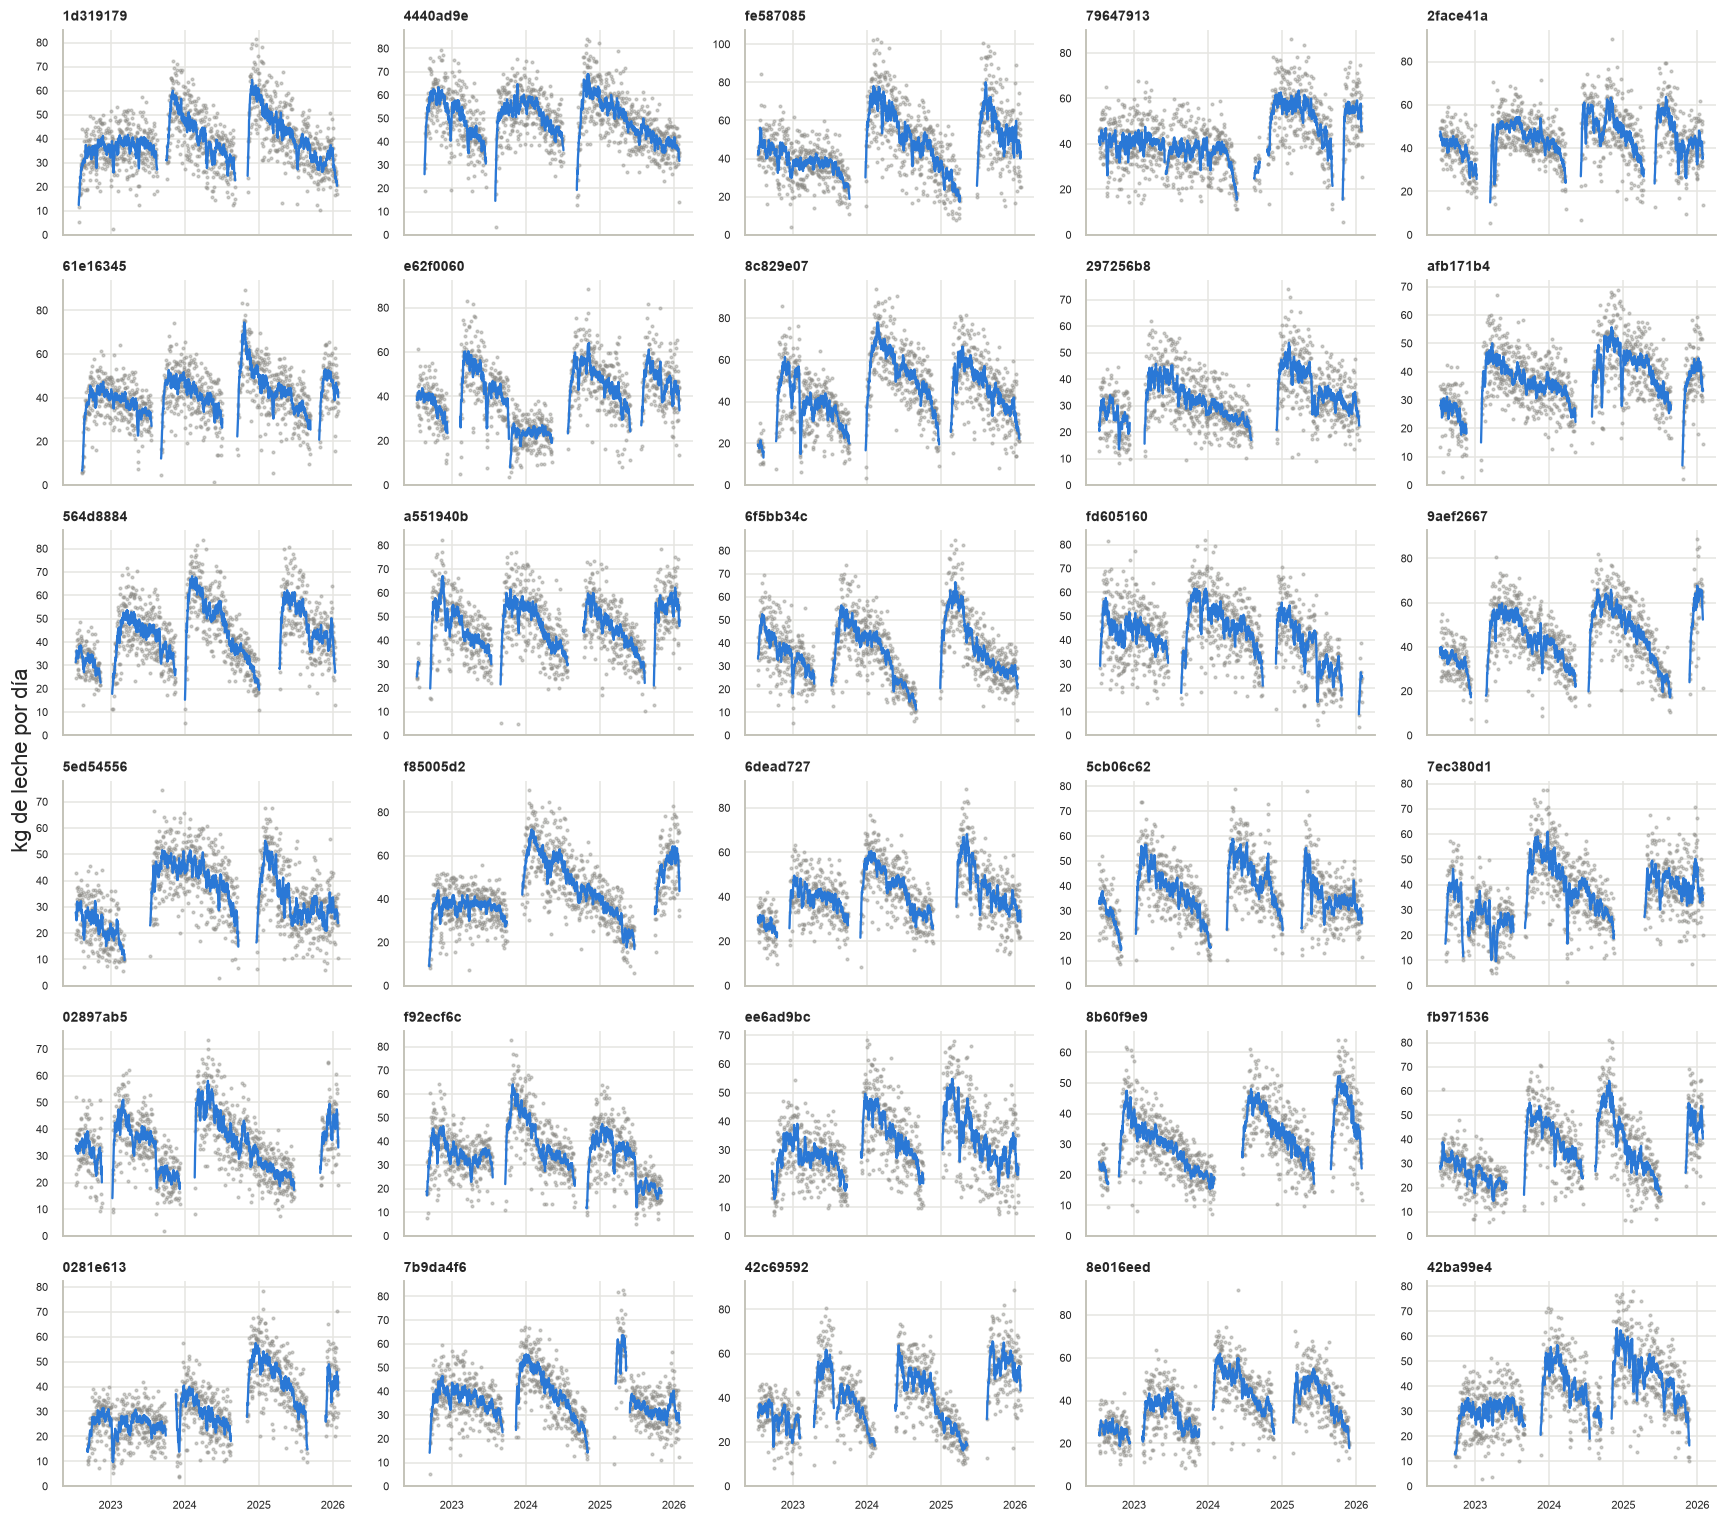

In [17]:
# Las 30 vacas con mas dias de ordeño (las historias mas largas)
largas = resumen_vacas.sort_values("dias", ascending=False).head(30).index

fig, axes = plt.subplots(6, 5, figsize=(16, 14), sharex=True)
for ax, vaca in zip(axes.flat, largas):
    kg, suave = serie_diaria(vaca)
    ax.scatter(kg.index, kg.values, s=3, color=GRIS, alpha=0.4)
    ax.plot(suave.index, suave.values, color=AZUL, linewidth=1.5)
    ax.set_title(vaca, fontsize=9)
    ax.set_ylim(0, None)
    ax.tick_params(labelsize=7)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.supylabel("kg de leche por día")
plt.tight_layout()
plt.show()

### 5.2 Vacas que se ausentan y regresan

Las zonas naranjas son los días sin ningún ordeño. Se muestran 8 ejemplos tomados al azar de las ausencias de más de 40 días en las que la vaca tiene al menos 30 días con ordeño antes y después; la tabla resume todas esas ausencias.

Ausencias de más de 40 días con historia a los dos lados: 237 de 129 vacas


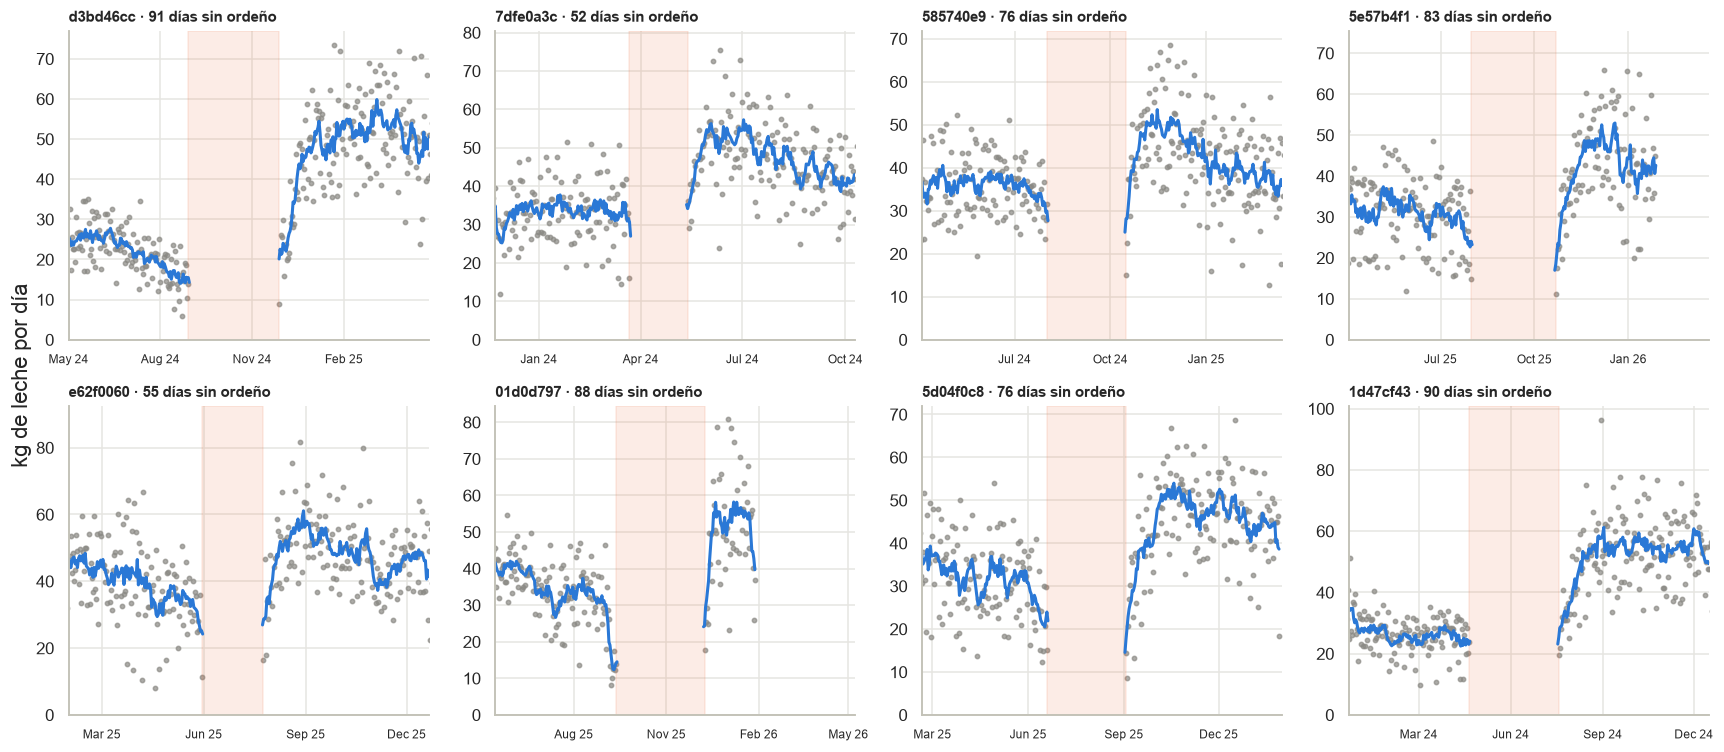

,dias_ausente,kg_antes,kg_primeros_3_dias,kg_pico_7d,dias_hasta_el_pico
25%,64.0,21.0,19.0,51.0,34.0
50%,81.0,25.0,24.0,55.0,45.0
75%,100.0,29.0,29.0,61.0,60.0


In [18]:
# Ausencias de mas de 40 dias de vacas con historia antes y despues (al menos 30 dias con ordeño en cada lado)
ausentes = diaria[diaria["dias_sin_ordeño"] > 40][["id_vaca", "fecha", "dias_sin_ordeño"]]
dias_por_vaca = diaria.groupby("id_vaca")["fecha"]
ausentes = ausentes[[
    ((diaria["id_vaca"] == v) & (diaria["fecha"] < f - pd.Timedelta(days=int(d)))).sum() >= 30
    and ((diaria["id_vaca"] == v) & (diaria["fecha"] >= f)).sum() >= 30
    for v, f, d in ausentes.itertuples(index=False)]]
print(f"Ausencias de más de 40 días con historia a los dos lados: {len(ausentes)} de {len(ausentes.id_vaca.unique())} vacas")

ejemplos = ausentes.sample(8, random_state=1)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (vaca, regreso, dias) in zip(axes.flat, ejemplos.itertuples(index=False)):
    kg, suave = serie_diaria(vaca)
    ax.scatter(kg.index, kg.values, s=8, color=GRIS, alpha=0.7)
    ax.plot(suave.index, suave.values, color=AZUL, linewidth=2)
    ax.axvspan(regreso - pd.Timedelta(days=int(dias)), regreso, color=NARANJA, alpha=0.12)
    ax.set_xlim(regreso - pd.Timedelta(days=int(dias) + 120), regreso + pd.Timedelta(days=150))
    ax.set_title(f"{vaca} · {int(dias)} días sin ordeño", fontsize=10)
    ax.set_ylim(0, None)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    ax.tick_params(axis="x", labelsize=8)
fig.supylabel("kg de leche por día")
plt.tight_layout()
plt.show()

# Que tanto sube la produccion despues de regresar (todas las ausencias)
filas = []
for vaca, regreso, dias in ausentes.itertuples(index=False):
    despues = diaria[(diaria["id_vaca"] == vaca) & (diaria["fecha"] >= regreso)]
    suave = serie_diaria(vaca)[1][regreso:regreso + pd.Timedelta(days=90)]   # el pico se busca en los primeros 90 dias
    filas.append({
        "dias_ausente": int(dias),
        "kg_antes": diaria[(diaria["id_vaca"] == vaca) & (diaria["fecha"] < regreso - pd.Timedelta(days=int(dias)))]["kg"].tail(14).mean(),
        "kg_primeros_3_dias": despues["kg"].head(3).mean(),
        "kg_pico_7d": suave.max(),
        "dias_hasta_el_pico": (suave.idxmax() - regreso).days,
    })
retornos = pd.DataFrame(filas)
retornos.describe().loc[["25%", "50%", "75%"]].round(0)

**Observaciones:** La curva de lactancia se repite en cada vaca: la producción sube tras el parto hasta un pico, baja de forma gradual y la vaca deja de ordeñarse antes del siguiente ciclo. De las 237 ausencias de más de 40 días (de 129 vacas), la mediana dura 81 días, lo que coincide con un periodo de secado; al volver producen unos 24 kg al día, como antes de irse (25 kg), y llegan a un pico de unos 55 kg en una mediana de 45 días. Los puntos diarios son dispersos porque dependen de cuántas veces vino la vaca (17.6 kg con un ordeño, 31.1 con dos y 42.0 con tres), así que conviene leer el promedio de 7 días. Sin fecha de parto, la etapa de lactancia solo se infiere de estas curvas.

## 6. Patrones y distribuciones

Primero se ven las distribuciones de las variables principales, después cómo se usan las máquinas y al final se compara la producción entre máquinas, cuartos y vacas.

In [19]:
# Variables auxiliares para las graficas de esta seccion (no se guardan en disco)
sesiones = df.drop_duplicates().copy()
sesiones["duracion_min"] = sesiones["duracion_seg"] / 60
sesiones["fin"] = sesiones["inicio"] + pd.to_timedelta(sesiones["duracion_seg"], unit="s")
sesiones["fecha"] = sesiones["inicio"].dt.normalize()
sesiones["hora"] = sesiones["inicio"].dt.hour

# Una "maquina" del archivo tiene solo 2 registros: se deja fuera
maquinas = sorted(sesiones["misc_eo_po"].value_counts().loc[lambda s: s > 100].index)
sesiones = sesiones[sesiones["misc_eo_po"].isin(maquinas)]

# Horas desde el ordeño anterior de la misma vaca (solo entre ordeños)
sesiones = sesiones.sort_values(["id_vaca", "inicio"])
es_ordeno = sesiones["main_accion"] == "Ordeño"
sesiones.loc[es_ordeno, "horas_desde_anterior"] = (
    sesiones[es_ordeno].groupby("id_vaca")["inicio"].diff().dt.total_seconds() / 3600
)
ordenos_ses = sesiones[es_ordeno].copy()

# Un color fijo por maquina en todas las graficas
color_maquina = dict(zip(maquinas, [AZUL, NARANJA, AQUA]))
print(f"Ordeños: {len(ordenos_ses):,} | Máquinas: {maquinas}")

Ordeños: 280,697 | Máquinas: ['7063e4b1', '86696b37', 'b96e85be']


### 6.1 Distribuciones

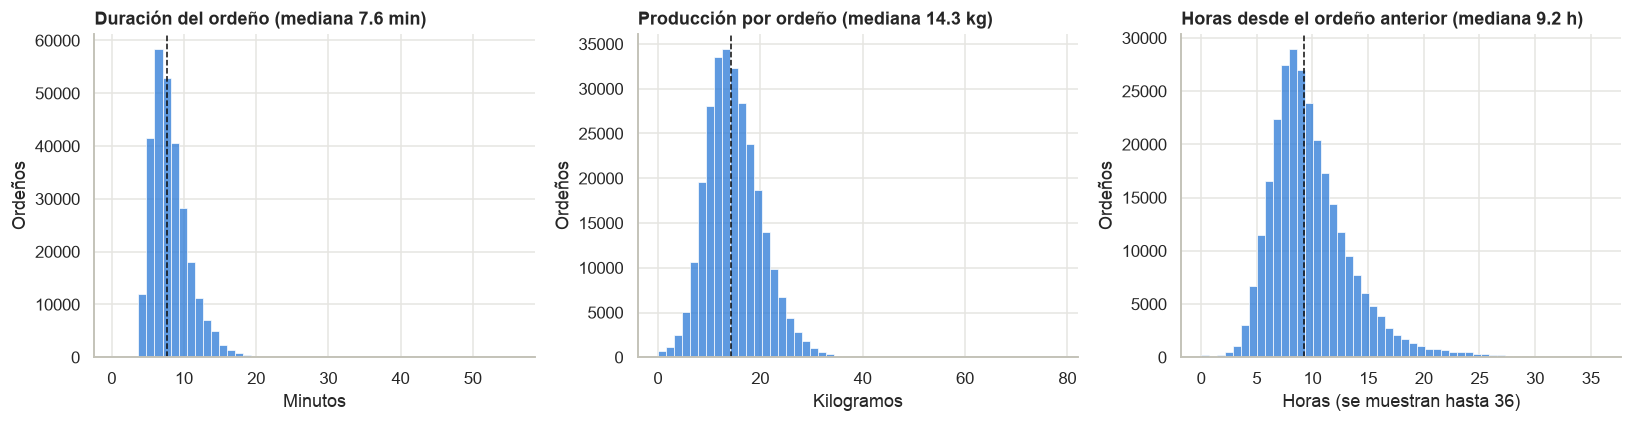

Intervalos de más de 36 h entre ordeños: 633


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(ordenos_ses["duracion_min"], bins=50, color=AZUL, ax=axes[0])
axes[0].axvline(ordenos_ses["duracion_min"].median(), color="#0b0b0b", linestyle="--", linewidth=1)
axes[0].set_title(f"Duración del ordeño (mediana {ordenos_ses['duracion_min'].median():.1f} min)")
axes[0].set_xlabel("Minutos")

sns.histplot(ordenos_ses["main_produccion_kg"], bins=50, color=AZUL, ax=axes[1])
axes[1].axvline(ordenos_ses["main_produccion_kg"].median(), color="#0b0b0b", linestyle="--", linewidth=1)
axes[1].set_title(f"Producción por ordeño (mediana {ordenos_ses['main_produccion_kg'].median():.1f} kg)")
axes[1].set_xlabel("Kilogramos")

intervalo = ordenos_ses["horas_desde_anterior"].dropna()
sns.histplot(intervalo[intervalo <= 36], bins=50, color=AZUL, ax=axes[2])
axes[2].axvline(intervalo.median(), color="#0b0b0b", linestyle="--", linewidth=1)
axes[2].set_title(f"Horas desde el ordeño anterior (mediana {intervalo.median():.1f} h)")
axes[2].set_xlabel("Horas (se muestran hasta 36)")

for ax in axes:
    ax.set_ylabel("Ordeños")
plt.tight_layout()
plt.show()

print(f"Intervalos de más de 36 h entre ordeños: {(intervalo > 36).sum()}")

**Observaciones:** Las tres variables son asimétricas a la derecha. La mitad central de los ordeños dura entre 6.3 y 9.4 min (mediana de 7.6), produce entre 11.1 y 18.1 kg (mediana de 14.3) y ocurre entre 7.4 y 11.7 h después del anterior (mediana de 9.2). Las colas largas son poco frecuentes pero existen: ordeños de hasta 56 min, 633 intervalos de más de 36 h entre ordeños de una misma vaca y 166 ordeños con 0 kg. Conviene revisar esos extremos antes de modelar, porque un ordeño muy largo ocupa la máquina mucho más de lo normal.

### 6.2 Uso de las máquinas

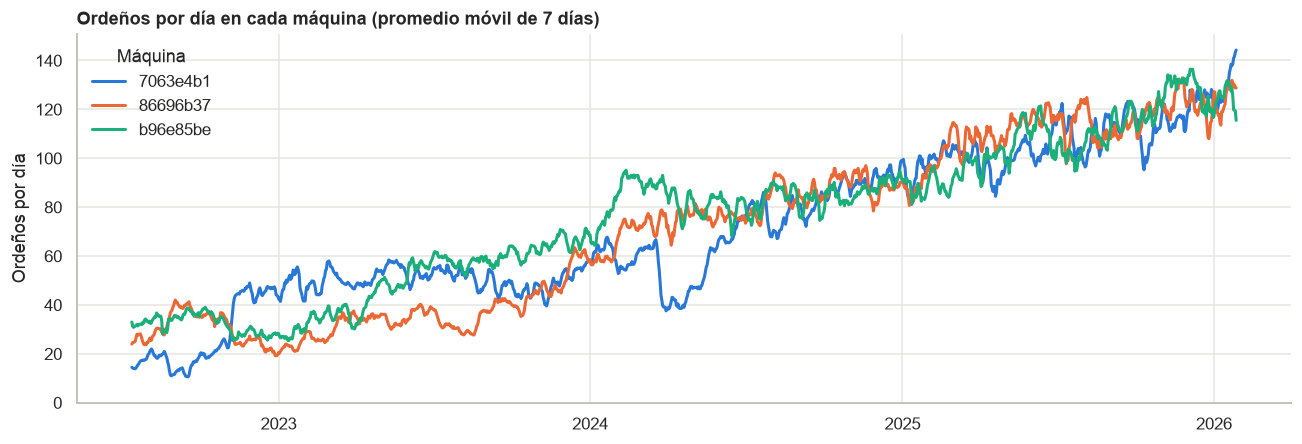

Vacas distintas por semana en cada máquina (una semana de cada 13; la primera y la ultima semanas estan incompletas):


misc_eo_po,7063e4b1,86696b37,b96e85be
2022-07-11,5,13,16
2022-10-10,10,15,18
2023-01-09,25,10,12
2023-04-10,19,16,20
2023-07-10,25,13,25
2023-10-09,20,16,25
2024-01-08,37,23,32
2024-04-08,17,37,47
2024-07-08,37,32,37
2024-10-07,35,34,33


In [21]:
# Ordeños por dia en cada maquina (se quita el ultimo dia, que esta incompleto)
dias_completos = pd.date_range(sesiones["fecha"].min(), sesiones["fecha"].max())[:-1]
por_dia = (ordenos_ses.groupby(["fecha", "misc_eo_po"]).size().unstack(fill_value=0)
           .reindex(index=dias_completos, columns=maquinas, fill_value=0))

fig, ax = plt.subplots(figsize=(12, 4.2))
for maquina in maquinas:
    ax.plot(por_dia.index, por_dia[maquina].rolling(7, min_periods=3, center=True).mean(),
            color=color_maquina[maquina], linewidth=2, label=maquina)
ax.set_title("Ordeños por día en cada máquina (promedio móvil de 7 días)")
ax.set_ylabel("Ordeños por día")
ax.set_ylim(0, None)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(title="Máquina", frameon=False)
plt.tight_layout()
plt.show()

print("Vacas distintas por semana en cada máquina (una semana de cada 13; la primera y la ultima semanas estan incompletas):")
por_semana = (ordenos_ses.groupby([ordenos_ses["inicio"].dt.to_period("W").dt.start_time, "misc_eo_po"])["id_vaca"]
              .nunique().unstack(fill_value=0))
por_semana.index = por_semana.index.date
por_semana.iloc[::13]

**Observaciones:** Las tres máquinas atienden una carga parecida y creciente: pasaron de 14 a 31 ordeños diarios en julio de 2022 a entre 120 y 141 en enero de 2026 (promedio móvil de 7 días), y las vacas distintas por semana en cada máquina subieron de 5–16 a 51–68. La máquina `7063e4b1` cae a unos 38 ordeños diarios a finales de marzo de 2024, contra unos 63 a mediados de febrero, una baja que conviene revisar con el cliente (mantenimiento o falla). Como el hato creció de 34 a 182 vacas con las mismas tres máquinas (sección 7), la carga de cada máquina es lo que determina la cola.

## 7. Clima, correlación y cola

Con el dataset unificado se agregan el clima por hora de NASA POWER (hora local), la matriz de correlación y el análisis de la cola entre una vaca y la siguiente.

In [22]:
# Ordeños del historial completo (df ya unifica el csv y el xlsx)
ordenos = df[df["main_accion"] == "Ordeño"].sort_values(["id_vaca", "inicio"]).copy()
ordenos["fin"] = ordenos["inicio"] + pd.to_timedelta(ordenos["duracion_seg"], unit="s")
ordenos["duracion_min"] = ordenos["duracion_seg"] / 60
ordenos["horas_desde_anterior"] = ordenos.groupby("id_vaca")["inicio"].diff().dt.total_seconds() / 3600

maquinas = ordenos["misc_eo_po"].value_counts().loc[lambda s: s > 100].index.tolist()   # una "maquina" tiene solo 2 registros
ordenos = ordenos[ordenos["misc_eo_po"].isin(maquinas)].reset_index(drop=True)
print(f"Ordeños: {len(ordenos):,} | vacas: {ordenos['id_vaca'].nunique()} | máquinas: {len(maquinas)} | "
      f"{ordenos['inicio'].min():%d/%m/%Y} a {ordenos['inicio'].max():%d/%m/%Y}")

Ordeños: 280,697 | vacas: 207 | máquinas: 3 | 13/07/2022 a 28/01/2026


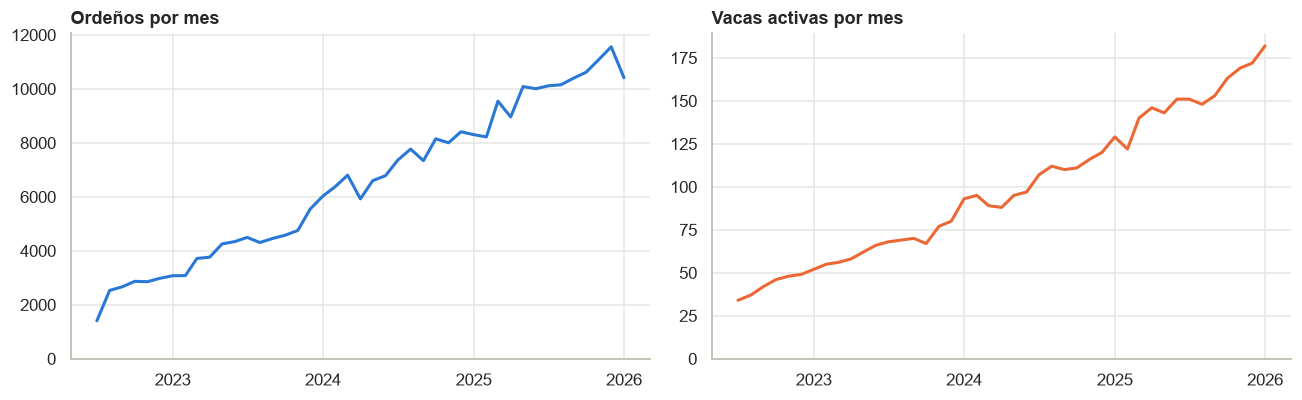

,ordeños,vacas
inicio,,
2022-07-01,1406,34
2025-12-01,11559,172
2026-01-01,10414,182


In [23]:
# Crecimiento del hato: ordeños y vacas activas por mes
mensual = ordenos.groupby(ordenos["inicio"].dt.to_period("M").dt.to_timestamp()).agg(ordeños=("id_vaca", "size"), vacas=("id_vaca", "nunique"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(mensual.index, mensual["ordeños"], color=AZUL, linewidth=2); axes[0].set_title("Ordeños por mes")
axes[1].plot(mensual.index, mensual["vacas"], color=NARANJA, linewidth=2); axes[1].set_title("Vacas activas por mes")
for ax in axes:
    ax.set_ylim(0, None)
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

# Julio de 2022 y enero de 2026 estan incompletos (empiezan el dia 13 y terminan el 28)
mensual.iloc[[0, -2, -1]]

Clima: 31,104 horas | 13/07/2022 a 28/01/2026 | nulos: 0


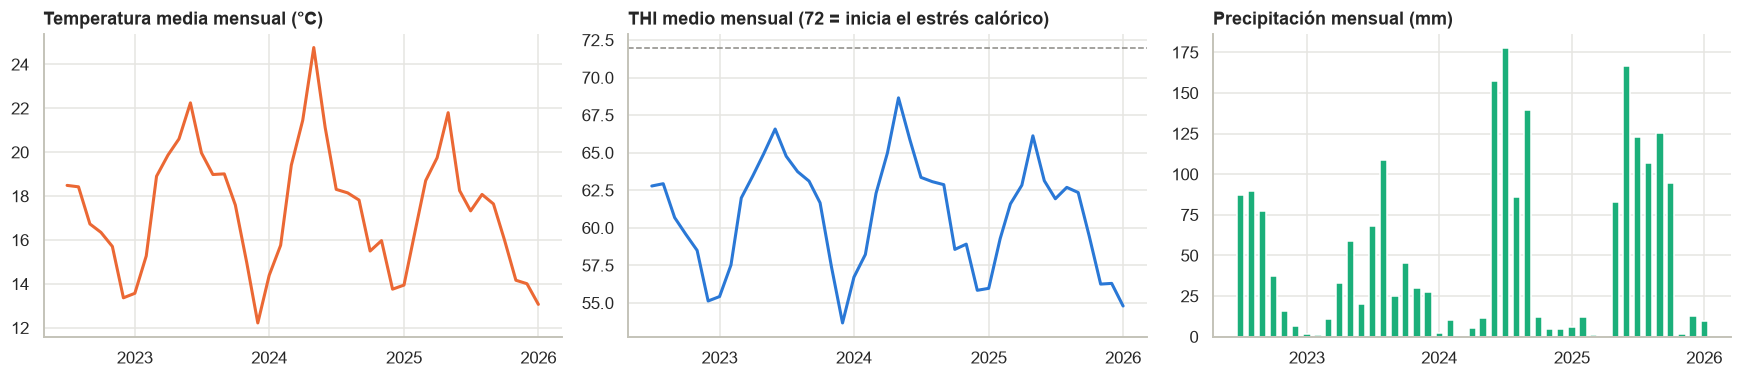

,mean,std,min,max
t2m,17.39,6.32,0.60,35.91
rh2m,61.38,28.46,2.94,100.00
t2mdew,7.61,5.90,-16.82,17.68
t2mwet,12.50,3.89,-3.25,20.80
qv2m,8.83,3.07,0.97,16.08
ps,79.01,0.20,78.04,79.78
ws2m,2.38,1.37,0.02,10.41
ws10m,3.46,1.73,0.04,14.26
wd10m,134.99,92.85,0.00,359.80
prectotcorr,0.07,0.23,0.00,10.27


In [24]:
# EDA del clima (NASA POWER, hora local)
clima = pd.read_csv(raiz / "Data" / "clima" / "clima_nasa_power_por_hora.csv", parse_dates=["hora"])
# Indice de temperatura-humedad (THI): medida usual de estres calorico en vacas lecheras
clima["thi"] = (1.8 * clima["t2m"] + 32) - (0.55 - 0.0055 * clima["rh2m"]) * (1.8 * clima["t2m"] - 26)
print(f"Clima: {len(clima):,} horas | {clima['hora'].min():%d/%m/%Y} a {clima['hora'].max():%d/%m/%Y} | nulos: {clima.isna().sum().sum()}")

mes = clima.set_index("hora").resample("MS")
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
axes[0].plot(mes["t2m"].mean(), color=NARANJA, linewidth=2); axes[0].set_title("Temperatura media mensual (°C)")
axes[1].plot(mes["thi"].mean(), color=AZUL, linewidth=2); axes[1].axhline(72, color=GRIS, linestyle="--", linewidth=1)
axes[1].set_title("THI medio mensual (72 = inicia el estrés calórico)")
axes[2].bar(mes["prectotcorr"].sum().index, mes["prectotcorr"].sum().values, width=20, color=AQUA); axes[2].set_title("Precipitación mensual (mm)")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

clima.drop(columns="hora").describe().T[["mean", "std", "min", "max"]].round(2)

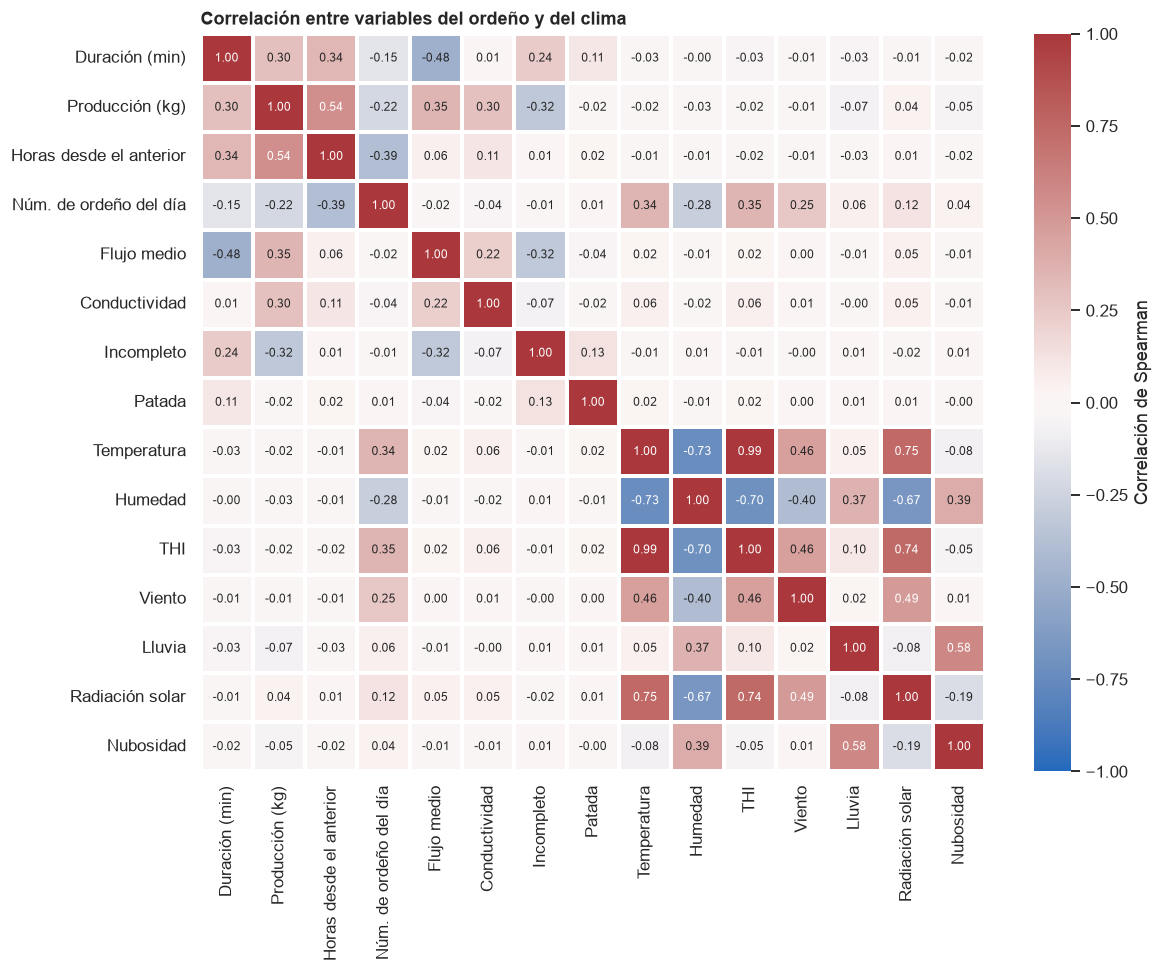

In [25]:
# Matriz de correlacion: ordeño + clima de la hora de inicio (Spearman, por la asimetria de las variables)
datos = ordenos.merge(clima, left_on=ordenos["inicio"].dt.floor("h"), right_on="hora", how="left", suffixes=("", "_clima")).drop(columns=["key_0"], errors="ignore")
cuartos = ["di", "dd", "ti", "td"]
conductividad = datos[[f"conductividad_ms_cm_{c}" for c in cuartos]].replace(0, np.nan)   # un 0 de conductividad es lectura faltante

variables = pd.DataFrame({
    "Duración (min)": datos["duracion_min"],
    "Producción (kg)": datos["main_produccion_kg"],
    "Horas desde el anterior": datos["horas_desde_anterior"],
    "Núm. de ordeño del día": datos["estado_numero_de_ordeno"],
    "Flujo medio": datos[[f"media_de_los_flujos_kg_min_{c}" for c in cuartos]].mean(axis=1),
    "Conductividad": conductividad.mean(axis=1),
    "Incompleto": datos["estado_incompleto"].notna().astype(int),
    "Patada": datos["estado_patada"].notna().astype(int),
    "Temperatura": datos["t2m"],
    "Humedad": datos["rh2m"],
    "THI": datos["thi"],
    "Viento": datos["ws2m"],
    "Lluvia": datos["prectotcorr"],
    "Radiación solar": datos["allsky_sfc_sw_dwn"],
    "Nubosidad": datos["cloud_amt"],
})

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(variables.corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
            linewidths=1.5, linecolor="white", annot_kws={"size": 8}, cbar_kws={"label": "Correlación de Spearman"}, ax=ax)
ax.set_title("Correlación entre variables del ordeño y del clima")
plt.tight_layout(); plt.show()

**Observaciones:** El clima casi no se relaciona con el ordeño: sus correlaciones con la producción, la duración, el flujo, la conductividad y los eventos de patada o incompleto son de 0.07 o menos en valor absoluto, así que el clima de la hora no explica por sí solo la producción ni los problemas. Lo que sí pesa es el propio proceso: la producción sube con las horas desde el ordeño anterior (0.54) y con la duración (0.30), y baja en los ordeños incompletos (−0.32), mientras que el flujo medio cae al alargarse el ordeño (−0.48). El número de ordeño del día correlaciona con la temperatura (0.34) probablemente por la hora del día y no por un efecto del calor, y como temperatura y THI son casi la misma variable (0.99), basta usar una.

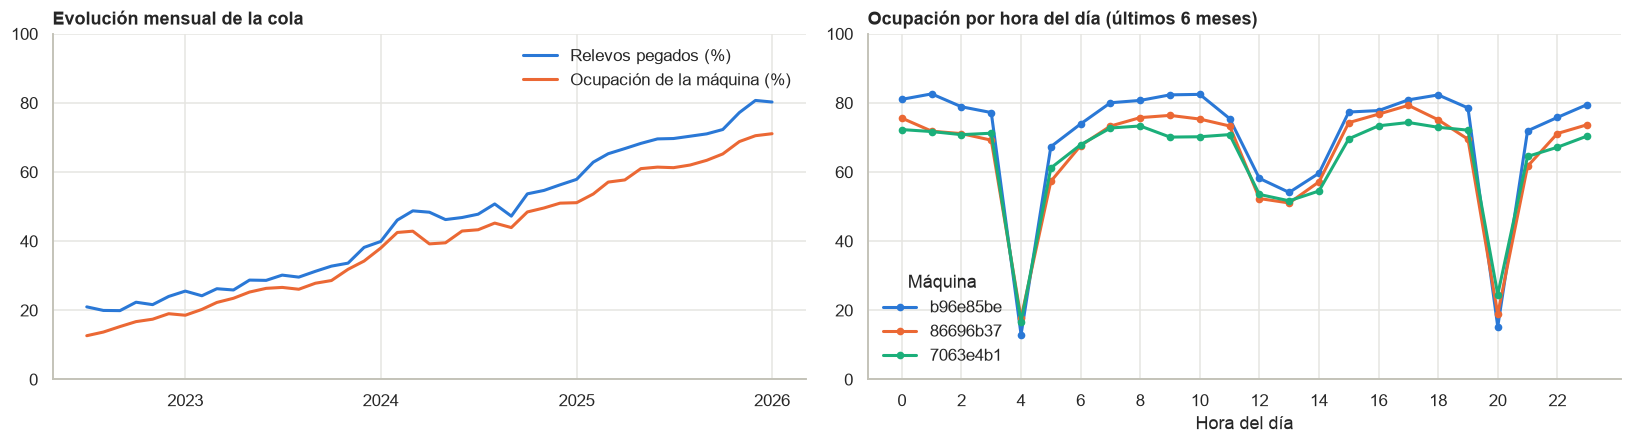

,ordeños_por_día,ocupación_%,relevos_pegados_%,hueco_mediano_min,espera_estimada_min
máquina,,,,,
b96e85be,125.8,73.4,84.3,0.5,12.9
86696b37,121.6,68.8,77.7,0.6,9.9
7063e4b1,121.5,66.6,75.2,0.5,8.8


In [26]:
# Cola: tiempo libre de la maquina = inicio de la vaca siguiente - (inicio + duracion) de la anterior
UMBRAL_MIN = 2   # un relevo a 2 min o menos del fin de la vaca anterior se considera "pegado"

cola = ordenos.sort_values(["misc_eo_po", "inicio", "fin"]).copy()
por_maquina = cola.groupby("misc_eo_po")
cola["hueco_min"] = ((cola["inicio"] - por_maquina["fin"].shift()).dt.total_seconds() / 60).clip(lower=0)
cola["vaca_anterior"] = por_maquina["id_vaca"].shift()
relevos = cola[cola["vaca_anterior"].notna() & (cola["vaca_anterior"] != cola["id_vaca"])].copy()
relevos["pegado"] = relevos["hueco_min"] <= UMBRAL_MIN

# Por mes: relevos pegados y ocupacion de las maquinas (promedio de las tres)
mes_r = relevos["inicio"].dt.to_period("M").dt.to_timestamp()
mes_o = ordenos["inicio"].dt.to_period("M").dt.to_timestamp()
dias_mes = ordenos.groupby(mes_o)["inicio"].apply(lambda s: s.dt.normalize().nunique())
ocupacion = ordenos.groupby(mes_o)["duracion_seg"].sum() / dias_mes / 86400 / len(maquinas) * 100
pegados = relevos.groupby(mes_r)["pegado"].mean() * 100

# Por hora del dia, ultimos 6 meses: ocupacion de cada maquina
reciente = ordenos[ordenos["inicio"] >= ordenos["inicio"].max() - pd.DateOffset(months=6)]
dias_rec = reciente["inicio"].dt.normalize().nunique()
por_hora = (reciente.groupby([reciente["inicio"].dt.hour, "misc_eo_po"])["duracion_seg"].sum().unstack() / dias_rec / 3600 * 100)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
axes[0].plot(pegados.index, pegados.values, color=AZUL, linewidth=2, label="Relevos pegados (%)")
axes[0].plot(ocupacion.index, ocupacion.values, color=NARANJA, linewidth=2, label="Ocupación de la máquina (%)")
axes[0].set_ylim(0, 100); axes[0].legend(frameon=False); axes[0].set_title("Evolución mensual de la cola")
axes[0].xaxis.set_major_locator(mdates.YearLocator()); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for maquina, color in zip(maquinas, [AZUL, NARANJA, AQUA]):
    axes[1].plot(por_hora.index, por_hora[maquina], color=color, linewidth=2, marker="o", markersize=4, label=maquina)
axes[1].set_xticks(range(0, 24, 2)); axes[1].set_ylim(0, 100); axes[1].legend(title="Máquina", frameon=False)
axes[1].set_title("Ocupación por hora del día (últimos 6 meses)"); axes[1].set_xlabel("Hora del día")
plt.tight_layout(); plt.show()

# Resumen de los ultimos 3 meses por maquina; espera estimada con la formula de Pollaczek-Khinchine (llegadas al azar)
ult = ordenos["inicio"] >= ordenos["inicio"].max() - pd.DateOffset(months=3)
dias_ult = ordenos.loc[ult, "inicio"].dt.normalize().nunique()
resumen = []
for maquina in maquinas:
    o = ordenos[ult & (ordenos["misc_eo_po"] == maquina)]
    r = relevos[(relevos["inicio"] >= o["inicio"].min()) & (relevos["misc_eo_po"] == maquina)]
    rho = o["duracion_seg"].sum() / dias_ult / 86400
    media, cv = o["duracion_min"].mean(), o["duracion_min"].std() / o["duracion_min"].mean()
    resumen.append({"máquina": maquina, "ordeños_por_día": len(o) / dias_ult, "ocupación_%": rho * 100,
                    "relevos_pegados_%": r["pegado"].mean() * 100, "hueco_mediano_min": r["hueco_min"].median(),
                    "espera_estimada_min": rho * media * (1 + cv ** 2) / (2 * (1 - rho))})
pd.DataFrame(resumen).set_index("máquina").round(1)

**Observaciones y conclusiones:** El historial creció de 34 a 182 vacas activas por mes (de 1.4 mil a 11.6 mil ordeños mensuales) con las mismas tres máquinas, y el clima casi no se relaciona con el ordeño (|r| ≤ 0.07 con producción, duración e incompletos), mientras que las horas desde el ordeño anterior sí (r = 0.54 con la producción). Sí hay problema de cola: entre 2022 y 2026 los relevos pegados pasaron de 21 % a 80 % y la ocupación de 13 % a 71 %; hoy cada máquina hace unos 120 ordeños al día, con 67–73 % de ocupación y una espera estimada de 9 a 13 min por vaca, y solo las paradas de las 4:00 y las 20:00 dan holgura. La espera es una estimación con llegadas al azar; para confirmarla falta la hora de llegada de cada vaca.

## 8. Sangre en la leche y mastitis

Se revisa qué tan seguido aparece sangre en la leche (`sangre_ppm_*`) y con qué frecuencia la conductividad es alta, que es el indicador que se usa para sospechar de mastitis. El dataset no trae una etiqueta de mastitis y el recuento de células somáticas está vacío, así que la conductividad alta es solo un indicador: no confirma la enfermedad, y el proyecto no hace diagnóstico veterinario.

In [27]:
# Sangre y conductividad por ordeño
cuartos = ["di", "dd", "ti", "td"]
UMBRAL_CONDUCTIVIDAD = 6.5   # mS/cm: valor de referencia de conductividad alta (por confirmar con el socio formador)

sangre = ordenos[[f"sangre_ppm_{c}" for c in cuartos]]
conductividad = ordenos[[f"conductividad_ms_cm_{c}" for c in cuartos]].replace(0, np.nan)   # un 0 es lectura faltante

ordenos["sangre_max"] = sangre.max(axis=1)
ordenos["con_sangre"] = ordenos["sangre_max"] > 0
ordenos["conductividad_alta"] = (conductividad >= UMBRAL_CONDUCTIVIDAD).any(axis=1)

filas = {}
for c in cuartos:
    s = ordenos[f"sangre_ppm_{c}"]
    filas[c.upper()] = {
        "ordeños con sangre (%)": (s > 0).mean() * 100,
        "mediana de ppm si hay sangre": s[s > 0].median(),
        "sangre de 1,000 ppm o más (%)": (s >= 1000).mean() * 100,
        f"conductividad ≥ {UMBRAL_CONDUCTIVIDAD} (%)": (conductividad[f"conductividad_ms_cm_{c}"] >= UMBRAL_CONDUCTIVIDAD).mean() * 100,
    }
filas["Cualquier cuarto"] = {
    "ordeños con sangre (%)": ordenos["con_sangre"].mean() * 100,
    "mediana de ppm si hay sangre": ordenos.loc[ordenos["con_sangre"], "sangre_max"].median(),
    "sangre de 1,000 ppm o más (%)": (ordenos["sangre_max"] >= 1000).mean() * 100,
    f"conductividad ≥ {UMBRAL_CONDUCTIVIDAD} (%)": ordenos["conductividad_alta"].mean() * 100,
}
pd.DataFrame(filas).T.round(1)

,ordeños con sangre (%),mediana de ppm si hay sangre,"sangre de 1,000 ppm o más (%)",conductividad ≥ 6.5 (%)
DI,2.6,553.0,0.8,0.7
DD,2.3,427.0,0.3,0.6
TI,1.4,436.0,0.2,0.6
TD,1.1,484.0,0.2,1.1
Cualquier cuarto,5.5,459.0,1.1,2.7


In [28]:
# A donde va la leche segun la sangre y la conductividad
grupos = {
    "Sin sangre": ordenos["sangre_max"] == 0,
    "Sangre de 1 a 500 ppm": ordenos["sangre_max"].between(1, 500),
    "Sangre de 501 a 1,000 ppm": ordenos["sangre_max"].between(501, 1000),
    "Sangre de más de 1,000 ppm": ordenos["sangre_max"] > 1000,
    f"Conductividad ≥ {UMBRAL_CONDUCTIVIDAD}": ordenos["conductividad_alta"],
}
destino = {}
for nombre, mascara in grupos.items():
    d = ordenos.loc[mascara, "misc_destino_leche"]
    destino[nombre] = {"ordeños": int(mascara.sum()), "Tanque (%)": (d == "Tanque").mean() * 100,
                       "Drenaje (%)": (d == "Drenaje").mean() * 100, "Divert 3 (%)": (d == "Divert 3").mean() * 100}
pd.DataFrame(destino).T.round(1).astype({"ordeños": int})

,ordeños,Tanque (%),Drenaje (%),Divert 3 (%)
Sin sangre,265381,96.0,3.6,0.5
Sangre de 1 a 500 ppm,8744,88.3,5.5,6.2
"Sangre de 501 a 1,000 ppm",3436,58.9,7.6,33.4
"Sangre de más de 1,000 ppm",3136,13.3,7.7,78.9
Conductividad ≥ 6.5,7611,84.9,12.7,2.4


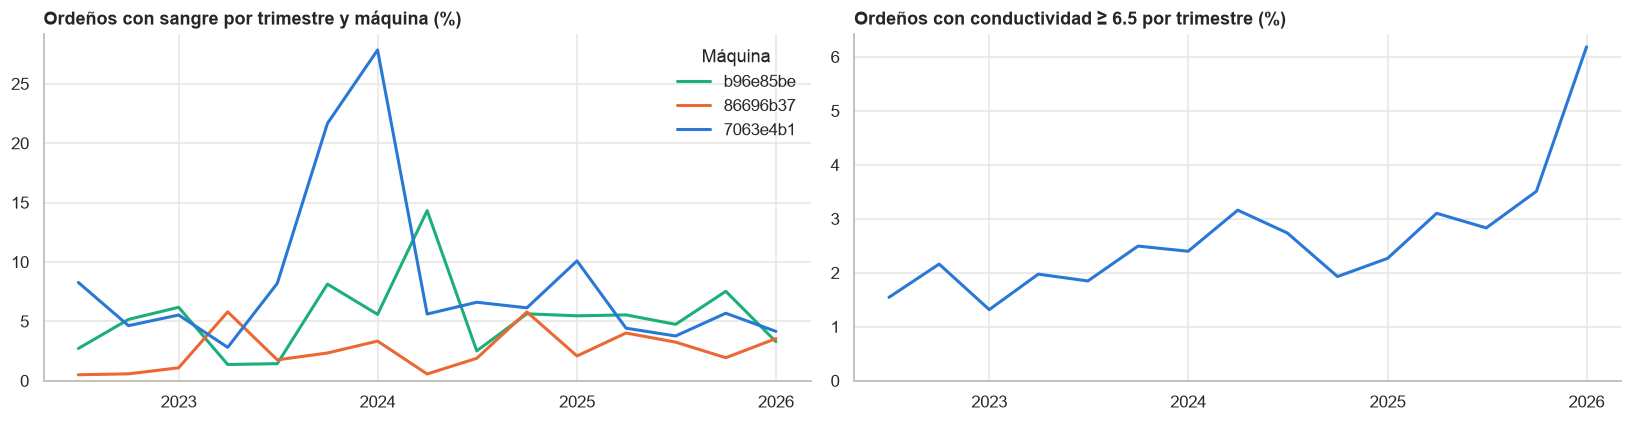

Los 3 trimestres con más ordeños con sangre (máquina, % de sus ordeños):
inicio      misc_eo_po
2024-01-01  7063e4b1      27.8
2023-10-01  7063e4b1      21.7
2024-04-01  b96e85be      14.3

Ordeños con conductividad alta por año (%):
inicio
2022    1.9
2023    2.0
2024    2.5
2025    3.0
2026    6.2

Vacas con al menos 200 ordeños en dos máquinas o más: 132
% de ordeños con sangre por máquina en esas mismas vacas:
misc_eo_po
7063e4b1    8.4
86696b37    2.9
b96e85be    6.4

Vacas con sangre alguna vez: 204 de 207 | con sangre en más del 5 % de sus ordeños: 88
Vacas con conductividad alta en más del 10 % de sus ordeños: 12 | las 10 vacas con más casos concentran 38% de los ordeños con conductividad alta


In [29]:
# Evolucion en el tiempo
trimestre = ordenos["inicio"].dt.to_period("Q").dt.to_timestamp()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

por_trimestre = ordenos.groupby([trimestre, "misc_eo_po"])["con_sangre"].mean().unstack() * 100
for maquina in maquinas:
    axes[0].plot(por_trimestre.index, por_trimestre[maquina], color=color_maquina[maquina], linewidth=2, label=maquina)
axes[0].set_title("Ordeños con sangre por trimestre y máquina (%)")
axes[0].legend(title="Máquina", frameon=False)

alta_trimestre = ordenos.groupby(trimestre)["conductividad_alta"].mean() * 100
axes[1].plot(alta_trimestre.index, alta_trimestre.values, color=AZUL, linewidth=2)
axes[1].set_title(f"Ordeños con conductividad ≥ {UMBRAL_CONDUCTIVIDAD} por trimestre (%)")

for ax in axes:
    ax.set_ylim(0, None)
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

print("Los 3 trimestres con más ordeños con sangre (máquina, % de sus ordeños):")
print(por_trimestre.stack().nlargest(3).round(1).to_string())
print("\nOrdeños con conductividad alta por año (%):")
print((ordenos.groupby(ordenos["inicio"].dt.year)["conductividad_alta"].mean() * 100).round(1).to_string())
print()

# La diferencia entre maquinas, es de las vacas? Se compara a las mismas vacas en distintas maquinas
base = ordenos.groupby(["id_vaca", "misc_eo_po"])["con_sangre"].agg(["mean", "size"]).reset_index()
base = base[base["size"] >= 200].pivot(index="id_vaca", columns="misc_eo_po", values="mean").dropna(thresh=2)
print(f"Vacas con al menos 200 ordeños en dos máquinas o más: {len(base)}")
print("% de ordeños con sangre por máquina en esas mismas vacas:")
print((base.mean() * 100).round(1).to_string())

# Estan concentradas en pocas vacas?
por_vaca = ordenos.groupby("id_vaca").agg(sangre=("con_sangre", "mean"), alta=("conductividad_alta", "mean"), n_alta=("conductividad_alta", "sum"))
print(f"\nVacas con sangre alguna vez: {(por_vaca['sangre'] > 0).sum()} de {len(por_vaca)} | con sangre en más del 5 % de sus ordeños: {(por_vaca['sangre'] > 0.05).sum()}")
print(f"Vacas con conductividad alta en más del 10 % de sus ordeños: {(por_vaca['alta'] > 0.1).sum()} | "
      f"las 10 vacas con más casos concentran {por_vaca['n_alta'].nlargest(10).sum() / por_vaca['n_alta'].sum():.0%} de los ordeños con conductividad alta")

**Observaciones:** Aparece sangre en 5.5 % de los ordeños y en 204 de las 207 vacas, más en los cuartos delanteros (2.6 % en DI) que en los traseros (1.1 % en TD); solo 1.1 % de los ordeños pasan de 1,000 ppm. La leche se desvía según la cantidad: con más de 1,000 ppm el 78.9 % va a `Divert 3` (0.5 % sin sangre), mientras que con conductividad ≥ 6.5 (2.7 % de los ordeños) lo que sube es el drenaje (12.7 % contra 3.6 %). La sangre tiene picos por máquina, de hasta 27.8 % de los ordeños en `7063e4b1` en el primer trimestre de 2024, y las mismas vacas dan 8.4 %, 2.9 % y 6.4 % según la máquina, así que conviene revisar esos sensores con el cliente. La conductividad alta subió de 1.9 % en 2022 a 3.0 % en 2025 y se concentra en pocas vacas (12 con más del 10 % de sus ordeños).

## 9. Eventos que no son ordeños normales

Se revisa qué tan frecuentes son los eventos que interrumpen o complican el ordeño: patada, ordeño incompleto, pezón no encontrado y alerta AMD, y cuáles ocurren juntos. Los rechazos y las visitas de «echada sin ordeñar» solo se registran en el csv de 2025, así que se miden aparte.

In [30]:
# Frecuencia de cada evento por ordeño
eventos = {"Patada": "estado_patada", "Incompleto": "estado_incompleto",
           "Pezón no encontrado": "estado_pezones_no_encontrados", "AMD pezón": "estado_amd_pezon"}
for nombre, columna in eventos.items():
    ordenos[nombre] = ordenos[columna].notna()
ordenos["AMD ubre"] = ordenos["estado_amd_ubre"] == 1


def porcentaje_cuarto(columna, cuarto):
    """% de los ordeños en los que el evento afecta a ese cuarto (la columna guarda la lista de cuartos o 'Todos')."""
    texto = ordenos[columna].fillna("")
    return (texto.str.contains(cuarto.upper()) | (texto == "Todos")).mean() * 100


filas = {}
for nombre, columna in eventos.items():
    por_vaca = ordenos.groupby("id_vaca")[nombre].mean()
    filas[nombre] = {
        "ordeños": int(ordenos[nombre].sum()),
        "% de los ordeños": ordenos[nombre].mean() * 100,
        **{f"{c.upper()} (%)": porcentaje_cuarto(columna, c) for c in cuartos},
        "duración con evento (min)": ordenos.loc[ordenos[nombre], "duracion_min"].median(),
        "duración sin evento (min)": ordenos.loc[~ordenos[nombre], "duracion_min"].median(),
        "vacas con el evento en más del 20 %": int((por_vaca > 0.2).sum()),
    }
filas["AMD ubre"] = {"ordeños": int(ordenos["AMD ubre"].sum()), "% de los ordeños": ordenos["AMD ubre"].mean() * 100}
alguno = ordenos[list(eventos)].any(axis=1)
filas["Al menos uno de los cuatro"] = {"ordeños": int(alguno.sum()), "% de los ordeños": alguno.mean() * 100}
tabla_eventos = pd.DataFrame(filas).T.round(1)
tabla_eventos.astype({"ordeños": "Int64", "vacas con el evento en más del 20 %": "Int64"})

,ordeños,% de los ordeños,DI (%),DD (%),TI (%),TD (%),duración con evento (min),duración sin evento (min),vacas con el evento en más del 20 %
Patada,45119,16.1,5.8,3.1,3.7,7.2,8.3,7.5,58
Incompleto,33517,11.9,2.5,2.3,5.4,5.6,9.5,7.4,40
Pezón no encontrado,33022,11.8,2.0,1.9,5.0,5.4,9.9,7.4,44
AMD pezón,26241,9.3,2.9,2.5,2.4,3.1,8.4,7.5,25
AMD ubre,34277,12.2,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
Al menos uno de los cuatro,91402,32.6,NaN,NaN,NaN,NaN,NaN,NaN,<NA>


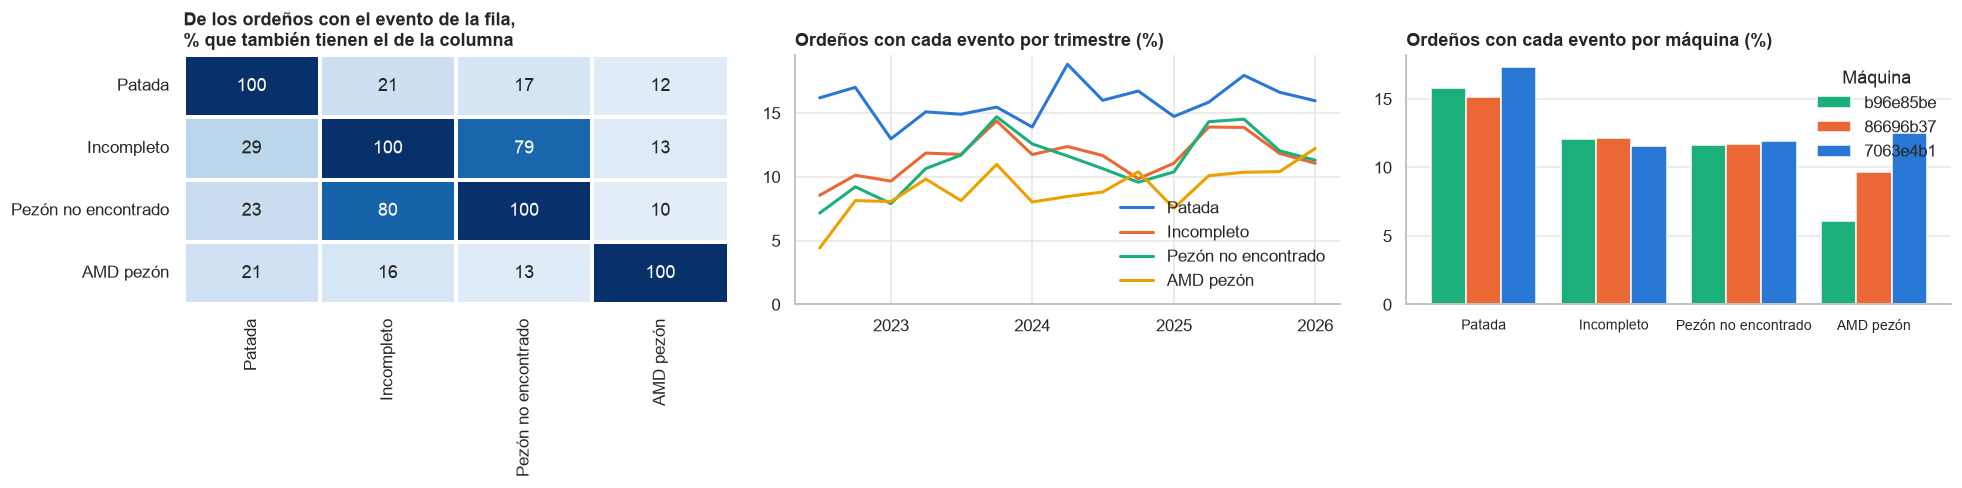

        Patada  Incompleto  Pezón no encontrado  AMD pezón
inicio                                                    
2022      16.7         9.4                  8.3        6.5
2023      14.7        12.1                 11.6        9.4
2024      16.4        11.3                 11.0        9.0
2025      16.4        12.7                 12.9        9.7
2026      16.0        11.1                 11.3       12.2



,Patada,Incompleto,Pezón no encontrado,AMD pezón
misc_eo_po,,,,
b96e85be,15.8,12.1,11.6,6.1
86696b37,15.1,12.1,11.7,9.7
7063e4b1,17.3,11.6,12.0,12.5


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
nombres = list(eventos)
color_evento = dict(zip(nombres, [AZUL, NARANJA, AQUA, "#eda100"]))

# Que eventos ocurren juntos
coincidencia = pd.DataFrame({b: {a: ordenos.loc[ordenos[a], b].mean() * 100 for a in nombres} for b in nombres})
sns.heatmap(coincidencia, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, linewidths=1.5, linecolor="white", cbar=False, ax=axes[0])
axes[0].set_title("De los ordeños con el evento de la fila,\n% que también tienen el de la columna")

# Evolucion por trimestre
por_trimestre = ordenos.groupby(trimestre)[nombres].mean() * 100
for nombre in nombres:
    axes[1].plot(por_trimestre.index, por_trimestre[nombre], color=color_evento[nombre], linewidth=2, label=nombre)
axes[1].set_title("Ordeños con cada evento por trimestre (%)")
axes[1].set_ylim(0, None); axes[1].legend(frameon=False)
axes[1].xaxis.set_major_locator(mdates.YearLocator()); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Por maquina
por_maquina_evento = ordenos.groupby("misc_eo_po")[nombres].mean().reindex(maquinas) * 100
x = np.arange(len(nombres))
for k, maquina in enumerate(maquinas):
    axes[2].bar(x + (k - 1) * 0.27, por_maquina_evento.loc[maquina], width=0.27, color=color_maquina[maquina], label=maquina)
axes[2].set_xticks(x, nombres, fontsize=9)
axes[2].set_title("Ordeños con cada evento por máquina (%)")
axes[2].legend(title="Máquina", frameon=False); axes[2].grid(axis="x", visible=False)

plt.tight_layout(); plt.show()

# Porcentaje de ordeños con cada evento por año y por maquina
print((ordenos.groupby(ordenos["inicio"].dt.year)[nombres].mean() * 100).round(1))
print()
(por_maquina_evento).round(1)

In [32]:
# Rechazos y echadas sin ordeñar: solo los registra el csv (marzo a julio de 2025, 34 vacas)
visitas_csv = bruto[bruto["fuente"] == "csv"]
resumen_visitas = visitas_csv["main_accion"].value_counts().to_frame("visitas")
resumen_visitas["%"] = (resumen_visitas["visitas"] / resumen_visitas["visitas"].sum() * 100).round(1)
resumen_visitas

,visitas,%
main_accion,,
Ordeño,7016,96.8
Rechazada,172,2.4
Echada sin ordeñar,61,0.8


**Observaciones:** Uno de cada tres ordeños (32.6 %) tiene al menos un evento: patada en 16.1 %, incompleto en 11.9 %, pezón no encontrado en 11.8 % y alerta AMD de pezón en 9.3 %. El incompleto y el pezón no encontrado son casi el mismo evento (79 y 80 % de coincidencia), afectan más a los cuartos traseros (5.0 a 5.6 % contra 1.9 a 2.5 % de los delanteros) y alargan el ordeño unos 2 min (9.5 y 9.9 contra 7.4 min). Las frecuencias son parecidas en las tres máquinas, salvo AMD pezón (de 6.1 % a 12.5 %), y subieron desde 2022 (el incompleto, de 9.4 % a 12.7 % en 2025); 40 vacas tienen incompletos en más del 20 % de sus ordeños, así que no es un problema de unas pocas. Los rechazos y las echadas sin ordeñar solo se registran en 2025: 2.4 % y 0.8 % de las visitas.

## 10. Preparación de la tabla de sesiones para el análisis profundo

Las secciones 10 a 17 reúnen los análisis de los demás EDA del equipo (los scripts `exploracion_datos.py`, `exploracion_profunda.py` y `EDA.py`, y los notebooks `dataUnderstanging.ipynb`, `eda_yael.ipynb` y `eda_data_understanding_integrado.ipynb`). Los análisis que ya existen arriba con la misma pregunta (nulos, duplicados, distribuciones principales, lactancia, uso de máquinas, prevalencia de eventos y matriz de correlación con clima) no se repiten: se conservó la versión de este notebook, que parte de los datos ya unificados.

Las funciones de los scripts de Python se copiaron tal cual y trabajan sobre una tabla `leche` con una fila por ordeño y nombres cortos (`milk_kg`, `kick`, `q_di`, ...). Aquí se construye esa tabla a partir de `ordenos`, que ya está depurada (sin duplicados entre fuentes y solo con las tres máquinas). La única diferencia es que `guardar` ahora muestra la figura en el notebook en lugar de escribirla a disco.

In [33]:
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

CUARTOS = ["di", "dd", "ti", "td"]
NOMBRE_CUARTO = {"di": "Del. izq.", "dd": "Del. der.", "ti": "Tras. izq.", "td": "Tras. der."}
EVENTOS = ["kick", "incomplete", "teat_missing"]
ETIQUETAS_EVENTO = {"kick": "Patada", "incomplete": "Ordeño incompleto", "teat_missing": "Pezón no encontrado"}
UMBRAL_THI = 68
UMBRAL_BRECHA_DIAS = 45
# Un intervalo de mas de 48 h es el regreso tras una brecha (periodo seco), no un intervalo de ordeño
UMBRAL_INTERVALO_H = 48
# NASA POWER etiqueta cada hora una hora antes del clima que describe
DESFASE_POWER_H = 1
SEMILLA = 42
Z95 = 1.96

# Mismos colores que el resto del notebook
COLOR_BASE, COLOR_ALERTA, COLOR_AUXILIAR, COLOR_GRIS = AZUL, NARANJA, "#eda100", "#c9d6d9"
COLORES_EVENTO = dict(zip(EVENTOS, [COLOR_BASE, COLOR_ALERTA, COLOR_AUXILIAR]))
VARIABLES_AGREGADAS = ["milk_kg", "duration_min", "interval_h", "flow_media", "cond_media", "mdi"]
ETIQUETAS_VARIABLE = {"milk_kg": "Producción (kg)", "duration_min": "Duración (min)", "interval_h": "Intervalo (h)",
                      "flow_media": "Flujo medio (kg/min)", "cond_media": "Conductividad media (mS/cm)", "mdi": "MDI"}


def guardar(fig, destino=None, nombre=None):
    """Muestra la figura en el notebook (en los scripts originales se guardaba como png)."""
    fig.tight_layout()
    plt.show()


def ver(resultado):
    """Muestra en una tabla el diccionario de resultados que devuelven las funciones."""
    display(pd.json_normalize(resultado, sep=" · ").T.rename(columns={0: "valor"}))


# Tabla de sesiones con los nombres cortos que usan los scripts
leche = pd.DataFrame({
    "animal_id": ordenos["id_vaca"],
    "timestamp": ordenos["inicio"],
    "milk_kg": ordenos["main_produccion_kg"],
    "session_no": ordenos["estado_numero_de_ordeno"],
    "duration_min": ordenos["duracion_min"],
    "interval_h": ordenos["horas_desde_anterior"],
    "machine": ordenos["misc_eo_po"],
    "destination": ordenos["misc_destino_leche"],
    "mdi": ordenos["estado_mdi"],
    "rcs": ordenos["estado_rcs_1000_celulas_ml"],
})
# Las banderas traen los cuartos afectados (DI, TD, Todos...): cualquier valor es un evento
for evento, columna in [("kick", "estado_patada"), ("incomplete", "estado_incompleto"),
                        ("teat_missing", "estado_pezones_no_encontrados")]:
    leche[evento] = ordenos[columna].notna().astype(int)
for corto, grupo in [("q", "producciones_kg"), ("flow", "media_de_los_flujos_kg_min"),
                     ("blood", "sangre_ppm"), ("cond", "conductividad_ms_cm")]:
    for c in CUARTOS:
        leche[f"{corto}_{c}"] = ordenos[f"{grupo}_{c}"]
leche = leche.dropna(subset=["timestamp", "milk_kg"]).reset_index(drop=True)
leche.attrs["intervalos_mayores_48h"] = int((leche["interval_h"] > UMBRAL_INTERVALO_H).sum())
leche["interval_h"] = leche["interval_h"].where(leche["interval_h"] <= UMBRAL_INTERVALO_H)

leche["fecha"] = leche["timestamp"].dt.normalize()
leche["hora"] = leche["timestamp"].dt.hour
leche["dia_semana"] = leche["timestamp"].dt.dayofweek
leche["mes"] = leche["timestamp"].dt.to_period("M").dt.to_timestamp()
leche["evento_alguno"] = leche[EVENTOS].max(axis=1)

# Un 0 en conductividad o flujo no es una medicion real: es un cuarto que no dio leche
for variable in ["cond", "flow"]:
    columnas = [f"{variable}_{c}" for c in CUARTOS]
    leche[f"{variable}_media"] = leche[columnas].where(leche[columnas] > 0).mean(axis=1)

print(f"Sesiones: {len(leche):,} | vacas: {leche['animal_id'].nunique()} | {leche['timestamp'].min():%d/%m/%Y} a {leche['timestamp'].max():%d/%m/%Y}")
print(f"Intervalos de más de 48 h tratados como faltantes (regreso tras un periodo seco): {leche.attrs['intervalos_mayores_48h']:,}")
leche[VARIABLES_AGREGADAS + EVENTOS].describe().T.round(2)

Sesiones: 280,697 | vacas: 207 | 13/07/2022 a 28/01/2026
Intervalos de más de 48 h tratados como faltantes (regreso tras un periodo seco): 420


,count,mean,std,min,25%,50%,75%,max
milk_kg,280697.0,14.82,5.34,0.00,11.07,14.29,18.10,78.17
duration_min,280697.0,8.10,2.58,0.38,6.25,7.60,9.40,55.80
interval_h,280071.0,9.92,3.86,0.01,7.41,9.21,11.64,47.92
flow_media,280533.0,1.19,0.32,0.06,0.96,1.18,1.40,4.62
cond_media,280491.0,4.95,0.48,0.40,4.64,4.93,5.23,11.22
mdi,257206.0,1.23,0.42,0.71,1.06,1.10,1.18,15.36
kick,280697.0,0.16,0.37,0.00,0.00,0.00,0.00,1.00
incomplete,280697.0,0.12,0.32,0.00,0.00,0.00,0.00,1.00
teat_missing,280697.0,0.12,0.32,0.00,0.00,0.00,0.00,1.00


## 11. Calidad, coherencia y valores extremos

Se revisa si los números son coherentes entre sí (por ejemplo, que la suma de los cuatro cuartos coincida con el total del ordeño), qué tan frecuentes son los valores fuera de rango y cómo se distribuyen las variables principales con colas largas.

### 11.1 Perfil de calidad de la tabla de sesiones

In [34]:
def perfilar_calidad(leche):
    """
        Calcula indicadores de calidad de la tabla: nulos, valores extremos, duplicados y brechas.

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.

        Returns:
            dict: Indicadores de calidad.
    """
    numericas = [c for c in leche.columns if c.startswith(("q_", "flow_", "blood_", "cond_"))] + \
                ["milk_kg", "duration_min", "interval_h", "mdi", "rcs", "session_no"]
    nulos = leche[numericas].isna().mean().mul(100).round(2)
    ordenado = leche.sort_values(["animal_id", "timestamp"])
    brechas = ordenado.groupby("animal_id")["timestamp"].diff().dt.days
    suma_cuartos = leche[[f"q_{c}" for c in CUARTOS]].sum(axis=1)
    return {
        "sesiones": len(leche),
        "vacas": int(leche["animal_id"].nunique()),
        "inicio": str(leche["timestamp"].min()),
        "fin": str(leche["timestamp"].max()),
        "nulos_pct": nulos[nulos > 0].sort_values(ascending=False).to_dict(),
        "duplicados_vaca_hora": int(leche.duplicated(["animal_id", "timestamp"]).sum()),
        "milk_kg_menor_igual_0": int((leche["milk_kg"] <= 0).sum()),
        "milk_kg_mayor_40": int((leche["milk_kg"] > 40).sum()),
        "duration_min_mayor_30": int((leche["duration_min"] > 30).sum()),
        "interval_h_menor_igual_0": int((leche["interval_h"] <= 0).sum()),
        "interval_h_mayor_24": int((leche["interval_h"] > 24).sum()),
        "interval_h_mayor_48_tratados_como_faltantes": leche.attrs["intervalos_mayores_48h"],
        "ceros_conductividad_pct": {c: round(float((leche[f"cond_{c}"] == 0).mean() * 100), 1) for c in CUARTOS},
        "ceros_produccion_cuarto_pct": {c: round(float((leche[f"q_{c}"] == 0).mean() * 100), 1) for c in CUARTOS},
        "suma_cuartos_difiere_mas_0_2kg": int(((suma_cuartos - leche["milk_kg"]).abs() > 0.2).sum()),
        "brechas_45_dias_o_mas": int((brechas >= UMBRAL_BRECHA_DIAS).sum()),
        "vacas_con_brecha": int(ordenado.loc[brechas >= UMBRAL_BRECHA_DIAS, "animal_id"].nunique()),
        "sesiones_por_vaca": leche.groupby("animal_id").size().describe().round(0).to_dict(),
        "sesiones_por_vms": leche["machine"].value_counts().to_dict(),
        "destino_leche": leche["destination"].value_counts().to_dict(),
    }


ver(perfilar_calidad(leche))

,valor
sesiones,280697
vacas,207
inicio,2022-07-13 00:05:28
fin,2026-01-28 11:47:54
duplicados_vaca_hora,0
milk_kg_menor_igual_0,164
milk_kg_mayor_40,55
duration_min_mayor_30,31
interval_h_menor_igual_0,0
interval_h_mayor_24,2444


### 11.2 Coherencia entre el total y los cuatro cuartos

Se revisan los ordeños con 0 kg (y si coinciden con pezones no encontrados), los valores negativos y los ordeños donde la suma de los cuartos no cuadra con la producción total (tolerancia de 0.05 kg).

In [35]:
clave = ["id_vaca", "main_hora_de_inicio"]
columnas_cuartos = [f"producciones_kg_{q}" for q in CUARTOS]
ordenos["suma_cuartos_kg"] = ordenos[columnas_cuartos].sum(axis=1, min_count=4)
ordenos["diferencia_total_kg"] = ordenos["main_produccion_kg"] - ordenos["suma_cuartos_kg"]

mediciones = [c for c in df.select_dtypes(include="number").columns
              if c.startswith(("main_produccion", "media_de_los_flujos", "sangre_", "conductividad_", "flujos_maximos_", "producciones_"))]
validaciones = pd.Series({
    "ordeños con producción cero": ordenos["main_produccion_kg"].eq(0).sum(),
    "ordeños con duración cero": ordenos["duracion_min"].eq(0).sum(),
    "filas con alguna medición negativa": df[mediciones].lt(0).any(axis=1).sum(),
    "ordeños con las cuatro producciones disponibles": ordenos["suma_cuartos_kg"].notna().sum(),
    "diferencia total vs suma de cuartos > 0.05 kg": ordenos["diferencia_total_kg"].abs().gt(0.05 + 1e-9).sum(),
})
display(validaciones.to_frame("filas"))

# Los ordeños con 0 kg: coinciden con "pezones no encontrados"?
pezones = ordenos["estado_pezones_no_encontrados"]
cero = ordenos["main_produccion_kg"].eq(0)
resumen_ceros = pd.Series({
    "Todos los pezones no encontrados": (cero & pezones.eq("Todos")).sum(),
    "Otros estados": (cero & pezones.notna() & pezones.ne("Todos")).sum(),
    "Sin dato de pezones": (cero & pezones.isna()).sum(),
}, name="ordeños con 0 kg")
resumen_ceros.loc["Total"] = cero.sum()
display(resumen_ceros.to_frame())

detalle = clave + ["main_duracion_mm_ss", "main_produccion_kg"] + columnas_cuartos + ["suma_cuartos_kg", "diferencia_total_kg",
                                                                                      "estado_incompleto", "estado_pezones_no_encontrados"]
print("Ordeños donde el total y la suma de los cuartos difieren más de 0.05 kg:")
ordenos.loc[ordenos["diferencia_total_kg"].abs().gt(0.05 + 1e-9), detalle].head(15)

,filas
ordeños con producción cero,164
ordeños con duración cero,0
filas con alguna medición negativa,0
ordeños con las cuatro producciones disponibles,252956
diferencia total vs suma de cuartos > 0.05 kg,9


,ordeños con 0 kg
Todos los pezones no encontrados,149
Otros estados,15
Sin dato de pezones,0
Total,164


Ordeños donde el total y la suma de los cuartos difieren más de 0.05 kg:


,id_vaca,main_hora_de_inicio,main_duracion_mm_ss,main_produccion_kg,producciones_kg_di,producciones_kg_dd,producciones_kg_ti,producciones_kg_td,suma_cuartos_kg,diferencia_total_kg,estado_incompleto,estado_pezones_no_encontrados
8209,047d18c1,2025-11-21 21:37:40,00:13:55,8.60,1.97,4.72,0.81,5.82,13.32,-4.72,NaN,NaN
23439,13819125,2024-09-24 16:07:33,00:12:58,9.54,2.52,2.59,2.83,4.13,12.07,-2.53,NaN,NaN
62145,373776f4,2024-07-09 13:41:41,00:13:56,15.01,4.71,4.47,4.48,5.82,19.48,-4.47,NaN,NaN
113240,609c6e22,2025-01-11 00:47:53,00:17:19,15.26,4.16,3.61,5.64,3.68,17.09,-1.83,NaN,NaN
113307,609c6e22,2025-02-19 10:36:54,00:12:09,8.01,1.63,2.89,3.48,2.90,10.90,-2.89,NaN,NaN
113586,609c6e22,2025-06-16 08:38:10,00:18:56,8.97,0.00,4.14,3.52,4.76,12.42,-3.45,NaN,DI
186135,a3c6cc07,2024-09-28 20:51:45,00:10:47,10.53,2.58,3.19,2.58,3.22,11.57,-1.04,NaN,NaN
186144,a3c6cc07,2024-10-03 16:44:31,00:15:20,7.34,1.93,2.03,2.10,3.31,9.37,-2.03,NaN,NaN
241480,dbac72bf,2024-09-29 02:04:46,00:09:37,6.63,3.02,2.77,0.58,2.80,9.17,-2.54,NaN,NaN


**Observaciones:** Los datos son coherentes en lo básico: no hay duraciones en cero, mediciones negativas ni duplicados de vaca y hora. Hay 164 ordeños con 0 kg y en 149 de ellos (91 %) el robot reporta «Todos» los pezones como no encontrados, así que son visitas donde no se logró ordeñar y no un error de captura. En 9 ordeños el total es menor que la suma de los cuatro cuartos (por ejemplo 8.60 kg contra 13.32 kg); es una diferencia de registro del robot y son tan pocos que se pueden marcar sin afectar el análisis. En cambio, la conductividad en 0 es un problema real: ocurre en 28.3 % de las lecturas del cuarto trasero derecho contra 1.7 % del delantero izquierdo.

### 11.3 Distribuciones, valores extremos y relación duración–producción

Histogramas en escala original y logarítmica con los atípicos por la regla de 1.5 IQR; después, la dispersión duración vs producción y la producción según haya ordeño incompleto.

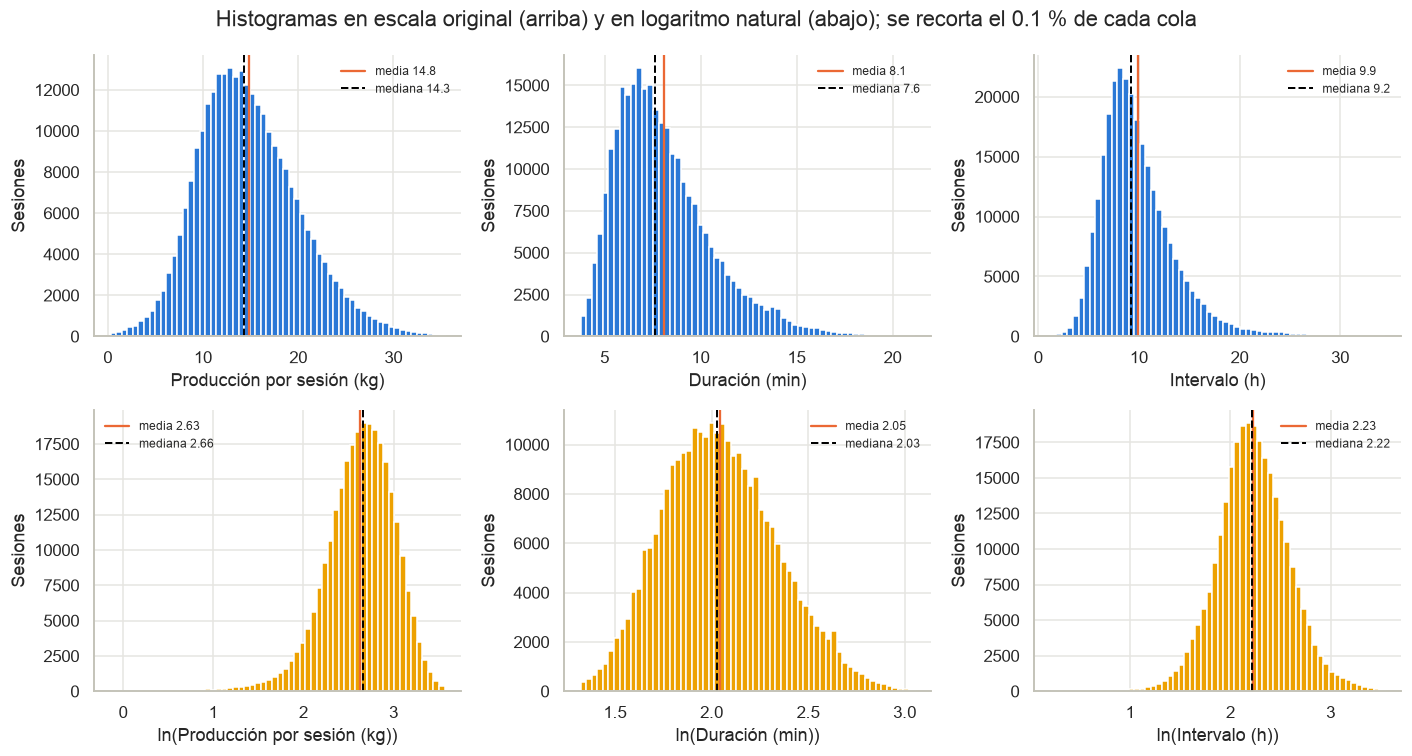

,valor
milk_kg · n,280697.000
milk_kg · media,14.820
milk_kg · mediana,14.290
milk_kg · desviacion,5.340
milk_kg · q1,11.070
milk_kg · q3,18.100
milk_kg · iqr,7.030
milk_kg · limite_bajo,0.520
milk_kg · limite_alto,28.650
milk_kg · atipicos_bajos,339.000


/var/folders/06/082vc2px7v791h689yrjpmv80000gn/T/ipykernel_47382/458074051.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=leche.assign(incompleto=leche["incomplete"].map({0: "Sin incompleto", 1: "Con incompleto"})),


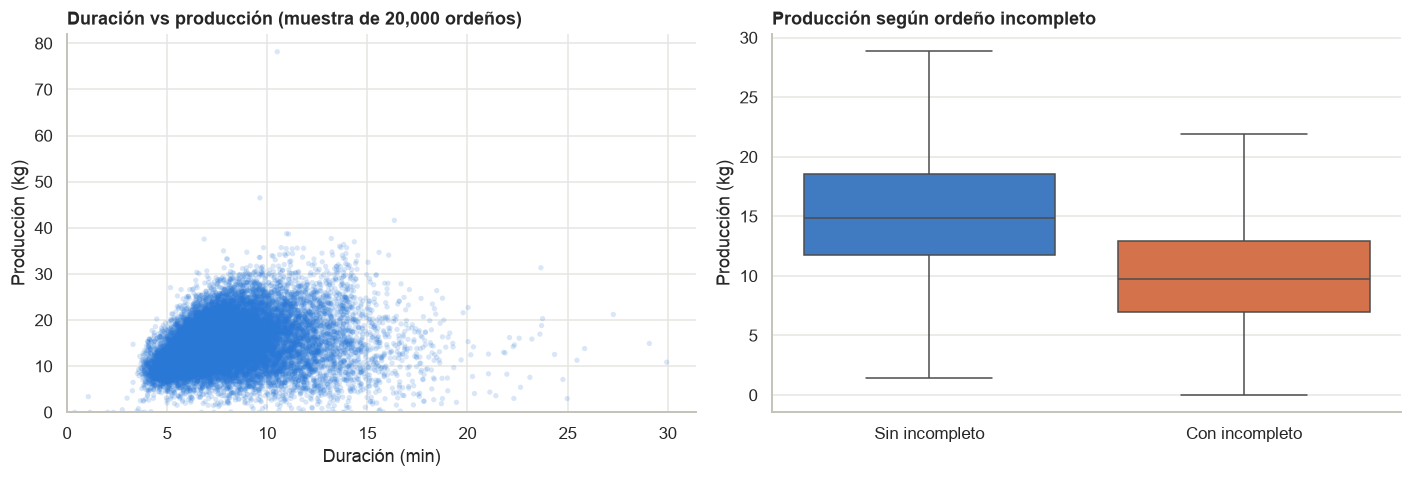

In [36]:
def describir_variables(leche, destino=None):
    """
        Calcula media, mediana, desviacion estandar, IQR y atipicos (1.5 IQR) de las variables con cola
        derecha, y grafica su histograma en escala original y en logaritmo.

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.
            destino (Path): Carpeta donde se guarda la imagen.

        Returns:
            dict: Estadisticos descriptivos y conteo de atipicos por variable.
    """
    variables = [("milk_kg", "Producción por sesión (kg)"), ("duration_min", "Duración (min)"),
                 ("interval_h", "Intervalo (h)")]
    resultado = {}
    fig, ejes = plt.subplots(2, 3, figsize=(13, 7))
    for columna, (variable, etiqueta) in enumerate(variables):
        serie = leche[variable].dropna()
        q1, q3 = serie.quantile([0.25, 0.75])
        iqr = q3 - q1
        bajo, alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        positiva = serie[serie > 0]
        resultado[variable] = {
            "n": int(len(serie)), "media": round(float(serie.mean()), 2), "mediana": round(float(serie.median()), 2),
            "desviacion": round(float(serie.std()), 2), "q1": round(float(q1), 2), "q3": round(float(q3), 2),
            "iqr": round(float(iqr), 2), "limite_bajo": round(float(bajo), 2), "limite_alto": round(float(alto), 2),
            "atipicos_bajos": int((serie < bajo).sum()), "atipicos_altos": int((serie > alto).sum()),
            "atipicos_pct": round(float(((serie < bajo) | (serie > alto)).mean() * 100), 2),
            "media_menos_mediana_pct": round(float((serie.mean() - serie.median()) / serie.median() * 100), 1),
            "log_media": round(float(np.log(positiva).mean()), 3), "log_mediana": round(float(np.log(positiva).median()), 3),
            "log_desviacion": round(float(np.log(positiva).std()), 3),
            "no_positivos_excluidos_del_log": int((serie <= 0).sum()),
        }
        recorte = serie[serie.between(serie.quantile(0.001), serie.quantile(0.999))]
        ejes[0, columna].hist(recorte, bins=60, color=COLOR_BASE)
        ejes[0, columna].axvline(serie.mean(), color=COLOR_ALERTA, linewidth=1.5, label=f"media {serie.mean():.1f}")
        ejes[0, columna].axvline(serie.median(), color="black", linestyle="--", linewidth=1.3,
                                 label=f"mediana {serie.median():.1f}")
        ejes[0, columna].set_xlabel(etiqueta)
        ejes[0, columna].set_ylabel("Sesiones")
        ejes[0, columna].legend(frameon=False, fontsize=8)

        logaritmo = np.log(positiva)
        logaritmo = logaritmo[logaritmo.between(logaritmo.quantile(0.001), logaritmo.quantile(0.999))]
        ejes[1, columna].hist(logaritmo, bins=60, color=COLOR_AUXILIAR)
        ejes[1, columna].axvline(logaritmo.mean(), color=COLOR_ALERTA, linewidth=1.5, label=f"media {logaritmo.mean():.2f}")
        ejes[1, columna].axvline(logaritmo.median(), color="black", linestyle="--", linewidth=1.3,
                                 label=f"mediana {logaritmo.median():.2f}")
        ejes[1, columna].set_xlabel(f"ln({etiqueta})")
        ejes[1, columna].set_ylabel("Sesiones")
        ejes[1, columna].legend(frameon=False, fontsize=8)
    fig.suptitle("Histogramas en escala original (arriba) y en logaritmo natural (abajo); se recorta el 0.1 % de cada cola")
    guardar(fig, destino, "eda_histogramas_log")
    return resultado


ver(describir_variables(leche))

# Dispersion duracion vs produccion y produccion segun ordeño incompleto
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
muestra = leche.sample(min(20000, len(leche)), random_state=SEMILLA)
axes[0].scatter(muestra["duration_min"], muestra["milk_kg"], s=12, alpha=0.18, color=AZUL, edgecolors="none")
axes[0].set(title="Duración vs producción (muestra de 20,000 ordeños)", xlabel="Duración (min)", ylabel="Producción (kg)",
            xlim=(0, None), ylim=(0, None))
sns.boxplot(data=leche.assign(incompleto=leche["incomplete"].map({0: "Sin incompleto", 1: "Con incompleto"})),
            x="incompleto", y="milk_kg", order=["Sin incompleto", "Con incompleto"], palette=[AZUL, NARANJA], showfliers=False, ax=axes[1])
axes[1].set(title="Producción según ordeño incompleto", xlabel="", ylabel="Producción (kg)")
plt.tight_layout(); plt.show()

### 11.4 Una misma variable en tres escalas: sesión, vaca-día y vaca-semana

La producción por sesión depende de cuántas veces ordeñó la vaca ese día. Agregarla por vaca-día o vaca-semana (solo semanas con al menos 6 días observados) cambia la forma y el sesgo de la distribución.

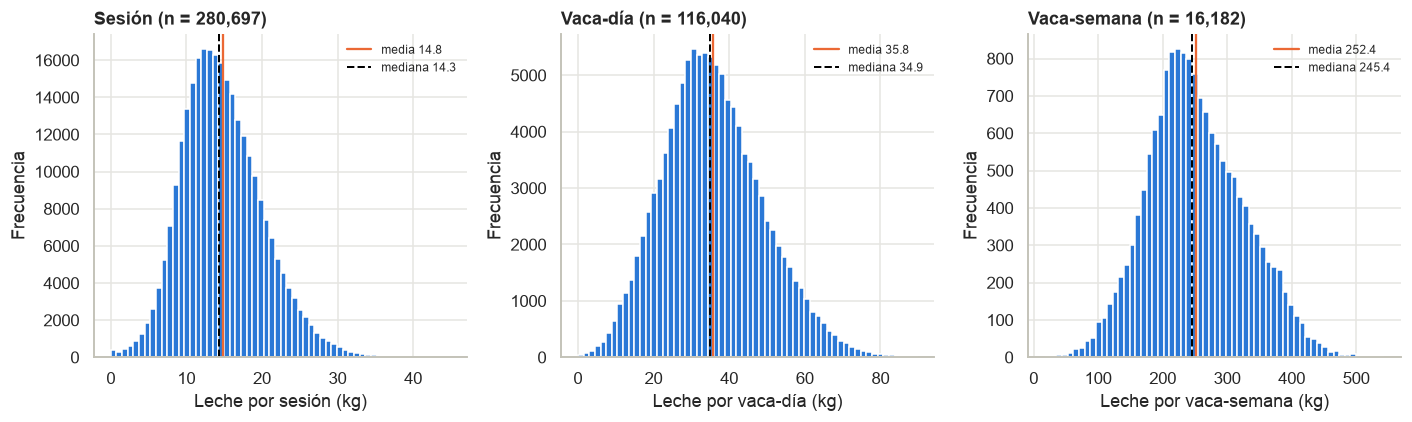

,valor
Sesión · n,280697.00
Sesión · media,14.82
Sesión · mediana,14.29
Sesión · desviacion,5.34
Sesión · iqr,7.03
Sesión · media_menos_mediana_pct,3.70
Vaca-día · n,116040.00
Vaca-día · media,35.84
Vaca-día · mediana,34.88
Vaca-día · desviacion,13.27


In [37]:
def comparar_escalas_temporales(leche, destino=None):
    """
        Compara la distribucion de la producción por sesion, por vaca-dia y por vaca-semana
        (solo semanas con al menos 6 dias observados).

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.
            destino (Path): Carpeta donde se guarda la imagen.

        Returns:
            dict: Media, mediana, desviacion y IQR de cada escala.
    """
    por_dia = leche.groupby(["animal_id", "fecha"]).agg(kg=("milk_kg", "sum"), sesiones=("milk_kg", "size")).reset_index()
    por_dia["semana"] = por_dia["fecha"].dt.to_period("W").dt.start_time
    por_semana = por_dia.groupby(["animal_id", "semana"]).agg(kg=("kg", "sum"), dias=("fecha", "nunique")).reset_index()
    por_semana = por_semana[por_semana["dias"] >= 6]

    escalas = [("Sesión", leche["milk_kg"].dropna(), (0, 45)), ("Vaca-día", por_dia["kg"], (0, 90)),
               ("Vaca-semana", por_semana["kg"], (0, 600))]
    resultado = {}
    fig, ejes = plt.subplots(1, 3, figsize=(13, 4))
    for eje, (nombre, serie, limites) in zip(ejes, escalas):
        q1, q3 = serie.quantile([0.25, 0.75])
        resultado[nombre] = {"n": int(len(serie)), "media": round(float(serie.mean()), 2),
                             "mediana": round(float(serie.median()), 2), "desviacion": round(float(serie.std()), 2),
                             "iqr": round(float(q3 - q1), 2),
                             "media_menos_mediana_pct": round(float((serie.mean() - serie.median()) / serie.median() * 100), 1)}
        eje.hist(serie[serie.between(*limites)], bins=60, color=COLOR_BASE)
        eje.axvline(serie.mean(), color=COLOR_ALERTA, linewidth=1.5, label=f"media {serie.mean():.1f}")
        eje.axvline(serie.median(), color="black", linestyle="--", linewidth=1.3, label=f"mediana {serie.median():.1f}")
        eje.set_xlabel(f"Leche por {nombre.lower()} (kg)")
        eje.set_ylabel("Frecuencia")
        eje.set_title(f"{nombre} (n = {len(serie):,})")
        eje.legend(frameon=False, fontsize=8)
    guardar(fig, destino, "eda_escalas_temporales")
    resultado["sesiones_por_vaca_dia"] = por_dia["sesiones"].value_counts(normalize=True).sort_index().mul(100).round(1).to_dict()
    return resultado


ver(comparar_escalas_temporales(leche))

**Observaciones:** La producción, la duración y el intervalo tienen cola larga hacia la derecha: la media supera a la mediana en 3.7 %, 6.5 % y 7.8 %, y la regla de 1.5 IQR marca como atípicos el 1.4 %, 2.7 % y 3.6 % de los ordeños. Las duraciones largas (hasta 55.8 min; 31 ordeños de más de 30 min) y la producción de más de 40 kg (55 ordeños) son raras, y en logaritmo las tres variables quedan casi simétricas (media y mediana de ln muy cercanas), lo que justifica transformarlas o usar métodos robustos. Un ordeño con incompleto produce menos y se queda en la misma zona de duración, no es un extremo aislado. Al agregar por vaca-día la mediana es de 34.9 kg y por vaca-semana de 245 kg, con sesgo de solo 2.8 %: el 45.5 % de los vaca-días tienen 2 ordeños y el 36.4 % tienen 3, así que la variabilidad de la producción por sesión viene en buena parte de cuántas veces se ordeñó ese día.

## 12. Patrones por hora, día de la semana, mes del año e intervalo

Complementa la sección 6: aquí se ve a qué horas y en qué días ordeñan las vacas, cuánto produce cada vaca por día a lo largo del historial (normalizado por el tamaño del hato) y cómo cambia la producción por ordeño con las horas transcurridas desde el ordeño anterior.

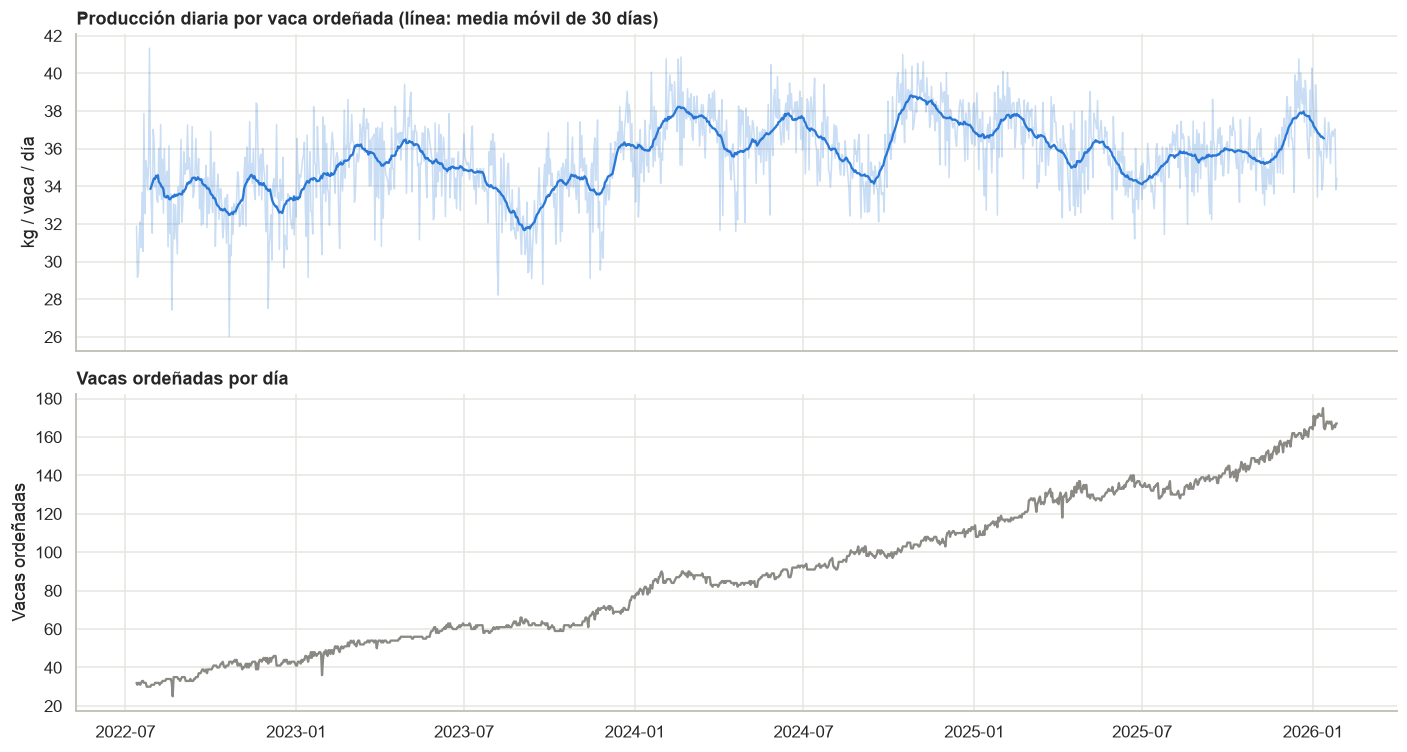

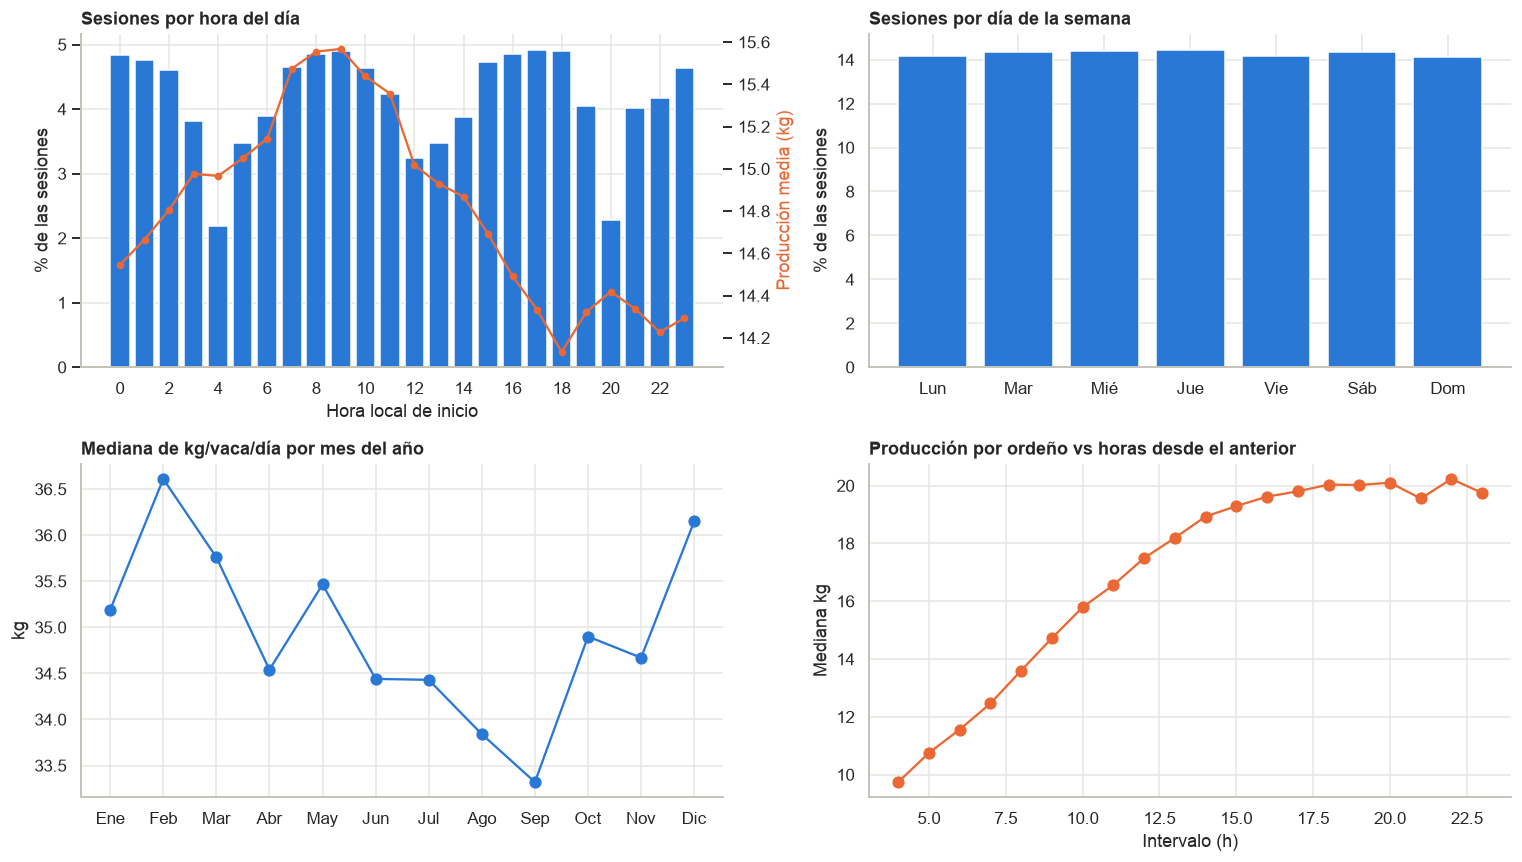

Horas con menos sesiones: [4, 20, 12] | hora con mayor producción media: 9
Vaca-días con producción: 116,033 vaca-días con producción | kg/vaca/día mensual entre 31.7 y 38.8


fecha,1,2,3,4,5,6,7,8,9,10,11,12
mediana kg/vaca/día,35.2,36.6,35.8,34.5,35.5,34.4,34.4,33.8,33.3,34.9,34.7,36.2


In [38]:
diario = leche.groupby("fecha").agg(produccion=("milk_kg", "sum"), vacas=("animal_id", "nunique"))
diario["kg_por_vaca"] = diario["produccion"] / diario["vacas"]
diario = diario[diario["vacas"] >= 5].iloc[:-1]   # se quita el ultimo dia, que esta incompleto

fig, ejes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ejes[0].plot(diario.index, diario["kg_por_vaca"], color=AZUL, alpha=0.25, linewidth=1)
ejes[0].plot(diario.index, diario["kg_por_vaca"].rolling(30, center=True).mean(), color=AZUL)
ejes[0].set_ylabel("kg / vaca / día")
ejes[0].set_title("Producción diaria por vaca ordeñada (línea: media móvil de 30 días)")
ejes[1].plot(diario.index, diario["vacas"], color=GRIS, linewidth=1.5)
ejes[1].set_ylabel("Vacas ordeñadas")
ejes[1].set_title("Vacas ordeñadas por día")
plt.tight_layout(); plt.show()

fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
por_hora = leche.groupby("hora").agg(sesiones=("milk_kg", "size"), media_kg=("milk_kg", "mean")).reindex(range(24))
ejes[0, 0].bar(por_hora.index, por_hora["sesiones"] / por_hora["sesiones"].sum() * 100, color=AZUL, width=0.8)
ejes[0, 0].set_xticks(range(0, 24, 2)); ejes[0, 0].set_xlabel("Hora local de inicio"); ejes[0, 0].set_ylabel("% de las sesiones")
ejes[0, 0].set_title("Sesiones por hora del día")
gemelo = ejes[0, 0].twinx()
gemelo.plot(por_hora.index, por_hora["media_kg"], color=NARANJA, marker="o", markersize=4)
gemelo.set_ylabel("Producción media (kg)", color=NARANJA); gemelo.grid(False)

dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_dia_sem = leche["dia_semana"].value_counts(normalize=True).sort_index() * 100
ejes[0, 1].bar(dias, por_dia_sem.values, color=AZUL)
ejes[0, 1].set_ylabel("% de las sesiones"); ejes[0, 1].set_title("Sesiones por día de la semana")

meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
vaca_dia = leche.groupby(["animal_id", "fecha"])["milk_kg"].sum().reset_index()
vaca_dia = vaca_dia[vaca_dia["milk_kg"] > 0]
por_mes = vaca_dia.groupby(vaca_dia["fecha"].dt.month)["milk_kg"].median()
ejes[1, 0].plot(por_mes.index, por_mes.values, color=AZUL, marker="o", markersize=7)
ejes[1, 0].set_xticks(range(1, 13), meses); ejes[1, 0].set_ylabel("kg")
ejes[1, 0].set_title("Mediana de kg/vaca/día por mes del año")

con_intervalo = leche[leche["interval_h"].between(4, 24)]
por_intervalo = con_intervalo.groupby(con_intervalo["interval_h"].astype(int))["milk_kg"].median()
ejes[1, 1].plot(por_intervalo.index, por_intervalo.values, color=NARANJA, marker="o", markersize=7)
ejes[1, 1].set_title("Producción por ordeño vs horas desde el anterior")
ejes[1, 1].set_xlabel("Intervalo (h)"); ejes[1, 1].set_ylabel("Mediana kg")
plt.tight_layout(); plt.show()

print(f"Horas con menos sesiones: {por_hora['sesiones'].nsmallest(3).index.tolist()} | hora con mayor producción media: {por_hora['media_kg'].idxmax()}")
print(f"Vaca-días con producción: {vaca_dia.shape[0]:,} vaca-días con producción | kg/vaca/día mensual entre "
      f"{diario['kg_por_vaca'].rolling(30, center=True).mean().min():.1f} y {diario['kg_por_vaca'].rolling(30, center=True).mean().max():.1f}")
por_mes.round(1).to_frame("mediana kg/vaca/día").T

**Observaciones:** La producción diaria por vaca ordeñada se mantiene entre 31.7 y 38.8 kg (media móvil de 30 días) aunque el hato creció, de modo que el crecimiento de la producción total se explica por tener más vacas y no por que cada vaca produzca más. Las horas con menos ordeños son 4, 20 y 12 h, pausas fijas de operación (limpieza o manejo del establo) que deben confirmarse con el cliente, y la mayor producción media por ordeño ocurre a las 9 h. Por mes del año la mediana va de 33.3 kg en septiembre a 36.6 kg en febrero (unos 10 % de diferencia), con mínimos en agosto-septiembre. El patrón más fuerte es el intervalo: la producción por ordeño crece de forma casi lineal con las horas desde el ordeño anterior, así que un ordeño «bajo» puede ser normal si el intervalo fue corto.

## 13. Cuartos de la ubre y robots

Se compara la producción, el flujo y la conductividad entre los cuatro cuartos; después, la producción por cuarto, los cuartos sin leche y la tasa de eventos entre robots con pruebas chi-cuadrada, y se mide si los cuartos sin leche se concentran en los ordeños con evento.

### 13.1 Medidas por cuarto

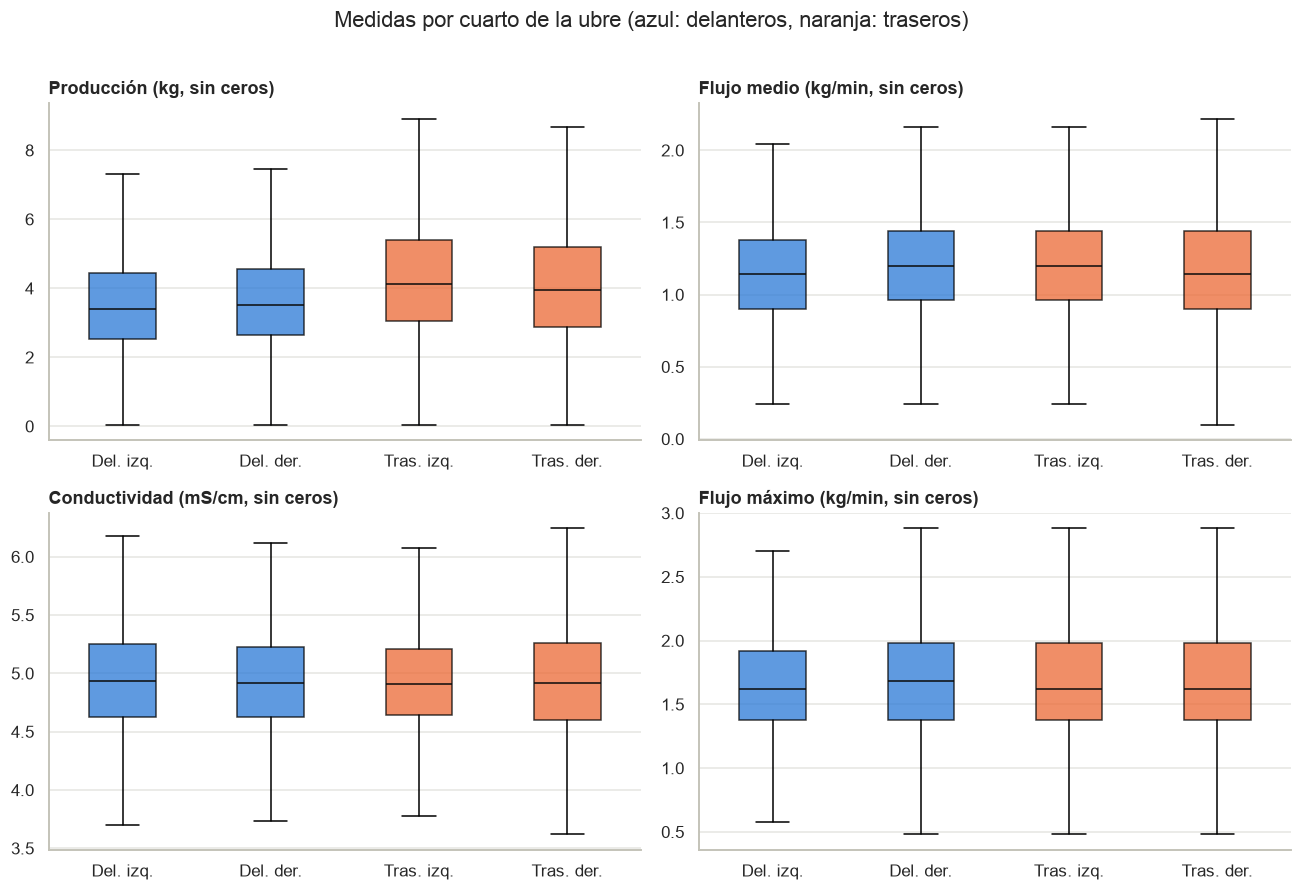

,Del. izq.,Del. der.,Tras. izq.,Tras. der.
producción mediana (kg),3.41,3.52,4.12,3.96
flujo medio mediano (kg/min),1.14,1.20,1.20,1.14
conductividad mediana (mS/cm),4.93,4.92,4.91,4.92


In [39]:
MEDIDAS_CUARTO = {
    "producciones_kg": "Producción (kg, sin ceros)",
    "media_de_los_flujos_kg_min": "Flujo medio (kg/min, sin ceros)",
    "conductividad_ms_cm": "Conductividad (mS/cm, sin ceros)",
    "flujos_maximos_kg_min": "Flujo máximo (kg/min, sin ceros)",
}
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (prefijo, nombre) in zip(ejes.flat, MEDIDAS_CUARTO.items()):
    datos_cuarto = [ordenos[f"{prefijo}_{c}"].where(ordenos[f"{prefijo}_{c}"] > 0).dropna() for c in CUARTOS]
    caja = ax.boxplot(datos_cuarto, tick_labels=[NOMBRE_CUARTO[c] for c in CUARTOS], showfliers=False,
                      patch_artist=True, medianprops={"color": "#0b0b0b"})
    for parche, color in zip(caja["boxes"], [AZUL, AZUL, NARANJA, NARANJA]):
        parche.set_facecolor(color)
        parche.set_alpha(0.75)
    ax.set_title(nombre)
    ax.grid(axis="x", visible=False)
fig.suptitle("Medidas por cuarto de la ubre (azul: delanteros, naranja: traseros)", y=1.01)
plt.tight_layout(); plt.show()

pd.DataFrame({NOMBRE_CUARTO[c]: {
    "producción mediana (kg)": ordenos[f"producciones_kg_{c}"].where(ordenos[f"producciones_kg_{c}"] > 0).median(),
    "flujo medio mediano (kg/min)": ordenos[f"media_de_los_flujos_kg_min_{c}"].where(ordenos[f"media_de_los_flujos_kg_min_{c}"] > 0).median(),
    "conductividad mediana (mS/cm)": ordenos[f"conductividad_ms_cm_{c}"].where(ordenos[f"conductividad_ms_cm_{c}"] > 0).median(),
} for c in CUARTOS}).round(2)

### 13.2 Producción por cuarto, cuartos sin leche y eventos por robot

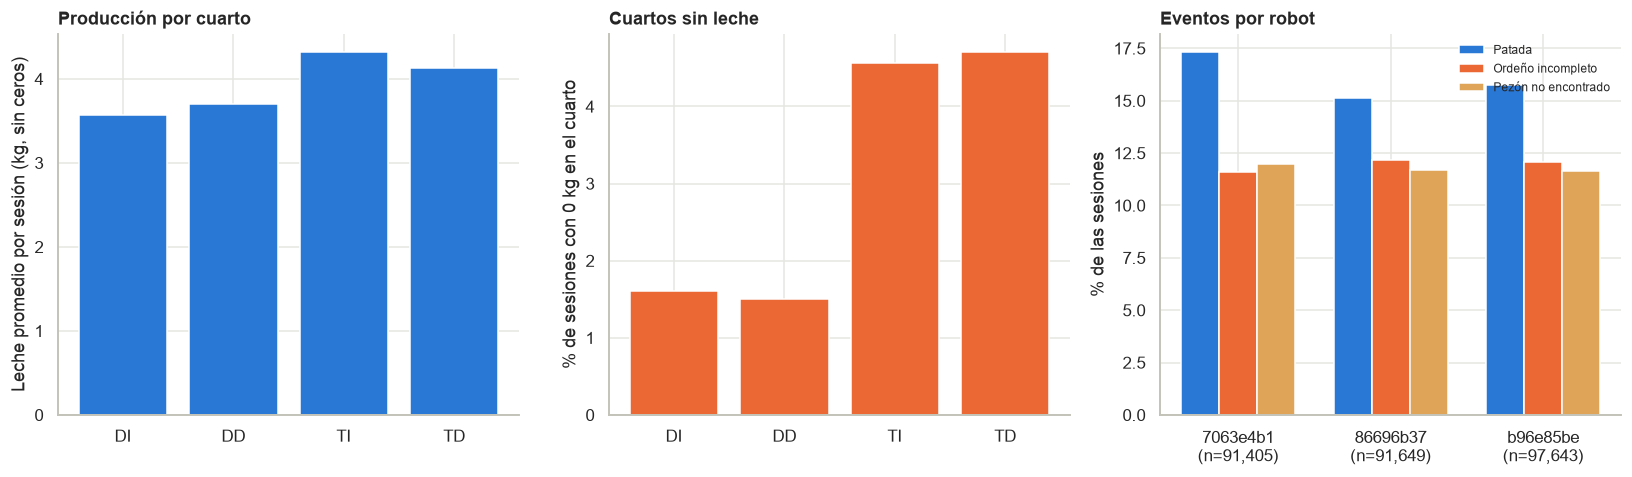

,valor
produccion_cuarto_kg · DI,3.570000e+00
produccion_cuarto_kg · DD,3.700000e+00
produccion_cuarto_kg · TI,4.320000e+00
produccion_cuarto_kg · TD,4.130000e+00
pct_cuarto_sin_leche · DI,1.600000e+00
pct_cuarto_sin_leche · DD,1.500000e+00
pct_cuarto_sin_leche · TI,4.600000e+00
pct_cuarto_sin_leche · TD,4.700000e+00
tasa_eventos_por_vms_pct · 7063e4b1 · kick,1.733000e+01
tasa_eventos_por_vms_pct · 7063e4b1 · incomplete,1.159000e+01


In [40]:
def graficar_cuartos_vms(leche, destino=None):
    """
        Compara la producción por cuarto y la tasa de eventos por robot, con pruebas chi-cuadrada.

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.
            destino (Path): Carpeta donde se guarda la imagen.

        Returns:
            dict: Tasas por robot y resultados de las pruebas.
    """
    produccion = {c.upper(): leche[f"q_{c}"].where(leche[f"q_{c}"] > 0).mean() for c in CUARTOS}
    sin_leche = {c.upper(): (leche[f"q_{c}"] == 0).mean() * 100 for c in CUARTOS}
    tasas = leche.groupby("machine")[EVENTOS].mean().mul(100)
    sesiones = leche["machine"].value_counts().sort_index()

    fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
    ejes[0].bar(produccion.keys(), produccion.values(), color=COLOR_BASE)
    ejes[0].set_ylabel("Leche promedio por sesión (kg, sin ceros)")
    ejes[0].set_title("Producción por cuarto")

    ejes[1].bar(sin_leche.keys(), sin_leche.values(), color=COLOR_ALERTA)
    ejes[1].set_ylabel("% de sesiones con 0 kg en el cuarto")
    ejes[1].set_title("Cuartos sin leche")

    ancho = 0.25
    posiciones = np.arange(len(tasas))
    for i, evento in enumerate(EVENTOS):
        ejes[2].bar(posiciones + (i - 1) * ancho, tasas[evento], ancho, label=ETIQUETAS_EVENTO[evento],
                    color=[COLOR_BASE, COLOR_ALERTA, "#e0a458"][i])
    ejes[2].set_xticks(posiciones)
    ejes[2].set_xticklabels([f"{m}\n(n={sesiones[m]:,})" for m in tasas.index])
    ejes[2].set_ylabel("% de las sesiones")
    ejes[2].set_title("Eventos por robot")
    ejes[2].legend(frameon=False, fontsize=8)
    guardar(fig, destino, "eda_cuartos_y_vms")

    pruebas = {}
    for evento in EVENTOS:
        tabla = pd.crosstab(leche["machine"], leche[evento])
        chi2, p, _, _ = stats.chi2_contingency(tabla)
        pruebas[evento] = {"chi2": round(float(chi2), 1), "p": float(p),
                           "cramer_v": round(float(np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))), 3)}
    return {"produccion_cuarto_kg": {k: round(float(v), 2) for k, v in produccion.items()},
            "pct_cuarto_sin_leche": {k: round(float(v), 1) for k, v in sin_leche.items()},
            "tasa_eventos_por_vms_pct": tasas.round(2).to_dict(orient="index"), "chi_cuadrada_vms": pruebas}


ver(graficar_cuartos_vms(leche))

In [41]:
def analizar_cuartos_sin_leche(leche):
    """
        Mide si los cuartos sin leche (0 kg) y las sesiones sin medida de flujo o conductividad se concentran
        en las sesiones con evento. Sirve para saber si el faltante es informativo y no debe imputarse sin mas.

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.

        Returns:
            dict: Por evento, % de sesiones con algun cuarto en 0 kg y % sin flujo medio, con y sin evento.
    """
    algun_cuarto_en_cero = (leche[[f"q_{c}" for c in CUARTOS]] == 0).any(axis=1)
    sin_flujo = leche["flow_media"].isna()
    resultado = {"sesiones_con_algun_cuarto_en_0kg_pct": round(float(algun_cuarto_en_cero.mean() * 100), 1),
                 "sesiones_sin_flujo_medio_pct": round(float(sin_flujo.mean() * 100), 2)}
    for evento in EVENTOS:
        con = leche[evento] == 1
        resultado[evento] = {
            "algun_cuarto_en_0kg_con_evento_pct": round(float(algun_cuarto_en_cero[con].mean() * 100), 1),
            "algun_cuarto_en_0kg_sin_evento_pct": round(float(algun_cuarto_en_cero[~con].mean() * 100), 1),
            "sin_flujo_medio_con_evento_pct": round(float(sin_flujo[con].mean() * 100), 2),
            "sin_flujo_medio_sin_evento_pct": round(float(sin_flujo[~con].mean() * 100), 2)}
    return resultado


ver(analizar_cuartos_sin_leche(leche))

,valor
sesiones_con_algun_cuarto_en_0kg_pct,10.20
sesiones_sin_flujo_medio_pct,0.06
kick · algun_cuarto_en_0kg_con_evento_pct,12.70
kick · algun_cuarto_en_0kg_sin_evento_pct,9.70
kick · sin_flujo_medio_con_evento_pct,0.00
kick · sin_flujo_medio_sin_evento_pct,0.07
incomplete · algun_cuarto_en_0kg_con_evento_pct,71.30
incomplete · algun_cuarto_en_0kg_sin_evento_pct,1.90
incomplete · sin_flujo_medio_con_evento_pct,0.45
incomplete · sin_flujo_medio_sin_evento_pct,0.00


**Observaciones:** Los cuartos traseros producen más (mediana de 4.1 y 4.0 kg contra 3.4 y 3.5 kg de los delanteros) con flujo y conductividad casi iguales (1.14 a 1.20 kg/min y 4.9 mS/cm), por lo que producen más porque se ordeñan más tiempo y no porque fluya más leche. También se quedan sin leche más veces: 4.6 y 4.7 % de los ordeños contra 1.5 y 1.6 % de los delanteros. Entre robots la tasa de eventos es parecida (patada 15.2 a 17.3 %, incompleto 11.6 a 12.2 %, pezón no encontrado 11.6 a 12.0 %); la prueba chi-cuadrada sale significativa para patada y para incompleto solo por el tamaño de la muestra, con efecto despreciable (V de Cramér de 0.025 y 0.008) y no significativa para pezón no encontrado, así que el robot no explica los eventos. Los cuartos sin leche sí son informativos: 71.3 % de los ordeños incompletos y 86.7 % de los de pezón no encontrado tienen algún cuarto en 0 kg, contra 1.9 % y 0 % sin el evento, por lo que ese cero no debe imputarse. Es distinto del cero de conductividad: aquel es un dato real (el cuarto no dio leche), mientras que un 0 de conductividad es una lectura que falló y se trata como faltante, como se explicó en la sección 3 (28 % de ceros en el cuarto trasero derecho, casi todos de la máquina `b96e85be`). Por eso las medianas de flujo y conductividad de la sección 13.1 se calculan sin ceros; la conductividad «casi igual» entre cuartos se refiere solo a las lecturas válidas.

## 14. Salud de la ubre: MDI, AMD y sangre por vaca

Se cruzan el MDI (índice de mastitis del robot), la conductividad máxima y la alerta AMD de ubre, y se revisa, para una vaca con historia larga, cómo cambia la producción cuando se detecta sangre en alguno de los cuatro cuartos. La conductividad de 0 se trata como lectura faltante.

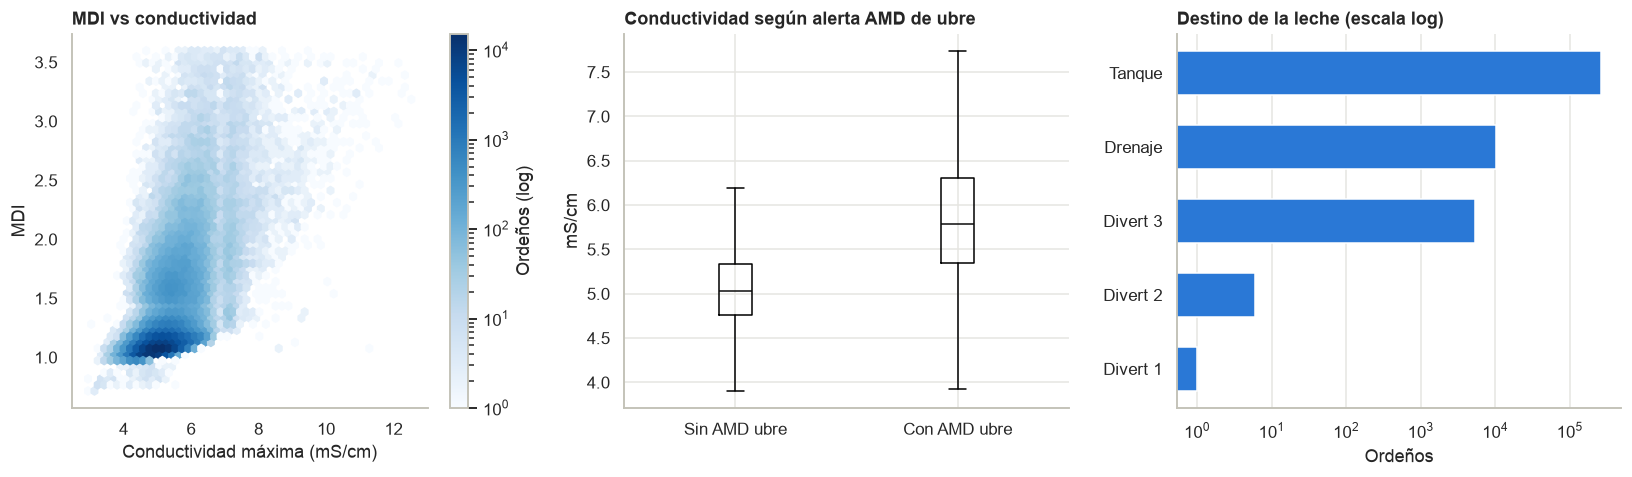

Mediana de conductividad máxima | sin AMD ubre: 5.03 | con AMD ubre: 5.79
Correlación de Spearman MDI vs conductividad máxima: 0.55


In [42]:
cond_cols = [f"conductividad_ms_cm_{c}" for c in CUARTOS]
ordenos["conductividad_max_ms_cm"] = ordenos[cond_cols].replace(0, np.nan).max(axis=1)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
muestra = ordenos.dropna(subset=["estado_mdi", "conductividad_max_ms_cm"])
muestra = muestra[muestra["estado_mdi"] < muestra["estado_mdi"].quantile(0.995)]
hexagonos = ejes[0].hexbin(muestra["conductividad_max_ms_cm"], muestra["estado_mdi"],
                           gridsize=50, cmap="Blues", mincnt=1, bins="log")
fig.colorbar(hexagonos, ax=ejes[0], label="Ordeños (log)")
ejes[0].set_xlabel("Conductividad máxima (mS/cm)"); ejes[0].set_ylabel("MDI"); ejes[0].set_title("MDI vs conductividad")
ejes[0].grid(False)

grupos = [ordenos.loc[ordenos["estado_amd_ubre"] == valor, "conductividad_max_ms_cm"].dropna() for valor in (0, 1)]
ejes[1].boxplot(grupos, tick_labels=["Sin AMD ubre", "Con AMD ubre"], showfliers=False, medianprops={"color": "#0b0b0b"})
ejes[1].set_title("Conductividad según alerta AMD de ubre"); ejes[1].set_ylabel("mS/cm")

destino_leche = ordenos["misc_destino_leche"].value_counts()
ejes[2].barh(destino_leche.index[::-1], destino_leche.values[::-1], color=AZUL, height=0.6)
ejes[2].set_xscale("log"); ejes[2].set_title("Destino de la leche (escala log)"); ejes[2].set_xlabel("Ordeños")
ejes[2].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print("Mediana de conductividad máxima | sin AMD ubre: %.2f | con AMD ubre: %.2f" % (grupos[0].median(), grupos[1].median()))
print("Correlación de Spearman MDI vs conductividad máxima: %.2f" % muestra["estado_mdi"].corr(muestra["conductividad_max_ms_cm"], method="spearman"))

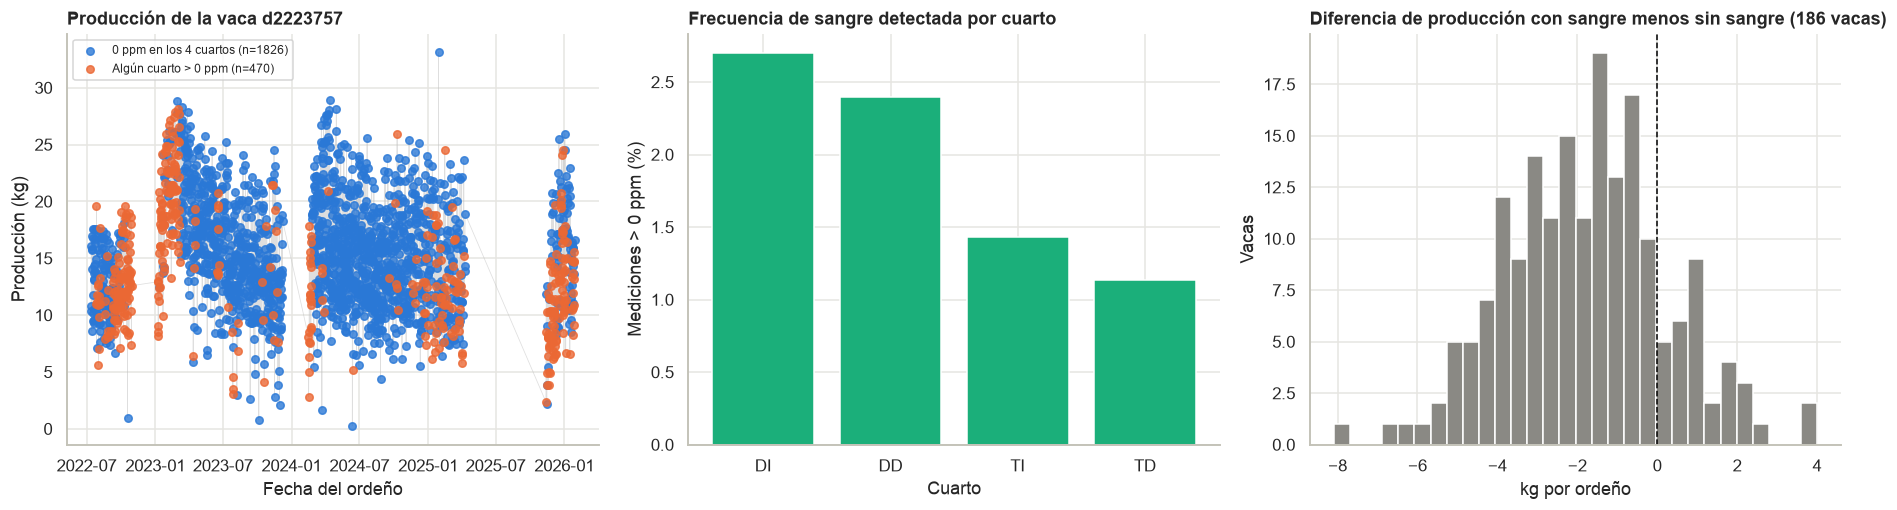

Comparación de 252,956 ordeños con cuatro mediciones; 27,741 excluidos por mediciones faltantes.
Diferencia mediana entre vacas: -1.70 kg | vacas que producen menos con sangre: 83%
Las diferencias son descriptivas: un valor > 0 ppm es una medición del sensor, no un diagnóstico ni prueba de causalidad.


In [43]:
# Produccion de una vaca con sangre detectada y sin ella, y diferencia por vaca
columnas_sangre = [f"sangre_ppm_{q}" for q in CUARTOS]
sangre = ordenos.loc[ordenos[columnas_sangre].notna().all(axis=1)].copy()
sangre["sangre_detectada"] = sangre[columnas_sangre].gt(0).any(axis=1)

# La vaca con mas ordeños con sangre y al menos 20 sin deteccion
conteos_vaca = sangre.groupby(["id_vaca", "sangre_detectada"]).size().unstack(fill_value=0).reindex(columns=[False, True], fill_value=0)
vacas_ejemplo = conteos_vaca.loc[conteos_vaca[False].ge(20) & conteos_vaca[True].gt(0)]
id_ejemplo = vacas_ejemplo[True].idxmax() if not vacas_ejemplo.empty else sangre["id_vaca"].value_counts().index[0]
serie_vaca = sangre.loc[sangre["id_vaca"].eq(id_ejemplo)].sort_values("inicio")

medias_vaca = sangre.groupby(["id_vaca", "sangre_detectada"])["main_produccion_kg"].agg(["mean", "size"]).unstack()
comparables = medias_vaca.loc[(medias_vaca[("size", True)] >= 5) & (medias_vaca[("size", False)] >= 20)]
diferencia_vaca = (comparables[("mean", True)] - comparables[("mean", False)]).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
ax.plot(serie_vaca["inicio"], serie_vaca["main_produccion_kg"], color="0.75", linewidth=0.5, alpha=0.5)
for detectada, color, etiqueta in [(False, AZUL, "0 ppm en los 4 cuartos"), (True, NARANJA, "Algún cuarto > 0 ppm")]:
    puntos = serie_vaca.loc[serie_vaca["sangre_detectada"].eq(detectada)]
    ax.scatter(puntos["inicio"], puntos["main_produccion_kg"], s=24, alpha=0.8, color=color, label=f"{etiqueta} (n={len(puntos)})", zorder=3)
ax.set(title=f"Producción de la vaca {id_ejemplo}", xlabel="Fecha del ordeño", ylabel="Producción (kg)")
ax.legend(fontsize=8)

tasas_cuarto = ordenos[columnas_sangre].gt(0).sum().div(ordenos[columnas_sangre].notna().sum()).mul(100)
axes[1].bar([q.upper() for q in CUARTOS], tasas_cuarto.values, color=AQUA)
axes[1].set(title="Frecuencia de sangre detectada por cuarto", xlabel="Cuarto", ylabel="Mediciones > 0 ppm (%)")

axes[2].hist(diferencia_vaca, bins=30, color=GRIS, edgecolor="white")
axes[2].axvline(0, color="black", linestyle="--", linewidth=1)
axes[2].set(title=f"Diferencia de producción con sangre menos sin sangre ({len(diferencia_vaca)} vacas)", xlabel="kg por ordeño", ylabel="Vacas")
plt.tight_layout(); plt.show()
print(f"Comparación de {len(sangre):,} ordeños con cuatro mediciones; {len(ordenos) - len(sangre):,} excluidos por mediciones faltantes.")
print(f"Diferencia mediana entre vacas: {diferencia_vaca.median():+.2f} kg | vacas que producen menos con sangre: {(diferencia_vaca < 0).mean():.0%}")
print("Las diferencias son descriptivas: un valor > 0 ppm es una medición del sensor, no un diagnóstico ni prueba de causalidad.")

**Observaciones:** MDI y conductividad máxima se mueven juntos (Spearman 0.55) y las visitas con alerta AMD de ubre tienen conductividad más alta (mediana de 5.79 contra 5.03 mS/cm), igual que lo visto en la sección 8: son indicadores que apuntan al mismo problema de salud de la ubre. En la comparación dentro de cada vaca, el 83 % de las vacas con historia suficiente produce menos en los ordeños con sangre detectada (diferencia mediana de −1.70 kg por ordeño). Es una asociación descriptiva: la sangre puede coincidir con intervalos cortos, eventos del ordeño o la etapa de lactancia y un valor mayor a 0 ppm no es un diagnóstico.

## 15. Eventos en profundidad

La sección 9 mide qué tan frecuentes son los eventos y cuáles ocurren juntos. Aquí se agrega: si se concentran en pocas vacas, cómo cambian con el intervalo y la conductividad, cómo evolucionan en el tiempo y por robot (con intervalo de confianza), si un evento tiende a repetirse en la sesión siguiente de la misma vaca y si las vacas que ingresan al hato se adaptan al robot con los días.

### 15.1 Concentración por vaca, intervalo y conductividad

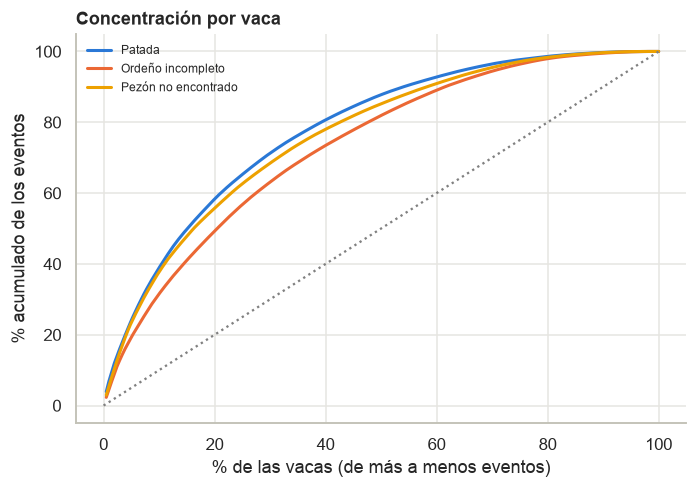

% de los eventos que ocurren en el 10 % de las vacas con más eventos: {'Patada': 38.0, 'Ordeño incompleto': 30.8, 'Pezón no encontrado': 36.9}


In [44]:
def proporcion_ic(positivos, total):
    """
        Calcula una proporcion en porcentaje con su intervalo de confianza del 95 %: p ± 1.96 · EE,
        con EE = raiz(p (1 - p) / n). Supone sesiones independientes, por lo que es optimista
        cuando las sesiones de una misma vaca se parecen entre si.

        Args:
            positivos (float): Cantidad de casos con el evento.
            total (float): Cantidad de casos observados.

        Returns:
            tuple: Porcentaje y semiancho del intervalo, ambos en puntos porcentuales.
    """
    p = positivos / total
    return float(p * 100), float(Z95 * np.sqrt(p * (1 - p) / total) * 100)


# Concentracion de cada evento en pocas vacas (parte del grafico de eventos de exploracion_datos.py)
fig, eje = plt.subplots(figsize=(6.5, 4.6))
concentracion = {}
for evento, color in zip(EVENTOS, [COLOR_BASE, COLOR_ALERTA, COLOR_AUXILIAR]):
    por_vaca = leche.groupby("animal_id")[evento].sum().sort_values(ascending=False)
    acumulado = por_vaca.cumsum() / por_vaca.sum() * 100
    x = np.arange(1, len(acumulado) + 1) / len(acumulado) * 100
    eje.plot(x, acumulado.values, color=color, linewidth=2, label=ETIQUETAS_EVENTO[evento])
    concentracion[ETIQUETAS_EVENTO[evento]] = round(float(acumulado.iloc[int(len(acumulado) * 0.1) - 1]), 1)
eje.plot([0, 100], [0, 100], color="gray", linestyle=":")
eje.set_xlabel("% de las vacas (de más a menos eventos)")
eje.set_ylabel("% acumulado de los eventos")
eje.set_title("Concentración por vaca")
eje.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print("% de los eventos que ocurren en el 10 % de las vacas con más eventos:", concentracion)

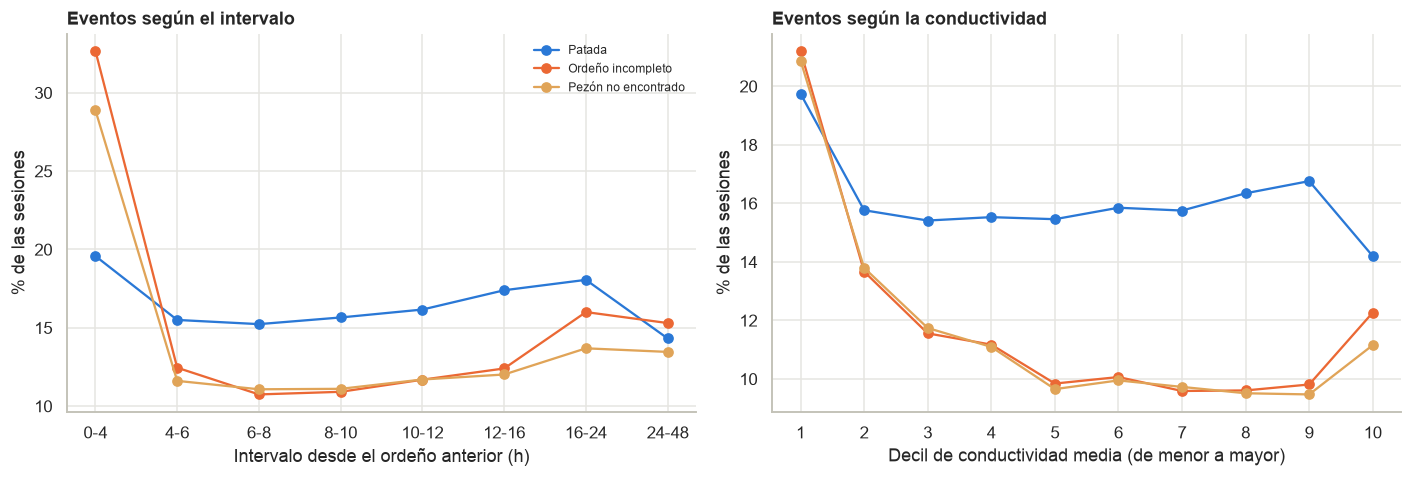

,valor
"incompleto_por_intervalo_pct · [0.0, 4.0)",32.7
"incompleto_por_intervalo_pct · [4.0, 6.0)",12.5
"incompleto_por_intervalo_pct · [6.0, 8.0)",10.7
"incompleto_por_intervalo_pct · [8.0, 10.0)",10.9
"incompleto_por_intervalo_pct · [10.0, 12.0)",11.7
"incompleto_por_intervalo_pct · [12.0, 16.0)",12.4
"incompleto_por_intervalo_pct · [16.0, 24.0)",16.0
"incompleto_por_intervalo_pct · [24.0, 48.01)",15.3
incompleto_por_decil_conductividad_pct · 1,21.2
incompleto_por_decil_conductividad_pct · 2,13.7


In [45]:
def graficar_intervalo_conductividad(leche, destino=None):
    """
        Grafica la tasa de eventos segun el intervalo desde el ordeño anterior y segun la conductividad
        media (hipotesis H5 y H6).

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.
            destino (Path): Carpeta donde se guarda la imagen.

        Returns:
            dict: Tasas de eventos por rango.
    """
    cortes_intervalo = [0, 4, 6, 8, 10, 12, 16, 24, UMBRAL_INTERVALO_H + 0.01]
    intervalo = pd.cut(leche["interval_h"], cortes_intervalo, right=False)
    cuantiles = pd.qcut(leche["cond_media"], 10, duplicates="drop")
    por_intervalo = leche.groupby(intervalo, observed=True)[EVENTOS].mean().mul(100)
    por_cond = leche.groupby(cuantiles, observed=True)[EVENTOS].mean().mul(100)

    fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
    for eje, tabla, etiqueta, titulo in [
        (ejes[0], por_intervalo, "Intervalo desde el ordeño anterior (h)", "Eventos según el intervalo"),
        (ejes[1], por_cond, "Decil de conductividad media (de menor a mayor)", "Eventos según la conductividad")]:
        for evento, color in zip(EVENTOS, [COLOR_BASE, COLOR_ALERTA, "#e0a458"]):
            eje.plot(range(len(tabla)), tabla[evento].values, marker="o", color=color, label=ETIQUETAS_EVENTO[evento])
        eje.set_xticks(range(len(tabla)))
        eje.set_ylabel("% de las sesiones")
        eje.set_xlabel(etiqueta)
        eje.set_title(titulo)
    ejes[0].set_xticklabels([f"{int(i.left)}-{int(i.right)}" for i in por_intervalo.index], rotation=0)
    ejes[1].set_xticklabels(range(1, len(por_cond) + 1))
    ejes[0].legend(frameon=False, fontsize=8)
    guardar(fig, destino, "eda_intervalo_conductividad")

    return {"incompleto_por_intervalo_pct": {str(k): round(float(v), 1) for k, v in por_intervalo["incomplete"].items()},
            "incompleto_por_decil_conductividad_pct": {str(i + 1): round(float(v), 1)
                                                       for i, v in enumerate(por_cond["incomplete"].values)}}


ver(graficar_intervalo_conductividad(leche))

### 15.2 Eventos en el tiempo, persistencia y adaptación

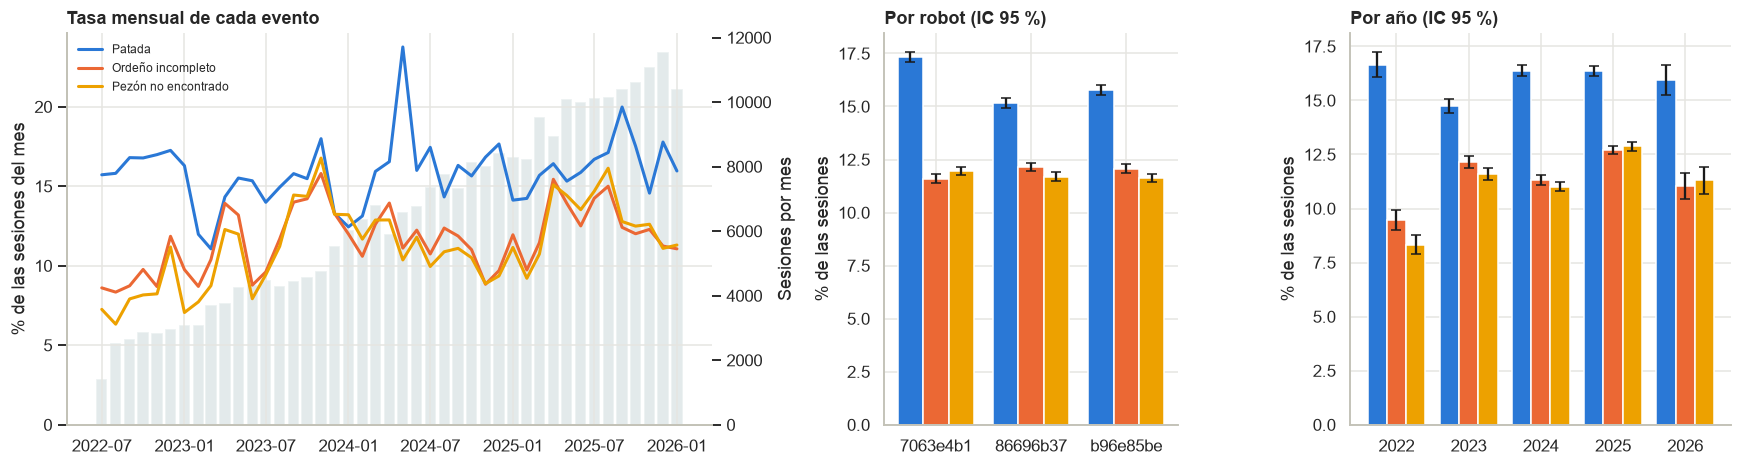

,valor
por_robot · 7063e4b1 · sesiones,91405
por_robot · 7063e4b1 · kick · pct,17.33
por_robot · 7063e4b1 · kick · ic95_mas_menos,0.25
por_robot · 7063e4b1 · incomplete · pct,11.59
por_robot · 7063e4b1 · incomplete · ic95_mas_menos,0.21
por_robot · 7063e4b1 · teat_missing · pct,11.96
por_robot · 7063e4b1 · teat_missing · ic95_mas_menos,0.21
por_robot · 86696b37 · sesiones,91649
por_robot · 86696b37 · kick · pct,15.15
por_robot · 86696b37 · kick · ic95_mas_menos,0.23


In [46]:
def analizar_eventos_en_el_tiempo(leche, destino=None):
    """
        Grafica la tasa mensual de cada evento y las tasas por robot y por ano con su intervalo de confianza del 95 %.

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.
            destino (Path): Carpeta donde se guarda la imagen.

        Returns:
            dict: Tasas con IC por robot, por ano y por mes (resumen).
    """
    mensual = leche.groupby("mes")[EVENTOS].mean().mul(100)
    sesiones_mes = leche.groupby("mes").size()
    resultado = {"por_robot": {}, "por_anio": {}}
    for clave, agrupador in [("por_robot", leche["machine"]), ("por_anio", leche["timestamp"].dt.year)]:
        for grupo, bloque in leche.groupby(agrupador):
            resultado[clave][str(grupo)] = {"sesiones": int(len(bloque))}
            for evento in EVENTOS:
                tasa, ic = proporcion_ic(bloque[evento].sum(), len(bloque))
                resultado[clave][str(grupo)][evento] = {"pct": round(tasa, 2), "ic95_mas_menos": round(ic, 2)}

    fig, ejes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [2.2, 1, 1.3]})
    for evento in EVENTOS:
        ejes[0].plot(mensual.index, mensual[evento], color=COLORES_EVENTO[evento], linewidth=2, label=ETIQUETAS_EVENTO[evento])
    ejes[0].set_ylabel("% de las sesiones del mes")
    ejes[0].set_title("Tasa mensual de cada evento")
    ejes[0].legend(frameon=False, fontsize=8, loc="upper left")
    ejes[0].set_ylim(0, None)
    reserva = ejes[0].twinx()
    reserva.bar(sesiones_mes.index, sesiones_mes.values, width=25, color=COLOR_GRIS, alpha=0.5, zorder=0)
    reserva.set_ylabel("Sesiones por mes")
    reserva.spines["top"].set_visible(False)
    reserva.grid(False)
    ejes[0].set_zorder(reserva.get_zorder() + 1)
    ejes[0].patch.set_visible(False)

    for eje, clave, titulo in [(ejes[1], "por_robot", "Por robot"), (ejes[2], "por_anio", "Por año")]:
        grupos = list(resultado[clave])
        ancho = 0.8 / len(EVENTOS)
        for i, evento in enumerate(EVENTOS):
            valores = [resultado[clave][g][evento]["pct"] for g in grupos]
            errores = [resultado[clave][g][evento]["ic95_mas_menos"] for g in grupos]
            eje.bar(np.arange(len(grupos)) + i * ancho, valores, ancho, yerr=errores, capsize=3,
                    color=COLORES_EVENTO[evento], label=ETIQUETAS_EVENTO[evento])
        eje.set_xticks(np.arange(len(grupos)) + ancho)
        eje.set_xticklabels(grupos)
        eje.set_title(f"{titulo} (IC 95 %)")
        eje.set_ylabel("% de las sesiones")
    guardar(fig, destino, "eda_eventos_en_el_tiempo")

    resultado["mensual_min_max"] = {e: [round(float(mensual[e].min()), 1), round(float(mensual[e].max()), 1)] for e in EVENTOS}
    return resultado


ver(analizar_eventos_en_el_tiempo(leche))

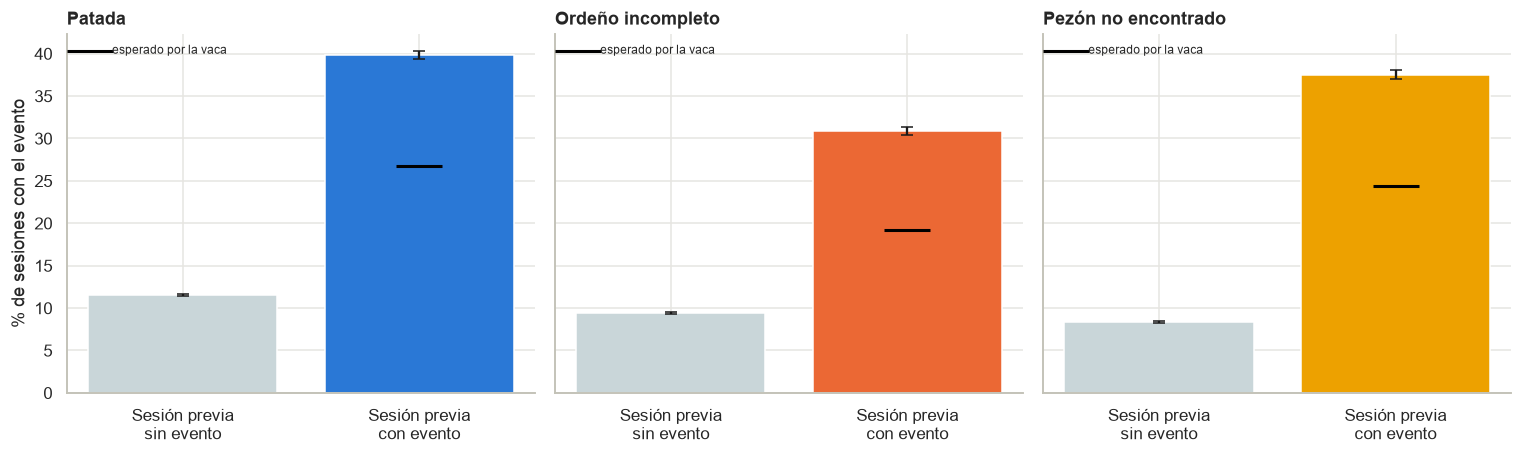

,valor
kick · sesiones_con_previo_valido,277627.00
kick · p_evento_si_previo_con_evento_pct,39.87
kick · ic95_con,0.45
kick · p_evento_si_previo_sin_evento_pct,11.54
kick · ic95_sin,0.13
kick · esperado_si_solo_importara_la_vaca_pct,26.71
kick · razon_observada_sobre_sin_previo,3.45
kick · razon_observada_sobre_esperado,1.49
incomplete · sesiones_con_previo_valido,277627.00
incomplete · p_evento_si_previo_con_evento_pct,30.90


In [47]:
def analizar_persistencia(leche, destino=None):
    """
        Mide si un evento en la sesion anterior de la misma vaca (a menos de 24 h) eleva la probabilidad
        de evento en la sesion actual. Compara con la tasa esperada si solo importara la vaca: el promedio
        de la tasa propia de cada vaca ponderado por las sesiones que siguen a un evento.

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.
            destino (Path): Carpeta donde se guarda la imagen.

        Returns:
            dict: Probabilidad condicional observada y esperada por evento.
    """
    ordenado = leche.sort_values(["animal_id", "timestamp"]).copy()
    horas = ordenado.groupby("animal_id")["timestamp"].diff().dt.total_seconds() / 3600
    tasa_vaca = ordenado.groupby("animal_id")[EVENTOS].transform("mean")
    resultado = {}
    fig, ejes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
    for eje, evento in zip(ejes, EVENTOS):
        previo = ordenado.groupby("animal_id")[evento].shift(1)
        valido = (horas <= 24) & previo.notna()
        actual = ordenado.loc[valido, evento]
        previo = previo[valido]
        esperado = tasa_vaca.loc[valido, evento][previo == 1].mean() * 100
        con_previo, ic_con = proporcion_ic(actual[previo == 1].sum(), (previo == 1).sum())
        sin_previo, ic_sin = proporcion_ic(actual[previo == 0].sum(), (previo == 0).sum())
        resultado[evento] = {
            "sesiones_con_previo_valido": int(valido.sum()),
            "p_evento_si_previo_con_evento_pct": round(con_previo, 2), "ic95_con": round(ic_con, 2),
            "p_evento_si_previo_sin_evento_pct": round(sin_previo, 2), "ic95_sin": round(ic_sin, 2),
            "esperado_si_solo_importara_la_vaca_pct": round(float(esperado), 2),
            "razon_observada_sobre_sin_previo": round(con_previo / sin_previo, 2),
            "razon_observada_sobre_esperado": round(con_previo / esperado, 2),
        }
        eje.bar([0, 1], [sin_previo, con_previo], yerr=[ic_sin, ic_con], capsize=4, color=[COLOR_GRIS, COLORES_EVENTO[evento]])
        eje.scatter([1], [esperado], marker="_", s=900, color="black", linewidth=2, zorder=3, label="esperado por la vaca")
        eje.set_xticks([0, 1])
        eje.set_xticklabels(["Sesión previa\nsin evento", "Sesión previa\ncon evento"])
        eje.set_title(ETIQUETAS_EVENTO[evento])
        eje.legend(frameon=False, fontsize=8, loc="upper left")
    ejes[0].set_ylabel("% de sesiones con el evento")
    guardar(fig, destino, "eda_persistencia")
    return resultado


ver(analizar_persistencia(leche))

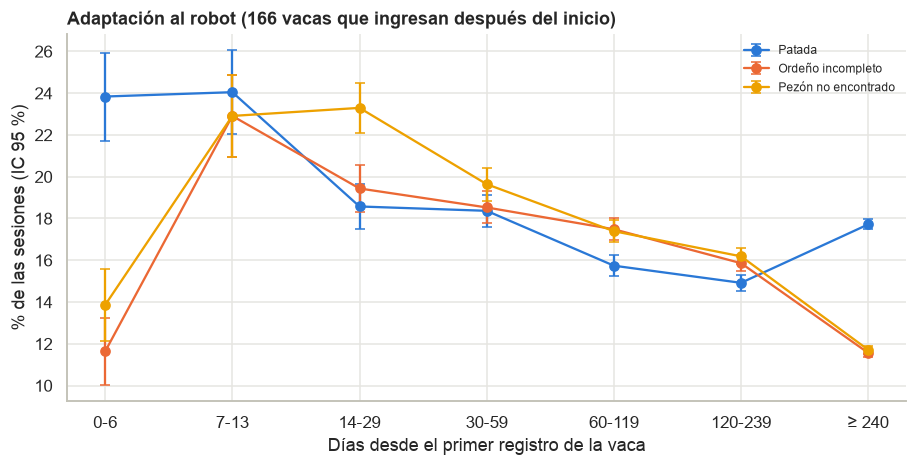

,valor
vacas_nuevas,166.00
sesiones,174309.00
intervalos · 0-6 · sesiones,1573.00
intervalos · 0-6 · kick · pct,23.84
intervalos · 0-6 · kick · ic95_mas_menos,2.11
intervalos · 0-6 · incomplete · pct,11.63
intervalos · 0-6 · incomplete · ic95_mas_menos,1.58
intervalos · 0-6 · teat_missing · pct,13.86
intervalos · 0-6 · teat_missing · ic95_mas_menos,1.71
intervalos · 7-13 · sesiones,1759.00


In [48]:
def analizar_adaptacion(leche, destino=None):
    """
        Mide la tasa de eventos segun los dias desde el primer registro de cada vaca, solo para vacas
        cuyo primer registro es 60 dias o mas posterior al inicio de los datos (las demas ya estaban en el hato).

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.
            destino (Path): Carpeta donde se guarda la imagen.

        Returns:
            dict: Tasa de cada evento con IC por intervalo de dias desde el primer registro.
    """
    primera = leche.groupby("animal_id")["timestamp"].transform("min")
    nuevas = primera > leche["timestamp"].min() + pd.Timedelta(days=60)
    datos = leche[nuevas].assign(dias=(leche["timestamp"] - primera).dt.days)
    cortes = [0, 7, 14, 30, 60, 120, 240, 100000]
    etiquetas = ["0-6", "7-13", "14-29", "30-59", "60-119", "120-239", "≥ 240"]
    datos["intervalo"] = pd.cut(datos["dias"], cortes, labels=etiquetas, right=False)

    resultado = {"vacas_nuevas": int(datos["animal_id"].nunique()), "sesiones": int(len(datos)), "intervalos": {}}
    fig, eje = plt.subplots(figsize=(8.5, 4.4))
    for evento in EVENTOS:
        tasas, errores = [], []
        for etiqueta in etiquetas:
            bloque = datos[datos["intervalo"] == etiqueta]
            tasa, ic = proporcion_ic(bloque[evento].sum(), len(bloque))
            tasas.append(tasa)
            errores.append(ic)
            resultado["intervalos"].setdefault(etiqueta, {"sesiones": int(len(bloque))})[evento] = {
                "pct": round(tasa, 2), "ic95_mas_menos": round(ic, 2)}
        eje.errorbar(range(len(etiquetas)), tasas, yerr=errores, marker="o", capsize=3, color=COLORES_EVENTO[evento],
                     label=ETIQUETAS_EVENTO[evento])
    eje.set_xticks(range(len(etiquetas)))
    eje.set_xticklabels(etiquetas)
    eje.set_xlabel("Días desde el primer registro de la vaca")
    eje.set_ylabel("% de las sesiones (IC 95 %)")
    eje.set_title(f"Adaptación al robot ({resultado['vacas_nuevas']} vacas que ingresan después del inicio)")
    eje.legend(frameon=False, fontsize=8)
    guardar(fig, destino, "eda_adaptacion")
    return resultado


ver(analizar_adaptacion(leche))

**Observaciones:** Los eventos se concentran en pocas vacas: el 10 % de las vacas con más eventos acumula 38.0 % de las patadas, 36.9 % de los pezones no encontrados y 30.8 % de los incompletos, así que el comportamiento individual de la vaca es una variable relevante. El incompleto se dispara cuando la vaca regresa antes de 4 h (32.7 % contra 10.7 a 12.5 % entre 4 y 12 h) y también en el decil más bajo de conductividad (21.2 %), lo que coincide con cuartos que casi no tienen leche. Los eventos son persistentes: tras un evento en la sesión anterior (menos de 24 h) la probabilidad de volver a tenerlo es 39.9 % (patada), 30.9 % (incompleto) y 37.5 % (pezón), contra 11.5, 9.4 y 8.3 % sin evento previo, y entre 1.5 y 1.6 veces lo que se esperaría solo por la tasa propia de la vaca. Las tasas por robot son estables entre sí y por año (patada de 14.7 a 16.7 %, incompleto de 9.5 a 12.7 %), y las 166 vacas que ingresan después del inicio tienen más eventos en sus primeras semanas (por ejemplo, incompleto de 19 a 23 % entre los días 7 y 29 contra 11.6 % después de 240 días), lo que sugiere una etapa de adaptación al robot.

## 16. Correlaciones con significancia, multicolinealidad y PCA

La matriz de Spearman de la sección 7 muestra qué variables se mueven juntas. Aquí se agrega la significancia estadística de cada par (covarianza, Pearson, R² y prueba t), el factor de inflación de la varianza (VIF) para decidir qué variables son redundantes y un análisis de componentes principales (PCA) de las variables del ordeño.

### 16.1 Correlación de Pearson con prueba t

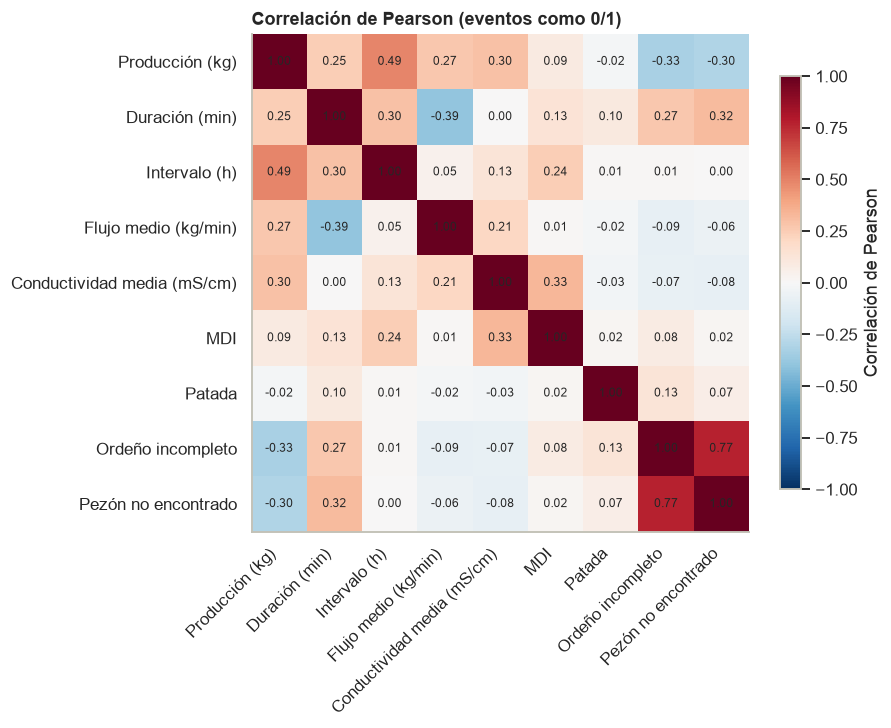

,x,y,n,covarianza,r,r2,spearman,t,p
1,milk_kg,interval_h,280071,10.1169,0.4921,0.2421,0.5447,299.1230,0.0
9,duration_min,flow_media,280533,-0.3284,-0.3939,0.1551,-0.4153,-226.9564,0.0
26,cond_media,mdi,257192,0.0644,0.3288,0.1081,0.3980,176.5547,0.0
6,milk_kg,incomplete,280697,-0.5658,-0.3270,0.1069,-0.3231,-183.3081,0.0
14,duration_min,teat_missing,280697,0.2658,0.3201,0.1025,0.2900,179.0241,0.0
7,milk_kg,teat_missing,280697,-0.5191,-0.3019,0.0912,-0.2990,-167.7942,0.0


,valor
pares_numericos_con_p_menor_0_001,31.0000
pares_numericos_total,33.0000
con_eventos · kick · r · milk_kg,-0.0190
con_eventos · kick · r · duration_min,0.1010
con_eventos · kick · r · interval_h,0.0140
con_eventos · kick · r · flow_media,-0.0170
con_eventos · kick · r · cond_media,-0.0290
con_eventos · kick · r · mdi,0.0180
con_eventos · kick · r2_maximo,0.0102
con_eventos · incomplete · r · milk_kg,-0.3270


In [49]:
def correlaciones_con_significancia(leche, destino=None):
    """
        Calcula covarianza, correlacion de Pearson, R2 y su prueba t bilateral (t = r raiz(n-2) / raiz(1-r2))
        para cada par de variables numericas y para cada variable contra los tres eventos (correlacion
        punto-biserial). Grafica la matriz de correlacion.

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.
            destino (Path): Carpeta donde se guarda la imagen.

        Returns:
            tuple: Resumen (dict) y tabla completa de pares (DataFrame).
    """
    columnas = VARIABLES_AGREGADAS + EVENTOS
    filas = []
    for i, a in enumerate(columnas):
        for b in columnas[i + 1:]:
            if a in EVENTOS:
                continue
            par = leche[[a, b]].dropna()
            n = len(par)
            r = par[a].corr(par[b])
            t = r * np.sqrt((n - 2) / (1 - r ** 2))
            filas.append({"x": a, "y": b, "n": n, "covarianza": par[a].cov(par[b]), "r": r, "r2": r ** 2,
                          "spearman": par[a].corr(par[b], method="spearman"), "t": t,
                          "p": float(2 * stats.t.sf(abs(t), n - 2))})
    tabla = pd.DataFrame(filas)

    matriz = leche[columnas].corr().rename(index=ETIQUETAS_VARIABLE | ETIQUETAS_EVENTO,
                                           columns=ETIQUETAS_VARIABLE | ETIQUETAS_EVENTO)
    fig, eje = plt.subplots(figsize=(8.2, 6.8))
    imagen = eje.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
    eje.set_xticks(range(len(matriz)))
    eje.set_xticklabels(matriz.columns, rotation=45, ha="right")
    eje.set_yticks(range(len(matriz)))
    eje.set_yticklabels(matriz.index)
    for i in range(len(matriz)):
        for j in range(len(matriz)):
            eje.text(j, i, f"{matriz.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(imagen, ax=eje, shrink=0.8, label="Correlación de Pearson")
    eje.set_title("Correlación de Pearson (eventos como 0/1)")
    eje.grid(False)
    guardar(fig, destino, "eda_correlacion_pearson")

    por_evento = {}
    for evento in EVENTOS:
        r = pd.Series({v: leche[v].corr(leche[evento]) for v in VARIABLES_AGREGADAS})
        por_evento[evento] = {"r": r.round(3).to_dict(), "r2_maximo": round(float((r ** 2).max()), 4)}
    principales = tabla.reindex(tabla["r"].abs().sort_values(ascending=False).index).head(6)
    resumen = {"pares_numericos_con_p_menor_0_001": int((tabla["p"] < 0.001).sum()), "pares_numericos_total": int(len(tabla)),
               "con_eventos": por_evento}
    return resumen, principales


resumen_corr, principales_corr = correlaciones_con_significancia(leche)
display(principales_corr.round(4))
ver(resumen_corr)

### 16.2 Multicolinealidad (VIF)

Un VIF mayor a 5 indica que la variable se explica bien con las demás y aporta poca información nueva a un modelo.

In [50]:
def calcular_vif(leche):
    """
        Calcula el factor de inflacion de la varianza (VIF) de dos conjuntos de variables. Un VIF mayor a 5
        indica que la variable se explica bien con las demas. Los ceros de flujo y conductividad son faltantes.

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.

        Returns:
            dict: VIF de las variables agregadas y de las variables por cuarto, con el numero de filas usadas.
    """
    conjuntos = {"agregadas": VARIABLES_AGREGADAS,
                 "por_cuarto": ["milk_kg", "duration_min", "interval_h", "mdi"] + [f"flow_{c}" for c in CUARTOS]
                               + [f"cond_{c}" for c in CUARTOS]}
    resultado = {}
    for nombre, columnas in conjuntos.items():
        datos = leche[columnas].astype(float).copy()
        for columna in columnas:
            if columna.startswith(("flow_", "cond_")) and columna not in ("flow_media", "cond_media"):
                datos[columna] = datos[columna].where(datos[columna] > 0)
        datos = datos.dropna()
        usadas = len(datos)
        datos = datos.sample(min(60000, usadas), random_state=SEMILLA)
        exog = sm.add_constant(datos)
        vif = {c: round(float(variance_inflation_factor(exog.to_numpy(), i)), 2)
               for i, c in enumerate(exog.columns) if c != "const"}
        resultado[nombre] = {"filas_completas": int(usadas), "pct_filas_completas": round(usadas / len(leche) * 100, 1),
                             "vif": vif}
    return resultado


ver(calcular_vif(leche))

,valor
agregadas · filas_completas,256657.00
agregadas · pct_filas_completas,91.40
agregadas · vif · milk_kg,1.90
agregadas · vif · duration_min,1.70
agregadas · vif · interval_h,1.48
agregadas · vif · flow_media,1.57
agregadas · vif · cond_media,1.24
agregadas · vif · mdi,1.20
por_cuarto · filas_completas,155353.00
por_cuarto · pct_filas_completas,55.30


### 16.3 Componentes principales del ordeño

Se ajustan dos PCA con las variables estandarizadas: uno con seis variables agregadas por ordeño (conserva casi todas las filas) y otro con las variables por cuarto (solo ordeños con los cuatro cuartos con flujo y conductividad válidos). Se revisa cuántos componentes hacen falta para explicar el 80 % de la varianza y si los primeros componentes separan los ordeños con evento.

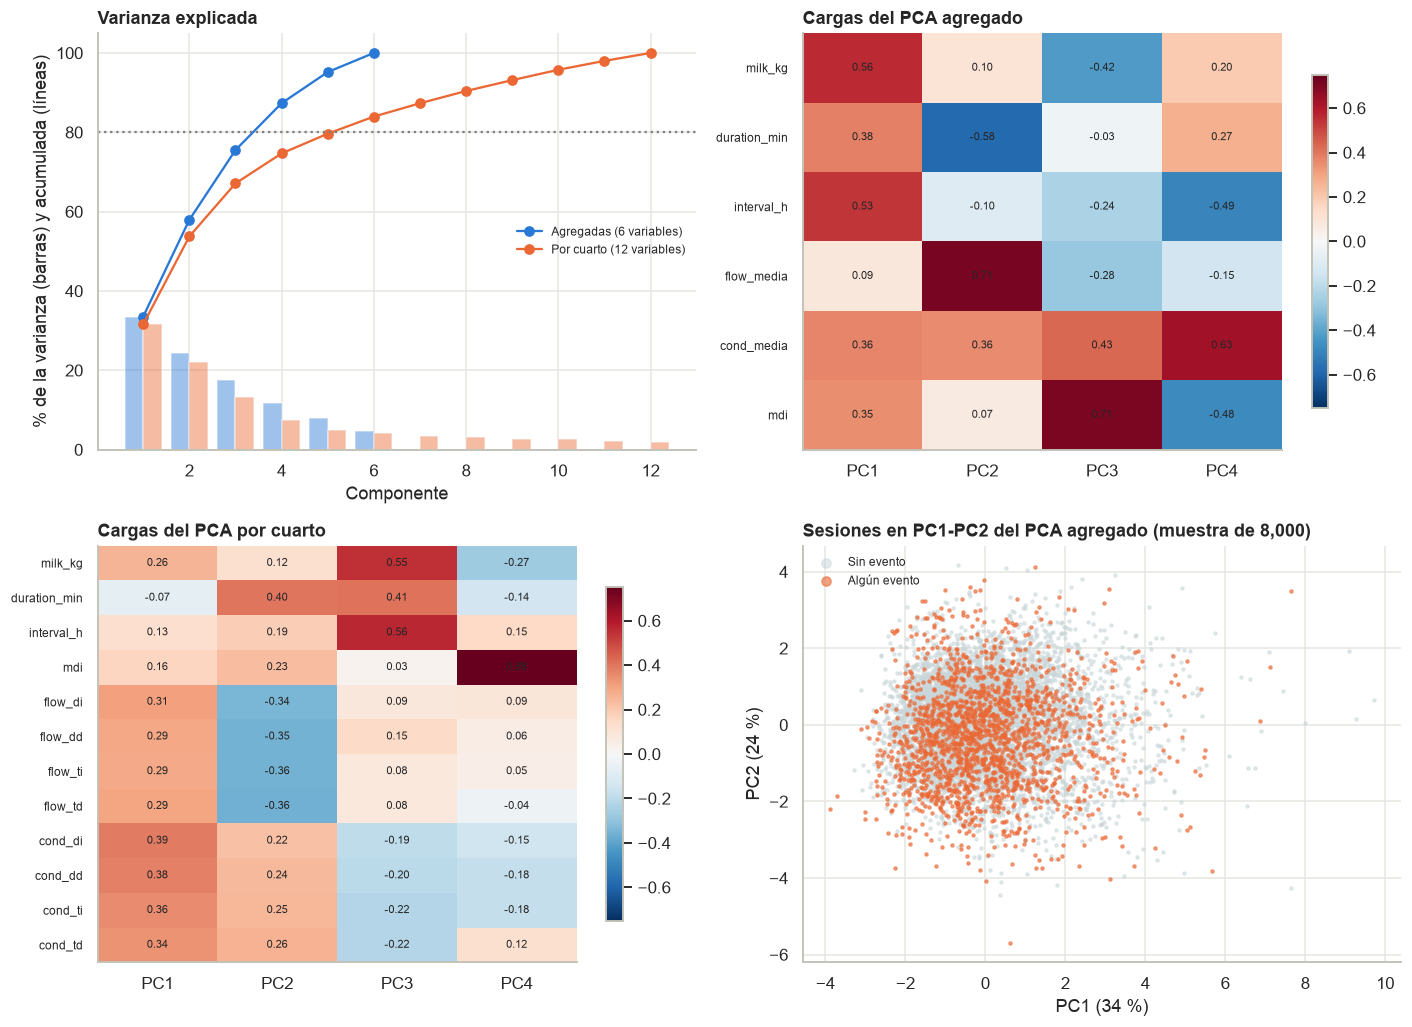

,valor
agregadas · filas,256657
agregadas · pct_filas,91.4
agregadas · varianza_explicada_pct,"[33.5, 24.4, 17.6, 11.8]"
agregadas · varianza_acumulada_pct,"[33.5, 57.9, 75.5, 87.3, 95.2, 100.0]"
agregadas · componentes_para_80pct,4
...,...
por_cuarto · separacion_por_evento · teat_missing · PC2 · ic95,"[0.173, 0.306]"
por_cuarto · separacion_por_evento · teat_missing · PC2 · d_cohen,0.147
por_cuarto · separacion_por_evento · teat_missing · PC3 · diferencia_medias,0.215
por_cuarto · separacion_por_evento · teat_missing · PC3 · ic95,"[0.166, 0.264]"


In [51]:
def ajustar_pca(datos, nombre_variables):
    """
        Estandariza las variables (z-score) y ajusta un PCA con todos los componentes.

        Args:
            datos (DataFrame): Filas completas, una columna por variable.
            nombre_variables (list): Columnas a usar.

        Returns:
            tuple: PCA ajustado, puntajes (ndarray) y cargas (DataFrame variable x componente).
    """
    estandarizado = StandardScaler().fit_transform(datos[nombre_variables])
    pca = PCA().fit(estandarizado)
    cargas = pd.DataFrame(pca.components_.T, index=nombre_variables,
                          columns=[f"PC{i + 1}" for i in range(len(nombre_variables))])
    return pca, pca.transform(estandarizado), cargas


def resumir_pca(pca, cargas, componentes=4):
    """
        Resume un PCA: varianza explicada, componentes para el 80 % y variables con mayor carga.

        Args:
            pca (PCA): PCA ajustado.
            cargas (DataFrame): Cargas por variable y componente.
            componentes (int): Cuantos componentes detallar.

        Returns:
            dict: Varianza explicada, acumulada, componentes para 80 % y 90 %, y cargas principales.
    """
    explicada = pca.explained_variance_ratio_
    acumulada = np.cumsum(explicada)
    return {
        "varianza_explicada_pct": (explicada[:componentes] * 100).round(1).tolist(),
        "varianza_acumulada_pct": (acumulada[:componentes + 2] * 100).round(1).tolist(),
        "componentes_para_80pct": int(np.searchsorted(acumulada, 0.80) + 1),
        "componentes_para_90pct": int(np.searchsorted(acumulada, 0.90) + 1),
        "componentes_con_valor_propio_mayor_a_1": int((pca.explained_variance_ > 1).sum()),
        "cargas_principales": {c: cargas[c].round(2).reindex(cargas[c].abs().sort_values(ascending=False).index).head(4).to_dict()
                               for c in cargas.columns[:componentes]},
    }


def separacion_por_evento(datos, puntajes):
    """
        Mide si los primeros tres componentes separan las sesiones con y sin cada evento: diferencia de medias,
        su IC 95 % (t de Welch) y la d de Cohen (diferencia entre la desviacion estandar combinada).

        Args:
            datos (DataFrame): Filas usadas en el PCA, con las columnas de eventos.
            puntajes (ndarray): Puntajes de cada fila en los componentes.

        Returns:
            dict: Por evento y componente, diferencia, IC 95 % y d de Cohen.
    """
    resultado = {}
    for evento in EVENTOS:
        con = datos[evento].to_numpy() == 1
        resultado[evento] = {"sesiones_con_evento": int(con.sum()), "prevalencia_pct": round(float(con.mean() * 100), 1)}
        for k in range(3):
            a, b = puntajes[con, k], puntajes[~con, k]
            diferencia = a.mean() - b.mean()
            error = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
            desviacion_comun = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
            resultado[evento][f"PC{k + 1}"] = {
                "diferencia_medias": round(float(diferencia), 3),
                "ic95": [round(float(diferencia - Z95 * error), 3), round(float(diferencia + Z95 * error), 3)],
                "d_cohen": round(float(diferencia / desviacion_comun), 3)}
    return resultado


def analizar_pca_ordeno(leche, destino=None):
    """
        Ajusta dos PCA sobre las variables de la sesion de ordeño: uno con las variables agregadas (conserva casi
        todas las filas) y otro con las variables por cuarto (solo sesiones con los cuatro cuartos ordeñados).
        Grafica la varianza explicada, las cargas y la proyeccion en PC1-PC2 coloreada por evento.

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.
            destino (Path): Carpeta donde se guarda la imagen.

        Returns:
            dict: Resumen de ambos PCA y separacion de los eventos en PC1-PC3.
    """
    por_cuarto = ["milk_kg", "duration_min", "interval_h", "mdi"] + [f"flow_{c}" for c in CUARTOS] + [f"cond_{c}" for c in CUARTOS]
    datos_cuarto = leche[por_cuarto + EVENTOS].astype(float).copy()
    for columna in por_cuarto:
        if columna.startswith(("flow_", "cond_")):
            datos_cuarto[columna] = datos_cuarto[columna].where(datos_cuarto[columna] > 0)
    datos_cuarto = datos_cuarto.dropna()
    datos_agregados = leche[VARIABLES_AGREGADAS + EVENTOS].astype(float).dropna()

    pca_a, puntajes_a, cargas_a = ajustar_pca(datos_agregados, VARIABLES_AGREGADAS)
    pca_c, puntajes_c, cargas_c = ajustar_pca(datos_cuarto, por_cuarto)
    resultado = {
        "agregadas": {"filas": int(len(datos_agregados)), "pct_filas": round(len(datos_agregados) / len(leche) * 100, 1),
                      **resumir_pca(pca_a, cargas_a), "separacion_por_evento": separacion_por_evento(datos_agregados, puntajes_a)},
        "por_cuarto": {"filas": int(len(datos_cuarto)), "pct_filas": round(len(datos_cuarto) / len(leche) * 100, 1),
                       **resumir_pca(pca_c, cargas_c), "separacion_por_evento": separacion_por_evento(datos_cuarto, puntajes_c)},
    }

    fig, ejes = plt.subplots(2, 2, figsize=(13, 9.5))
    for pca, nombre, color in [(pca_a, "Agregadas (6 variables)", COLOR_BASE), (pca_c, "Por cuarto (12 variables)", COLOR_ALERTA)]:
        posicion = np.arange(1, len(pca.explained_variance_ratio_) + 1)
        ejes[0, 0].bar(posicion + (0.2 if color == COLOR_ALERTA else -0.2), pca.explained_variance_ratio_ * 100, 0.4,
                       color=color, alpha=0.45)
        ejes[0, 0].plot(posicion, np.cumsum(pca.explained_variance_ratio_) * 100, marker="o", color=color, label=nombre)
    ejes[0, 0].axhline(80, color="gray", linestyle=":")
    ejes[0, 0].set_xlabel("Componente")
    ejes[0, 0].set_ylabel("% de la varianza (barras) y acumulada (líneas)")
    ejes[0, 0].set_title("Varianza explicada")
    ejes[0, 0].legend(frameon=False, fontsize=8, loc="center right")

    for eje, cargas, titulo in [(ejes[0, 1], cargas_a, "Cargas del PCA agregado"), (ejes[1, 0], cargas_c, "Cargas del PCA por cuarto")]:
        imagen = eje.imshow(cargas.iloc[:, :4], cmap="RdBu_r", vmin=-0.75, vmax=0.75, aspect="auto")
        eje.set_xticks(range(4))
        eje.set_xticklabels(cargas.columns[:4])
        eje.set_yticks(range(len(cargas)))
        eje.set_yticklabels(cargas.index, fontsize=8)
        for i in range(len(cargas)):
            for j in range(4):
                eje.text(j, i, f"{cargas.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
        eje.set_title(titulo)
        eje.grid(False)
        fig.colorbar(imagen, ax=eje, shrink=0.8)

    muestra = np.random.default_rng(SEMILLA).choice(len(datos_agregados), 8000, replace=False)
    marcados = datos_agregados[EVENTOS].to_numpy()[muestra].max(axis=1) == 1
    ejes[1, 1].scatter(puntajes_a[muestra][~marcados, 0], puntajes_a[muestra][~marcados, 1], s=4, color=COLOR_GRIS, alpha=0.5,
                       label="Sin evento")
    ejes[1, 1].scatter(puntajes_a[muestra][marcados, 0], puntajes_a[muestra][marcados, 1], s=4, color=COLOR_ALERTA, alpha=0.6,
                       label="Algún evento")
    ejes[1, 1].set_xlabel(f"PC1 ({pca_a.explained_variance_ratio_[0] * 100:.0f} %)")
    ejes[1, 1].set_ylabel(f"PC2 ({pca_a.explained_variance_ratio_[1] * 100:.0f} %)")
    ejes[1, 1].set_title("Sesiones en PC1-PC2 del PCA agregado (muestra de 8,000)")
    ejes[1, 1].legend(frameon=False, fontsize=8, markerscale=3)
    guardar(fig, destino, "eda_pca_ordeno")
    return resultado


ver(analizar_pca_ordeno(leche))

**Observaciones:** Con 33 pares de variables, 31 resultan significativos (p < 0.001), pero con 280 mil ordeños la significancia es casi automática, así que importa el tamaño de la correlación. Las más fuertes son producción con intervalo (r = 0.49), duración con flujo medio (−0.39), conductividad con MDI (0.33) y producción con incompleto (−0.33); ninguna variable explica más del 25 % de la varianza de otra. La patada casi no se correlaciona con nada (R² máximo de 0.010), mientras que el incompleto y el pezón no encontrado se explican sobre todo por menor producción y mayor duración (R² máximo de 0.107 y 0.103). El VIF es bajo en todos los casos (máximo 1.90 en las variables agregadas y 2.84 por cuarto), así que no hay multicolinealidad grave y no hace falta eliminar variables por redundancia. En el PCA de las seis variables agregadas hacen falta 4 componentes para explicar el 80 % de la varianza (33.5, 24.4, 17.6 y 11.8 % los primeros cuatro): la información está repartida y no se reduce a un solo factor.

## 17. Clima en profundidad: estrés calórico (THI) y eventos

La sección 7 correlaciona el clima de la hora de inicio con las variables del ordeño. Aquí se usa el índice de temperatura-humedad (THI) y se mira por separado cada pregunta: (a) si la producción de cada vaca respecto a su propia referencia baja en los días de calor, (b) si cambia la hora en que visitan el robot, (c) si los eventos aumentan con el THI de la hora y (d) cuánta información distinta aporta cada variable climática.

NASA POWER etiqueta cada hora una hora antes del clima que describe (confirmado en el script contra una estación observada), así que `cargar_clima` corre el índice una hora. La sección 7 no aplica ese ajuste.

In [52]:
def cargar_clima(ruta):
    """
        Lee la serie horaria de NASA POWER (descargar_clima.py), que ya viene en hora local, corrige su
        desfase y le agrega el indice temperatura-humedad:
        THI = (1.8 T + 32) - (0.55 - 0.0055 HR) * (1.8 T - 26)

        La fila etiquetada t de POWER corresponde al clima de t + 1 h (confirmado contra una estacion
        observada), asi que se corre el indice una hora: una sesion a la hora T toma la fila T - 1 h.

        Args:
            ruta (Path): CSV generado por descargar_clima.py.

        Returns:
            DataFrame: Serie horaria local, ya alineada, con las variables de POWER y el THI.
    """
    clima = pd.read_csv(ruta, index_col="hora", parse_dates=True)
    clima.index = clima.index + pd.Timedelta(hours=DESFASE_POWER_H)
    clima["thi"] = (1.8 * clima["t2m"] + 32) - (0.55 - 0.0055 * clima["rh2m"]) * (1.8 * clima["t2m"] - 26)
    return clima


def produccion_relativa(leche):
    """
        Calcula la producción de cada vaca-dia dividida entre la mediana de sus 28 registros anteriores,
        para quitar las diferencias entre vacas y la etapa de lactancia. Solo se conservan los dias con
        un registro previo a 3 dias o menos y una referencia mayor a 5 kg.

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.

        Returns:
            DataFrame: Una fila por vaca-dia con leche_kg, referencia y relativa.
    """
    vaca_dia = leche.groupby(["animal_id", "fecha"]).agg(leche_kg=("milk_kg", "sum")).reset_index()
    vaca_dia = vaca_dia.sort_values(["animal_id", "fecha"])
    por_vaca = vaca_dia.groupby("animal_id")
    vaca_dia["referencia"] = por_vaca["leche_kg"].transform(lambda s: s.rolling(28, min_periods=14).median().shift(1))
    vaca_dia["dias_desde_previo"] = por_vaca["fecha"].diff().dt.days
    vaca_dia = vaca_dia[(vaca_dia["dias_desde_previo"] <= 3) & (vaca_dia["referencia"] > 5)]
    vaca_dia = vaca_dia[vaca_dia["fecha"] < leche["fecha"].max()]
    vaca_dia["relativa"] = vaca_dia["leche_kg"] / vaca_dia["referencia"]
    return vaca_dia


clima_a = cargar_clima(raiz / "Data" / "clima" / "clima_nasa_power_por_hora.csv")
print(f"Clima alineado: {len(clima_a):,} horas | THI medio {clima_a['thi'].mean():.1f} | horas con THI ≥ {UMBRAL_THI}: {(clima_a['thi'] >= UMBRAL_THI).mean():.1%}")

Clima alineado: 31,104 horas | THI medio 60.8 | horas con THI ≥ 68: 21.8%


### 17.1 Eventos y variables climáticas (correlación punto-biserial)

Para cada evento (0/1) y cada una de las 13 variables de NASA POWER se calcula la correlación punto-biserial. La escala del mapa se limita a ±0.10 porque ninguna correlación es mayor.

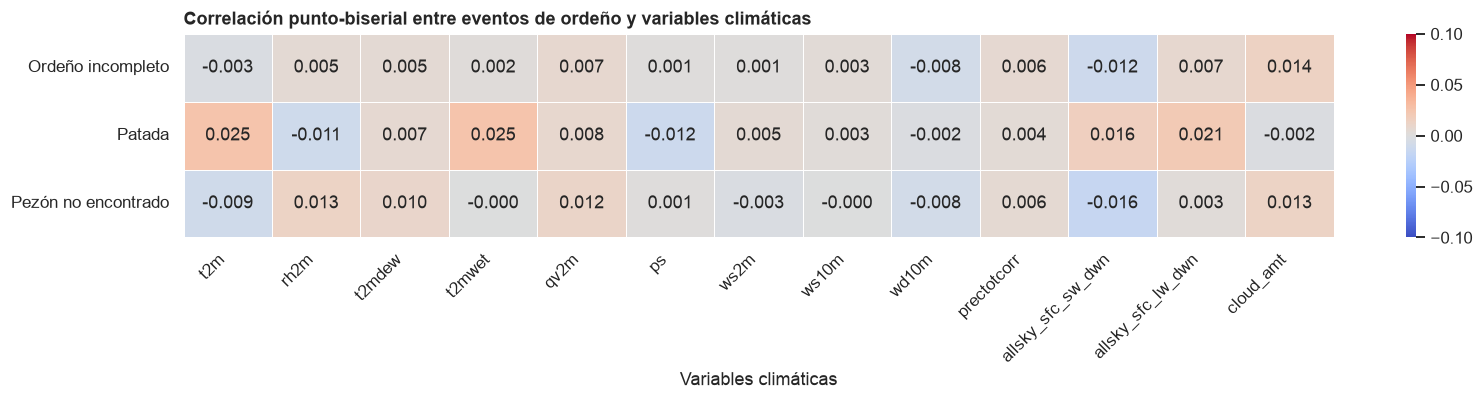

,evento,variable_climatica,correlacion,p_valor,observaciones
3,Patada,t2mwet,0.0255,0.0,280690
0,Patada,t2m,0.0252,0.0,280690
11,Patada,allsky_sfc_lw_dwn,0.0211,0.0,280690
36,Pezón no encontrado,allsky_sfc_sw_dwn,-0.0158,0.0,280690
10,Patada,allsky_sfc_sw_dwn,0.0157,0.0,280690
25,Ordeño incompleto,cloud_amt,0.0135,0.0,280690


In [53]:
clima_cols = ["t2m", "rh2m", "t2mdew", "t2mwet", "qv2m", "ps", "ws2m", "ws10m", "wd10m",
              "prectotcorr", "allsky_sfc_sw_dwn", "allsky_sfc_lw_dwn", "cloud_amt"]
con_clima_ev = leche.assign(hora_clave=leche["timestamp"].dt.floor("h")).merge(
    clima_a, left_on="hora_clave", right_index=True, how="left")

resultados = []
for evento in EVENTOS:
    for variable_clima in clima_cols:
        pares = con_clima_ev[[evento, variable_clima]].dropna()
        r, p = stats.pointbiserialr(pares[evento], pares[variable_clima])
        resultados.append({"evento": ETIQUETAS_EVENTO[evento], "variable_climatica": variable_clima,
                           "correlacion": r, "p_valor": p, "observaciones": len(pares)})
resultados_corr = pd.DataFrame(resultados)
matriz_corr = resultados_corr.pivot(index="evento", columns="variable_climatica", values="correlacion")[clima_cols]

plt.figure(figsize=(15, 3.8))
sns.heatmap(matriz_corr, annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-0.10, vmax=0.10, linewidths=0.5)
plt.title("Correlación punto-biserial entre eventos de ordeño y variables climáticas")
plt.xlabel("Variables climáticas"); plt.ylabel("")
plt.xticks(rotation=45, ha="right"); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()
resultados_corr.reindex(resultados_corr["correlacion"].abs().sort_values(ascending=False).index).head(6).round(4)

### 17.2 Producción relativa, hora de visita y eventos según el THI

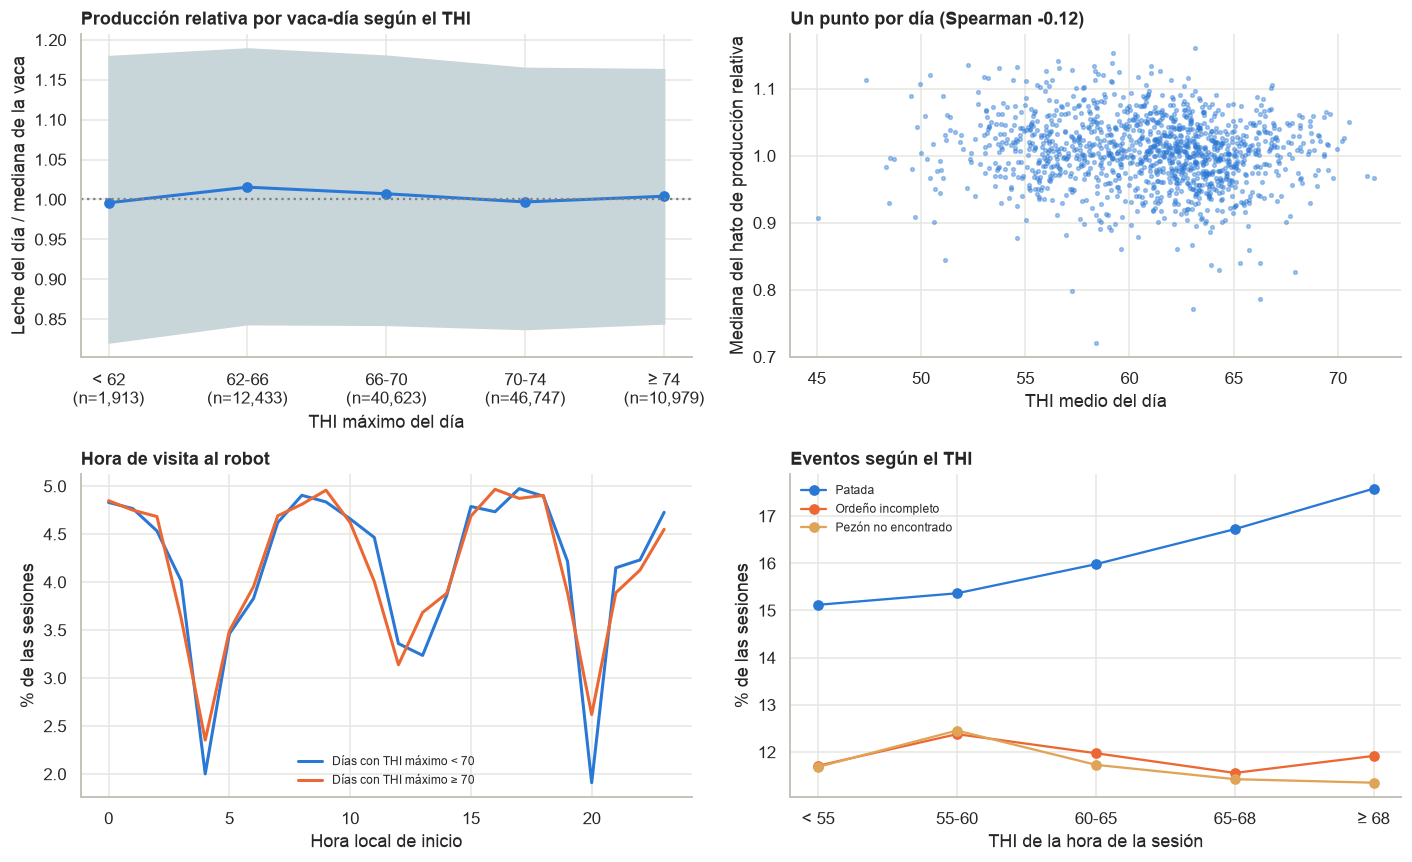

,valor
cobertura_clima_pct,1.000000e+02
dias_con_thi_max_70_o_mas,7.100000e+02
dias_totales,1.297000e+03
thi_hora_pct_sesiones_68_o_mas,2.120000e+01
mediana_relativa_por_thi_max · < 62,9.960000e-01
mediana_relativa_por_thi_max · 62-66,1.015000e+00
mediana_relativa_por_thi_max · 66-70,1.007000e+00
mediana_relativa_por_thi_max · 70-74,9.970000e-01
mediana_relativa_por_thi_max · ≥ 74,1.004000e+00
vaca_dias_por_grupo · < 62,1.913000e+03


In [54]:
def analizar_clima(leche, clima, destino=None):
    """
        Cruza las sesiones con el clima de la fuente elegida y grafica la relacion del THI con la producción
        relativa por vaca, la hora de visita y los eventos (hipotesis H1, H2 y parte de H7).
        La producción relativa compara cada vaca-dia con la mediana de sus 28 registros anteriores,
        para quitar las diferencias entre vacas y la etapa de lactancia.

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.
            clima (DataFrame): Serie horaria de clima con THI.
            destino (Path): Carpeta donde se guarda la imagen.

        Returns:
            dict: Resultados del cruce con el clima.
    """
    con_clima = leche.assign(hora_clave=leche["timestamp"].dt.floor("h")).merge(
        clima, left_on="hora_clave", right_index=True, how="left")
    cobertura = float(con_clima["thi"].notna().mean() * 100)

    diario = clima.groupby(clima.index.normalize()).agg(thi_medio=("thi", "mean"), thi_max=("thi", "max"),
                                                       temp_media=("t2m", "mean"))
    vaca_dia = produccion_relativa(leche).merge(diario, left_on="fecha", right_index=True, how="inner")

    cortes = [0, 62, 66, 70, 74, 100]
    etiquetas = ["< 62", "62-66", "66-70", "70-74", "≥ 74"]
    vaca_dia["grupo_thi"] = pd.cut(vaca_dia["thi_max"], cortes, labels=etiquetas, right=False)
    por_grupo = vaca_dia.groupby("grupo_thi", observed=True)["relativa"].agg(["median", "count"])
    cuartiles = vaca_dia.groupby("grupo_thi", observed=True)["relativa"].quantile([0.25, 0.75]).unstack()

    hato = vaca_dia.groupby("fecha").agg(relativa=("relativa", "median"), thi_medio=("thi_medio", "first"),
                                         thi_max=("thi_max", "first"))
    desfases = {}
    for dias in range(0, 6):
        desfasada = hato["thi_medio"].shift(dias)
        valido = desfasada.notna() & hato["relativa"].notna()
        rho, p = stats.spearmanr(desfasada[valido], hato.loc[valido, "relativa"])
        desfases[dias] = {"rho": round(float(rho), 3), "p": float(p)}

    # Hora de visita en dias calurosos y frescos
    dias_calor = set(diario.index[diario["thi_max"] >= 70])
    es_calor = con_clima["fecha"].isin(dias_calor)
    hora_calor = con_clima.loc[es_calor, "hora"].value_counts(normalize=True).sort_index() * 100
    hora_fresco = con_clima.loc[~es_calor, "hora"].value_counts(normalize=True).sort_index() * 100

    # Eventos segun el THI de la hora de la sesion
    con_clima["grupo_thi_hora"] = pd.cut(con_clima["thi"], [0, 55, 60, 65, 68, 100],
                                         labels=["< 55", "55-60", "60-65", "65-68", "≥ 68"], right=False)
    eventos_thi = con_clima.groupby("grupo_thi_hora", observed=True)[EVENTOS].mean().mul(100)

    fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
    x = range(len(por_grupo))
    ejes[0, 0].fill_between(x, cuartiles[0.25], cuartiles[0.75], color=COLOR_GRIS)
    ejes[0, 0].plot(x, por_grupo["median"], color=COLOR_BASE, marker="o", linewidth=2)
    ejes[0, 0].axhline(1, color="gray", linestyle=":")
    ejes[0, 0].set_xticks(list(x))
    ejes[0, 0].set_xticklabels([f"{g}\n(n={n:,})" for g, n in zip(por_grupo.index, por_grupo["count"])])
    ejes[0, 0].set_xlabel("THI máximo del día")
    ejes[0, 0].set_ylabel("Leche del día / mediana de la vaca")
    ejes[0, 0].set_title("Producción relativa por vaca-día según el THI")

    ejes[0, 1].scatter(hato["thi_medio"], hato["relativa"], s=6, alpha=0.4, color=COLOR_BASE)
    ejes[0, 1].set_xlabel("THI medio del día")
    ejes[0, 1].set_ylabel("Mediana del hato de producción relativa")
    ejes[0, 1].set_title(f"Un punto por día (Spearman {desfases[0]['rho']:.2f})")

    ejes[1, 0].plot(hora_fresco.index, hora_fresco.values, color=COLOR_BASE, linewidth=2, label="Días con THI máximo < 70")
    ejes[1, 0].plot(hora_calor.index, hora_calor.values, color=COLOR_ALERTA, linewidth=2, label="Días con THI máximo ≥ 70")
    ejes[1, 0].set_xlabel("Hora local de inicio")
    ejes[1, 0].set_ylabel("% de las sesiones")
    ejes[1, 0].set_title("Hora de visita al robot")
    ejes[1, 0].legend(frameon=False, fontsize=8)

    for evento, color in zip(EVENTOS, [COLOR_BASE, COLOR_ALERTA, "#e0a458"]):
        ejes[1, 1].plot(range(len(eventos_thi)), eventos_thi[evento].values, marker="o", color=color,
                        label=ETIQUETAS_EVENTO[evento])
    ejes[1, 1].set_xticks(range(len(eventos_thi)))
    ejes[1, 1].set_xticklabels(eventos_thi.index)
    ejes[1, 1].set_xlabel("THI de la hora de la sesión")
    ejes[1, 1].set_ylabel("% de las sesiones")
    ejes[1, 1].set_title("Eventos según el THI")
    ejes[1, 1].legend(frameon=False, fontsize=8)
    guardar(fig, destino, "eda_clima_thi")

    return {"cobertura_clima_pct": round(cobertura, 2),
            "dias_con_thi_max_70_o_mas": int((diario["thi_max"] >= 70).sum()), "dias_totales": int(len(diario)),
            "mediana_relativa_por_thi_max": por_grupo["median"].round(3).to_dict(),
            "vaca_dias_por_grupo": por_grupo["count"].to_dict(),
            "spearman_hato_vs_thi_medio_por_rezago_dias": desfases,
            "pct_sesiones_00_05h": {"fresco": round(float(hora_fresco.loc[0:5].sum()), 1),
                                    "calor": round(float(hora_calor.loc[0:5].sum()), 1)},
            "pct_sesiones_12_17h": {"fresco": round(float(hora_fresco.loc[12:17].sum()), 1),
                                    "calor": round(float(hora_calor.loc[12:17].sum()), 1)},
            "eventos_por_thi_hora_pct": eventos_thi.round(2).to_dict(orient="index"),
            "thi_hora_pct_sesiones_68_o_mas": round(float((con_clima["thi"] >= UMBRAL_THI).mean() * 100), 1)}


ver(analizar_clima(leche, clima_a))

### 17.3 Redundancia entre variables climáticas y sensibilidad del umbral de calor

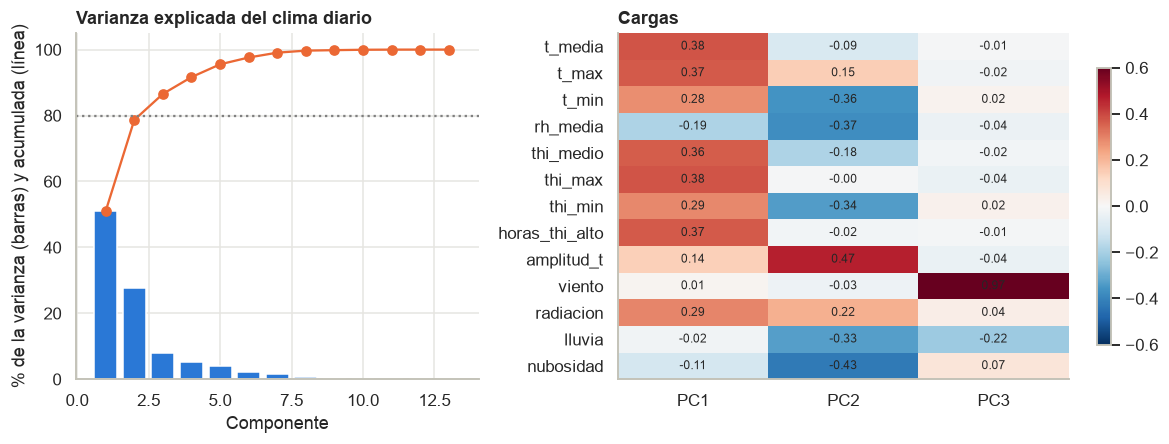

,valor
dias,1295
varianza_explicada_pct,"[51.0, 27.6, 7.9]"
varianza_acumulada_pct,"[51.0, 78.7, 86.6, 91.7, 95.5]"
componentes_para_80pct,3
componentes_para_90pct,4
componentes_con_valor_propio_mayor_a_1,3
cargas_principales · PC1 · t_media,0.38
cargas_principales · PC1 · thi_max,0.38
cargas_principales · PC1 · horas_thi_alto,0.37
cargas_principales · PC1 · t_max,0.37


,valor
68 · dias_calurosos,958
68 · dias_frescos,323
68 · produccion_relativa · diferencia,-0.0098
68 · produccion_relativa · ic95,"[-0.0162, -0.0033]"
68 · produccion_relativa · t,-2.95
68 · produccion_relativa · p,0.003334
68 · pct_visitas_00_05h · diferencia,-0.0789
68 · pct_visitas_00_05h · ic95,"[-0.4791, 0.3213]"
68 · pct_visitas_00_05h · t,-0.39
68 · pct_visitas_00_05h · p,0.699376


In [55]:
def analizar_pca_clima(clima, destino=None):
    """
        Ajusta un PCA a trece resumenes diarios del clima (los nueve de temperatura,
        humedad y THI, mas viento, radiacion, lluvia y nubosidad de NASA POWER) para ver cuanta informacion distinta aportan
        y si basta un solo indice (el THI) para describir el dia.

        Args:
            clima (DataFrame): Tabla horaria de clima.
            destino (Path): Carpeta donde se guarda la imagen.

        Returns:
            dict: Resumen del PCA del clima diario.
    """
    dias = clima.groupby(clima.index.normalize())
    diario = pd.DataFrame({
        "t_media": dias["t2m"].mean(), "t_max": dias["t2m"].max(), "t_min": dias["t2m"].min(),
        "rh_media": dias["rh2m"].mean(), "thi_medio": dias["thi"].mean(), "thi_max": dias["thi"].max(),
        "thi_min": dias["thi"].min(), "horas_thi_alto": dias["thi"].apply(lambda s: (s >= UMBRAL_THI).sum()),
        "amplitud_t": dias["t2m"].max() - dias["t2m"].min(), "viento": dias["ws2m"].mean(),
        "radiacion": dias["allsky_sfc_sw_dwn"].mean(), "lluvia": dias["prectotcorr"].sum(min_count=24),
        "nubosidad": dias["cloud_amt"].mean()})
    diario = diario[dias.size() == 24].dropna()
    pca, _, cargas = ajustar_pca(diario, list(diario.columns))
    resultado = {"dias": int(len(diario)), **resumir_pca(pca, cargas, componentes=3)}

    fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
    ejes[0].bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_ * 100, color=COLOR_BASE)
    ejes[0].plot(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_) * 100,
                 marker="o", color=COLOR_ALERTA)
    ejes[0].axhline(80, color="gray", linestyle=":")
    ejes[0].set_xlabel("Componente")
    ejes[0].set_ylabel("% de la varianza (barras) y acumulada (línea)")
    ejes[0].set_title("Varianza explicada del clima diario")
    imagen = ejes[1].imshow(cargas.iloc[:, :3], cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
    ejes[1].set_xticks(range(3))
    ejes[1].set_xticklabels(cargas.columns[:3])
    ejes[1].set_yticks(range(len(cargas)))
    ejes[1].set_yticklabels(cargas.index)
    for i in range(len(cargas)):
        for j in range(3):
            ejes[1].text(j, i, f"{cargas.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ejes[1].set_title("Cargas")
    ejes[1].grid(False)
    fig.colorbar(imagen, ax=ejes[1], shrink=0.8)
    guardar(fig, destino, "eda_pca_clima")
    return resultado


def sensibilidad_umbral_clima(leche, clima):
    """
        Repite las comparaciones de las hipotesis H1 y H2 con tres umbrales de THI maximo diario.
        Usa un dato por dia (la mediana del hato de la producción relativa) y una t de Welch, como en W2:
        diferencia de medias = media(dias calurosos) - media(dias frescos), con IC 95 %.

        Args:
            leche (DataFrame): Tabla de sesiones de ordeño.
            clima (DataFrame): Tabla horaria de clima.

        Returns:
            dict: Por umbral, dias en cada grupo, diferencia de producción relativa y de % de visitas de madrugada.
    """
    diario = clima.groupby(clima.index.normalize()).agg(thi_max=("thi", "max"))
    vaca_dia = produccion_relativa(leche).merge(diario, left_on="fecha", right_index=True)
    hato = vaca_dia.groupby("fecha").agg(relativa=("relativa", "median"), thi_max=("thi_max", "first"))
    madrugada = leche.assign(madrugada=leche["hora"] <= 5).groupby("fecha")["madrugada"].mean().mul(100)
    hato = hato.join(madrugada.rename("pct_madrugada"))

    def welch(caliente, fresco):
        a, b = caliente.dropna(), fresco.dropna()
        diferencia = a.mean() - b.mean()
        error = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
        t, p = stats.ttest_ind(a, b, equal_var=False)
        return {"diferencia": round(float(diferencia), 4), "ic95": [round(float(diferencia - Z95 * error), 4),
                                                                      round(float(diferencia + Z95 * error), 4)],
                "t": round(float(t), 2), "p": float(p)}

    resultado = {}
    for umbral in [68, 70, 72]:
        caliente = hato["thi_max"] >= umbral
        resultado[str(umbral)] = {"dias_calurosos": int(caliente.sum()), "dias_frescos": int((~caliente).sum()),
                                  "produccion_relativa": welch(hato.loc[caliente, "relativa"], hato.loc[~caliente, "relativa"]),
                                  "pct_visitas_00_05h": welch(hato.loc[caliente, "pct_madrugada"], hato.loc[~caliente, "pct_madrugada"])}
    return resultado


ver(analizar_pca_clima(clima_a))
ver(sensibilidad_umbral_clima(leche, clima_a))

**Observaciones:** El clima explica muy poco del ordeño. Las correlaciones de los eventos con las 13 variables climáticas son de 0.026 o menos en valor absoluto. La producción relativa de cada vaca (respecto a su propia mediana de 28 días) se queda alrededor de 1.0 en todos los rangos de THI (de 0.996 a 1.015). Aun así, hay una baja pequeña pero consistente en los días calurosos: la producción relativa del hato es de 1.0 a 1.1 puntos porcentuales menor cuando el THI máximo es de 68, 70 o 72 o más (p < 0.01 en los tres umbrales) y la correlación del hato con el THI es de −0.11 a −0.14 en rezagos de 0 a 5 días. La hora de visita casi no cambia en días calurosos (23.8 % contra 23.6 % de las visitas entre 0 y 5 h) y la patada sube con el THI de la hora (de 15.1 % con THI menor a 55 a 17.6 % con THI de 68 o más), mientras que incompleto y pezón no encontrado no cambian. El clima diario tiene mucha redundancia: tres componentes explican 86.6 % de la varianza, con el primero (51 %) ligado a temperatura y THI, así que bastan el THI y el viento. Los resultados son los mismos de la sección 7 en lo esencial, aunque aquí se corrige el desfase de una hora de NASA POWER.

## 18. Señales de cola por vaca: ordeños prolongados e intervalos atípicos

El dataset no registra cuándo llega la vaca a la cola ni cuánto espera, así que no se puede medir la cola directamente (la sección 7 la estima por máquina con el hueco entre una vaca y la siguiente). Aquí se buscan señales a nivel vaca, comparando cada ordeño contra el historial de la misma vaca: duraciones por encima de su percentil 95 (P95) que además tienen producción o flujo bajos (P25), e intervalos entre ordeños por debajo del P5 o por encima del P95. Con menos de 20 registros se usa el percentil global.

### 18.1 Ordeños prolongados con producción o flujo bajos

,valor
Ordeños analizados,280697.00
Duración faltante,0.00
Duración cero o negativa,0.00
Duración mediana (min),7.60
Duración P95 global (min),13.05
Duración superior al P95 de la vaca,14046.00
Largos con producción baja,4079.00
Largos con flujo bajo,6903.00
Prioridad de revisión (sin duplicar coincidencias),7449.00


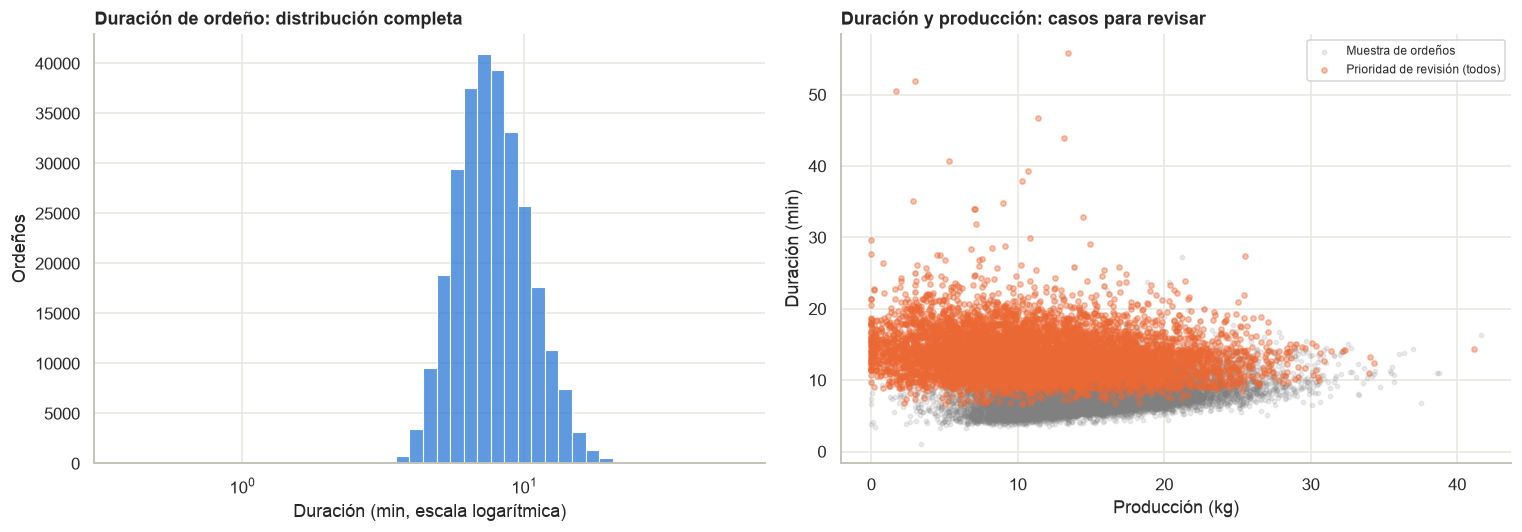

In [56]:
MIN_REGISTROS_COLA = 20
analisis_cola = ordenos.copy()
analisis_cola["duracion_positiva_min"] = analisis_cola["duracion_min"].where(analisis_cola["duracion_min"].gt(0))
columnas_flujo_cola = [f"media_de_los_flujos_kg_min_{q}" for q in CUARTOS]
analisis_cola["flujo_medio_cuartos"] = analisis_cola[columnas_flujo_cola].mean(axis=1).where(
    analisis_cola[columnas_flujo_cola].notna().all(axis=1))


def umbral_por_vaca_cola(columna, percentil):
    grupos = analisis_cola.groupby("id_vaca")[columna]
    umbral = grupos.transform(lambda s: s.quantile(percentil))
    return umbral.where(grupos.transform("count").ge(MIN_REGISTROS_COLA), analisis_cola[columna].quantile(percentil))


analisis_cola["umbral_duracion_p95_min"] = umbral_por_vaca_cola("duracion_positiva_min", 0.95)
analisis_cola["umbral_produccion_p25_kg"] = umbral_por_vaca_cola("main_produccion_kg", 0.25)
analisis_cola["umbral_flujo_p25"] = umbral_por_vaca_cola("flujo_medio_cuartos", 0.25)
analisis_cola["duracion_larga"] = analisis_cola["duracion_positiva_min"].gt(analisis_cola["umbral_duracion_p95_min"])
analisis_cola["produccion_baja"] = analisis_cola["main_produccion_kg"].le(analisis_cola["umbral_produccion_p25_kg"])
analisis_cola["flujo_bajo"] = analisis_cola["flujo_medio_cuartos"].le(analisis_cola["umbral_flujo_p25"])
analisis_cola["prioridad_revision"] = analisis_cola["duracion_larga"] & (analisis_cola["produccion_baja"] | analisis_cola["flujo_bajo"])
analisis_cola["exceso_sobre_p95_min"] = (analisis_cola["duracion_positiva_min"] - analisis_cola["umbral_duracion_p95_min"]).clip(lower=0)

resumen_duracion_cola = pd.Series({
    "Ordeños analizados": len(analisis_cola),
    "Duración faltante": analisis_cola["duracion_min"].isna().sum(),
    "Duración cero o negativa": analisis_cola["duracion_min"].le(0).sum(),
    "Duración mediana (min)": analisis_cola["duracion_positiva_min"].median(),
    "Duración P95 global (min)": analisis_cola["duracion_positiva_min"].quantile(0.95),
    "Duración superior al P95 de la vaca": analisis_cola["duracion_larga"].sum(),
    "Largos con producción baja": (analisis_cola["duracion_larga"] & analisis_cola["produccion_baja"]).sum(),
    "Largos con flujo bajo": (analisis_cola["duracion_larga"] & analisis_cola["flujo_bajo"]).sum(),
    "Prioridad de revisión (sin duplicar coincidencias)": analisis_cola["prioridad_revision"].sum(),
}, name="valor")
display(resumen_duracion_cola.round(2).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=analisis_cola.loc[analisis_cola["duracion_positiva_min"].notna()], x="duracion_positiva_min",
             bins=45, log_scale=True, color=AZUL, ax=axes[0])
axes[0].set(title="Duración de ordeño: distribución completa", xlabel="Duración (min, escala logarítmica)", ylabel="Ordeños")
muestra_cola = analisis_cola.sample(min(12000, len(analisis_cola)), random_state=SEMILLA)
axes[1].scatter(muestra_cola["main_produccion_kg"], muestra_cola["duracion_positiva_min"], s=8, alpha=0.15, color="gray", label="Muestra de ordeños")
prioritarios = analisis_cola.loc[analisis_cola["prioridad_revision"]]
axes[1].scatter(prioritarios["main_produccion_kg"], prioritarios["duracion_positiva_min"], s=12, alpha=0.4, color=NARANJA, label="Prioridad de revisión (todos)")
axes[1].set(title="Duración y producción: casos para revisar", xlabel="Producción (kg)", ylabel="Duración (min)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 18.2 Tiempo entre ordeños de la misma vaca: visitas próximas y retrasos

,count,mean,std,min,5%,50%,95%,99%,max
intervalo_positivo_h,280490.0,11.86,65.85,0.01,5.22,9.21,16.83,24.09,5444.41


,registros
Sin intervalo observado calculable,207
Intervalos observados de cero horas,0
Intervalos positivos inferiores al P5 de la vaca,14112
Intervalos positivos superiores al P95 de la vaca,14117
Intervalo largo y duración larga,2428


,ordeños,intervalo_mediano_h,produccion_mediana_kg,duracion_mediana_min,duraciones_validas,largos,duracion_larga_pct
grupo_intervalo,,,,,,,
Corto (< P5),14112,4.68,9.35,6.60,14112,626,4.44
Entre P5 y P95,252261,9.21,14.38,7.57,252261,10922,4.33
Largo (> P95),14117,18.37,20.08,9.30,14117,2428,17.20
Sin intervalo positivo,207,NaN,9.82,10.43,207,70,33.82


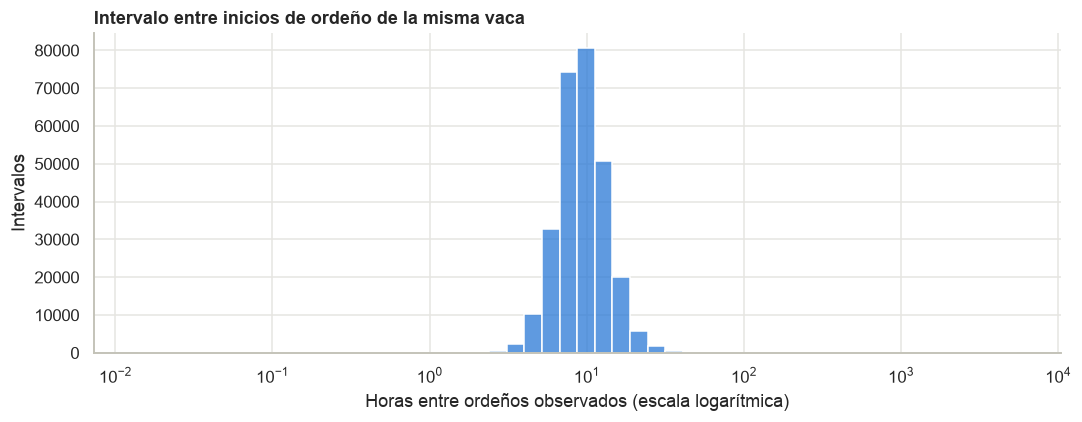

In [57]:
analisis_cola = analisis_cola.sort_values(["id_vaca", "inicio"], na_position="last")
analisis_cola["intervalo_observado_h"] = analisis_cola.groupby("id_vaca")["inicio"].diff().dt.total_seconds() / 3600
analisis_cola["intervalo_positivo_h"] = analisis_cola["intervalo_observado_h"].where(analisis_cola["intervalo_observado_h"].gt(0))
analisis_cola["umbral_intervalo_p05_h"] = umbral_por_vaca_cola("intervalo_positivo_h", 0.05)
analisis_cola["umbral_intervalo_p95_h"] = umbral_por_vaca_cola("intervalo_positivo_h", 0.95)
analisis_cola["intervalo_corto"] = analisis_cola["intervalo_positivo_h"].lt(analisis_cola["umbral_intervalo_p05_h"])
analisis_cola["intervalo_largo"] = analisis_cola["intervalo_positivo_h"].gt(analisis_cola["umbral_intervalo_p95_h"])

display(analisis_cola[["intervalo_positivo_h"]].describe(percentiles=[0.05, 0.5, 0.95, 0.99]).T.round(2))
display(pd.Series({
    "Sin intervalo observado calculable": analisis_cola["intervalo_observado_h"].isna().sum(),
    "Intervalos observados de cero horas": analisis_cola["intervalo_observado_h"].eq(0).sum(),
    "Intervalos positivos inferiores al P5 de la vaca": analisis_cola["intervalo_corto"].sum(),
    "Intervalos positivos superiores al P95 de la vaca": analisis_cola["intervalo_largo"].sum(),
    "Intervalo largo y duración larga": (analisis_cola["intervalo_largo"] & analisis_cola["duracion_larga"]).sum(),
}, name="registros").to_frame())

analisis_cola["grupo_intervalo"] = np.select(
    [analisis_cola["intervalo_corto"], analisis_cola["intervalo_largo"], analisis_cola["intervalo_positivo_h"].notna()],
    ["Corto (< P5)", "Largo (> P95)", "Entre P5 y P95"], default="Sin intervalo positivo")
resumen_intervalos_cola = analisis_cola.groupby("grupo_intervalo").agg(
    ordeños=("id_vaca", "size"), intervalo_mediano_h=("intervalo_positivo_h", "median"),
    produccion_mediana_kg=("main_produccion_kg", "median"), duracion_mediana_min=("duracion_positiva_min", "median"),
    duraciones_validas=("duracion_positiva_min", "count"), largos=("duracion_larga", "sum"))
resumen_intervalos_cola["duracion_larga_pct"] = resumen_intervalos_cola["largos"] / resumen_intervalos_cola["duraciones_validas"].replace(0, np.nan) * 100
display(resumen_intervalos_cola.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=analisis_cola.loc[analisis_cola["intervalo_positivo_h"].notna()], x="intervalo_positivo_h",
             bins=50, log_scale=True, color=AZUL, ax=ax)
ax.set(title="Intervalo entre inicios de ordeño de la misma vaca", xlabel="Horas entre ordeños observados (escala logarítmica)", ylabel="Intervalos")
plt.tight_layout(); plt.show()

**Observaciones:** Hay 14,046 ordeños más largos que el P95 de su propia vaca, y 7,449 de ellos (53 %) además tienen producción o flujo bajo, que son los candidatos a revisar como posibles anomalías que ocupan el robot sin producir. Los intervalos largos son la señal más clara: las visitas posteriores a un intervalo mayor al P95 tienen duración larga en 17.2 % de los casos contra 4.3 a 4.4 % en el resto, producen 20.1 kg (contra 14.4 kg) y duran 9.3 min (contra 7.6 min); los intervalos cortos producen apenas 9.4 kg. No hay intervalos de cero horas. Estas señales no son una medida de la cola: el dataset no registra llegada ni espera, solo inicio y duración, y la cola real tiene que estimarse con la ocupación de las máquinas de la sección 7.

## 19. Concentrado consumido y producción de leche

Además de los ordeños, el equipo cuenta con el concentrado consumido por vaca (`Data/dataset_concentrado_anonimo.csv`, versión `vacas/4.0`), anonimizado con el mismo mapa que el dataset de ordeño, por lo que se une por `id_vaca`. El concentrado cubre del 28/01/2025 al 28/01/2026, así que el análisis conjunto se limita a ese periodo de 2025-2026.

### 19.1 Carga y cobertura

In [58]:
concentrado = pd.read_csv(raiz / "Data" / "dataset_concentrado_anonimo.csv", dtype={"id_vaca": "string"})
concentrado["hora_evento"] = pd.to_datetime(concentrado["hora_evento"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
concentrado["fecha"] = concentrado["hora_evento"].dt.normalize()
concentrado["consumido"] = pd.to_numeric(concentrado["consumido"], errors="coerce")
print(f"Registros de concentrado: {len(concentrado):,} | periodo: {concentrado['hora_evento'].min():%d/%m/%Y} a {concentrado['hora_evento'].max():%d/%m/%Y}")

# Sesiones de ordeño del mismo periodo (2025-2026)
ses25 = ordenos[ordenos["inicio"] >= "2025-01-01"]
vacas_ordeno = set(ses25["id_vaca"].dropna())
vacas_concentrado = set(concentrado["id_vaca"].dropna())
print(f"Vacas con sesiones 2025-2026: {len(vacas_ordeno)} | con concentrado: {len(vacas_concentrado)} | "
      f"compartidas: {len(vacas_ordeno & vacas_concentrado)} | con sesiones y sin concentrado: {len(vacas_ordeno - vacas_concentrado)}")
print("Fechas sin interpretar:", concentrado["hora_evento"].isna().sum(), "| consumos nulos:", concentrado["consumido"].isna().sum())
print("Alimentos:", concentrado["alimento"].unique().tolist())
concentrado["consumido"].describe(percentiles=[.25, .5, .75]).round(2).to_frame("consumido").T

Registros de concentrado: 129,532 | periodo: 28/01/2025 a 28/01/2026
Vacas con sesiones 2025-2026: 207 | con concentrado: 202 | compartidas: 201 | con sesiones y sin concentrado: 6
Fechas sin interpretar: 0 | consumos nulos: 0
Alimentos: ['Feed1']


,count,mean,std,min,25%,50%,75%,max
consumido,129532.0,1.1,0.58,0.0,0.66,1.08,1.5,4.72


### 19.2 Relación diaria entre concentrado y leche

El "día pareado" es cualquier fecha en que una vaca tiene datos de leche y de concentrado: se suman los ordeños y los consumos de ese día en una sola fila. Los días sin alguna de las dos medidas quedan fuera (no se cuentan como consumo cero).

Días vaca con leche: 53,838 | con concentrado: 50,010 | pareados: 49,981 (201 vacas)
Correlación diaria global: 0.599
Correlación diaria tras restar la media de cada vaca: 0.656


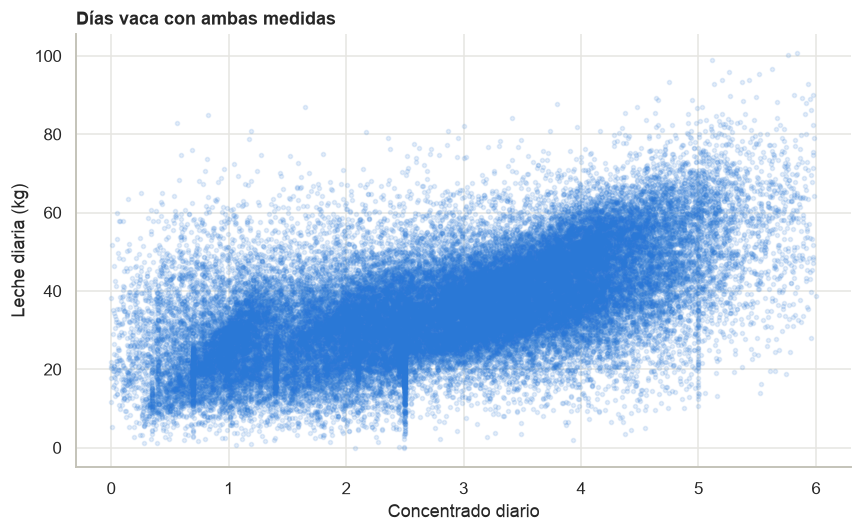

In [59]:
leche_dia = (ses25.dropna(subset=["main_produccion_kg"]).assign(fecha=lambda d: d["inicio"].dt.normalize())
             .groupby(["id_vaca", "fecha"]).agg(leche_kg=("main_produccion_kg", "sum"), sesiones=("main_produccion_kg", "size")).reset_index())
consumo_dia = (concentrado.dropna(subset=["fecha", "consumido"])
               .loc[lambda d: d["id_vaca"].isin(vacas_ordeno) & d["fecha"].ge("2025-01-01")]
               .groupby(["id_vaca", "fecha"]).agg(consumo=("consumido", "sum"), eventos_concentrado=("consumido", "size")).reset_index())
pareados = leche_dia.merge(consumo_dia, on=["id_vaca", "fecha"], how="inner", validate="one_to_one")
print(f"Días vaca con leche: {len(leche_dia):,} | con concentrado: {len(consumo_dia):,} | pareados: {len(pareados):,} ({pareados['id_vaca'].nunique()} vacas)")

correlacion_global = pareados["consumo"].corr(pareados["leche_kg"])
centrado = pareados[["id_vaca", "consumo", "leche_kg"]].copy()
for columna in ["consumo", "leche_kg"]:
    centrado[columna] -= centrado.groupby("id_vaca")[columna].transform("mean")
correlacion_dentro_vaca = centrado["consumo"].corr(centrado["leche_kg"])
print(f"Correlación diaria global: {correlacion_global:.3f}")
print(f"Correlación diaria tras restar la media de cada vaca: {correlacion_dentro_vaca:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(pareados["consumo"], pareados["leche_kg"], s=7, alpha=.13, color=AZUL)
ax.set(xlabel="Concentrado diario", ylabel="Leche diaria (kg)", title="Días vaca con ambas medidas")
plt.tight_layout(); plt.show()

### 19.3 Por vaca, con un día de desfase y precisión de las horas

Días pareados por vaca: mediana 275; rango 2-366
Correlación del mismo día por vaca (200 vacas): mediana 0.677; rango intercuartílico 0.545-0.774
Consumo del día anterior y leche actual: r global = 0.229; por vaca, mediana r = 0.068
Registros de concentrado a la hora en punto: 129,532 de 129,532


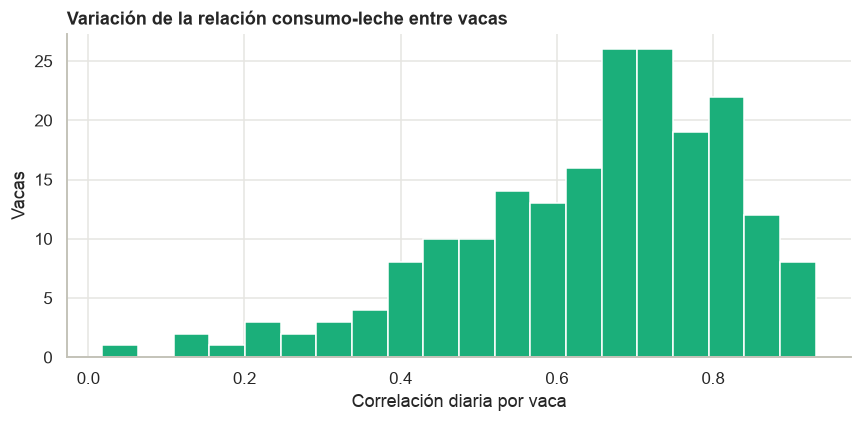

In [60]:
dias_por_vaca = pareados.groupby("id_vaca").size()
correlaciones_mismo_dia = (pareados.groupby("id_vaca")[["consumo", "leche_kg"]]
                           .apply(lambda d: d["consumo"].corr(d["leche_kg"]) if len(d) >= 10 else np.nan).dropna())
print(f"Días pareados por vaca: mediana {dias_por_vaca.median():.0f}; rango {dias_por_vaca.min()}-{dias_por_vaca.max()}")
print(f"Correlación del mismo día por vaca ({len(correlaciones_mismo_dia)} vacas): mediana {correlaciones_mismo_dia.median():.3f}; "
      f"rango intercuartílico {correlaciones_mismo_dia.quantile(.25):.3f}-{correlaciones_mismo_dia.quantile(.75):.3f}")

# Concentrado de ayer contra leche de hoy: se mueve la fecha del consumo un dia hacia adelante
consumo_anterior = consumo_dia[["id_vaca", "fecha", "consumo"]].copy()
consumo_anterior["fecha"] += pd.Timedelta(days=1)
desfase = leche_dia.merge(consumo_anterior, on=["id_vaca", "fecha"], how="inner", validate="one_to_one")
correlaciones_dia_anterior = (desfase.groupby("id_vaca")[["consumo", "leche_kg"]]
                              .apply(lambda d: d["consumo"].corr(d["leche_kg"]) if len(d) >= 10 else np.nan).dropna())
print(f"Consumo del día anterior y leche actual: r global = {desfase['consumo'].corr(desfase['leche_kg']):.3f}; "
      f"por vaca, mediana r = {correlaciones_dia_anterior.median():.3f}")

hora_en_punto = concentrado["hora_evento"].dt.minute.eq(0) & concentrado["hora_evento"].dt.second.eq(0)
print(f"Registros de concentrado a la hora en punto: {hora_en_punto.sum():,} de {len(concentrado):,}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(correlaciones_mismo_dia, bins=20, color=AQUA, edgecolor="white")
ax.set(xlabel="Correlación diaria por vaca", ylabel="Vacas", title="Variación de la relación consumo-leche entre vacas")
plt.tight_layout(); plt.show()

**Observaciones:** El concentrado trae 129,532 registros de 202 vacas del 28/01/2025 al 28/01/2026 (sin fechas ilegibles ni consumos nulos; un solo alimento, `Feed1`, con mediana de 1.08 por registro). Coinciden 201 de las 207 vacas con sesiones y hay 49,981 días vaca con leche y concentrado. La relación es positiva el mismo día (r = 0.60) y se mantiene al restar la media de cada vaca (r = 0.66), con una mediana de 0.68 por vaca. Con un día de desfase casi desaparece (r = 0.23 global y 0.07 por vaca), lo que sugiere que ambas medidas dependen de cuántas visitas hizo la vaca ese mismo día y no demuestra que el concentrado cause más leche. Todos los registros de concentrado están a la hora en punto, así que no se puede asociar un consumo a un ordeño específico, solo a un día o una hora.

## 20. Formato de los datos para el modelo: fechas y variables categóricas

Se arma una copia `df_modelo` (el `df` original no se modifica) con las fechas como `datetime`, las duraciones e intervalos como números y las variables categóricas con codificación one-hot. Se trabaja sobre todas las visitas de las tres máquinas, incluidos rechazos y «echada sin ordeñar».

- **Fechas:** `main_hora_de_inicio` llega como texto en dos formatos y se convierte a `datetime` (`inicio`). La duración (`mm:ss` o `hh:mm:ss`) y el intervalo (`hh:mm:ss` o fecha de Excel) se pasan a segundos y horas.
- **Categóricas de una sola etiqueta** (`main_accion`, `misc_destino_leche`, `misc_razon_de_la_desviacion`, `misc_eo_po`): one-hot normal. El nulo de la razón de desviación significa «sin razón», así que se vuelve una categoría propia.
- **Alertas por cuarto** (`estado_patada`, `estado_incompleto`, `estado_pezones_no_encontrados`, `estado_amd_pezon`): traen texto como `DI,TD` o `Todos`, una lista de cuartos, así que se codifican con multi-hot (una columna 0/1 por cuarto). Un nulo es «sin alerta» (0 en los cuatro cuartos).
- **No se codifican:** `id_vaca` (207 valores, es un identificador y generaría 207 columnas) y las columnas vacías o constantes (`misc_usuario`, `misc_programa_de_lavado`, `estado_rcs_1000_celulas_ml`), que se eliminan.

In [61]:
df_modelo = df[df["misc_eo_po"].isin(maquinas)].copy()

# --- Fechas, duraciones e intervalos: de texto a datetime / numero ---
def intervalo_a_horas(texto):
    """hh:mm:ss, o fecha de Excel (1900-01-01 hh:mm:ss = 24 h + hh:mm:ss) para los intervalos de 24 h o mas."""
    como_fecha = pd.to_datetime(texto.where(texto.str.len() > 8), format="%Y-%m-%d %H:%M:%S", errors="coerce")
    dias = (como_fecha - pd.Timestamp("1899-12-31")).dt.total_seconds() / 3600
    como_hora = pd.to_timedelta(texto.where(texto.str.len() <= 8)).dt.total_seconds() / 3600
    return dias.fillna(como_hora)

print("Hora de inicio antes:", df["main_hora_de_inicio"].dtype, "| después (inicio):", df_modelo["inicio"].dtype)
df_modelo["intervalo_h"] = intervalo_a_horas(df_modelo["main_intervalo_de_ordeno_hh_mm"])
df_modelo = df_modelo.drop(columns=["main_hora_de_inicio", "main_duracion_mm_ss", "main_intervalo_de_ordeno_hh_mm", "fuente"])

# --- Alertas por cuarto: multi-hot (texto con lista de cuartos -> 4 columnas 0/1) ---
alertas = {"estado_patada": "patada", "estado_incompleto": "incompleto",
           "estado_pezones_no_encontrados": "pezon_no_encontrado", "estado_amd_pezon": "amd_pezon"}
bloques = []
for columna, nombre in alertas.items():
    texto = df_modelo[columna].fillna("").str.upper().replace("TODOS", "DI,DD,TI,TD")
    bloque = texto.str.get_dummies(sep=",").reindex(columns=[c.upper() for c in CUARTOS], fill_value=0)
    bloques.append(bloque.rename(columns=lambda c: f"{nombre}_{c.lower()}"))

# --- Categoricas de una sola etiqueta: one-hot ---
df_modelo["misc_razon_de_la_desviacion"] = df_modelo["misc_razon_de_la_desviacion"].fillna("Sin razón")
df_modelo["misc_destino_leche"] = df_modelo["misc_destino_leche"].fillna("Sin dato")
categoricas = ["main_accion", "misc_destino_leche", "misc_razon_de_la_desviacion", "misc_eo_po"]
uno_hot = pd.get_dummies(df_modelo[categoricas], dtype=int)

vacias = ["misc_usuario", "misc_programa_de_lavado", "estado_rcs_1000_celulas_ml"]
df_modelo = pd.concat([df_modelo.drop(columns=list(alertas) + categoricas + vacias), *bloques, uno_hot], axis=1)

no_numericas = df_modelo.select_dtypes(exclude=["number", "datetime"]).columns.tolist()
print(f"Antes: {df.shape[1]} columnas | después: {df_modelo.shape[1]} columnas | filas: {len(df_modelo):,}")
print("Columnas que siguen sin ser numéricas ni fecha:", no_numericas)
print("\nTipos de dato:", df_modelo.dtypes.astype(str).value_counts().to_dict())
nuevas = [c for c in df_modelo.columns if c.startswith(tuple(alertas.values()) + tuple(f"{c}_" for c in categoricas))]
df_modelo[nuevas].sum().astype(int).to_frame("registros con 1")

Hora de inicio antes: str | después (inicio): datetime64[ns]


Antes: 47 columnas | después: 64 columnas | filas: 280,913
Columnas que siguen sin ser numéricas ni fecha: ['id_vaca']

Tipos de dato: {'float64': 31, 'int64': 31, 'str': 1, 'datetime64[ns]': 1}


,registros con 1
patada_di,16252
patada_dd,8812
patada_ti,10415
patada_td,20190
incompleto_di,6893
incompleto_dd,6506
incompleto_ti,15141
incompleto_td,15791
pezon_no_encontrado_di,5662
pezon_no_encontrado_dd,5282


**Observaciones:** `df_modelo` tiene 280,913 filas y 64 columnas: la hora de inicio pasó de texto a `datetime64`, la duración quedó en segundos y el intervalo en horas, y las 8 columnas de texto con categorías se convirtieron en 31 columnas 0/1 (16 de alertas por cuarto y 15 de acción, destino de la leche, razón de desviación y máquina). Lo único que queda como texto es `id_vaca`, a propósito. Hay 280,913 filas porque aquí entran los rechazos y las «echada sin ordeñar» (216) y solo se excluye la máquina con 2 registros; los 280,697 ordeños de las secciones anteriores son una parte de ellas. Dos cosas a tener en cuenta al modelar: las columnas de destino y razón de desviación son consecuencia del ordeño (sangre, drenaje), no una causa, y usarlas como entrada filtraría la respuesta si el objetivo es el tipo de evento. Además, `main_accion` solo distingue rechazos en los datos de 2025.

## 21. Conclusiones del Data Understanding

**Alcance.** El notebook reúne los seis EDA del equipo sobre 280,697 ordeños de 207 vacas en tres robots, del 13/07/2022 al 28/01/2026, más el clima de NASA POWER y el concentrado consumido en 2025-2026. Las secciones 1 a 9 son el análisis base de este notebook; las secciones 10 a 19 incorporan lo que aportan los demás archivos sin repetir lo que ya estaba cubierto.

**Conclusiones.**

1. **Calidad.** Los datos sirven para el objetivo, con tratamientos claros: unificar los dos formatos de fecha y duración, quitar las copias entre fuentes, eliminar las columnas vacías (`estado_rcs_1000_celulas_ml` y `misc_usuario`), tratar como faltantes la conductividad en 0 (28 % en el cuarto trasero derecho) y los intervalos de más de 48 h, y no imputar los nulos estructurales (rechazos y cuartos sin leche). El 0 kg de un ordeño casi siempre es una visita sin ordeñar (91 % con todos los pezones no encontrados) y no un error.
2. **Qué determina la producción.** Depende sobre todo del intervalo desde el ordeño anterior (r = 0.49) y de la etapa de lactancia, y poco de la época del año (alrededor de 10 %) y del clima. El historial por vaca es muy desigual y el hato crece de 34 a más de 180 vacas con las mismas tres máquinas, así que las series deben normalizarse por vaca.
3. **Eventos (patada, incompleto, pezón no encontrado).** Afectan a uno de cada tres ordeños, alargan la sesión unos 2 min y son persistentes y concentrados: el 10 % de las vacas acumula entre 31 y 38 % de cada evento, y un evento previo multiplica por 3 a 4.5 la probabilidad de repetirse. No dependen del robot (efecto despreciable) ni del clima (|r| ≤ 0.03). El incompleto y el pezón no encontrado son casi el mismo evento y van con cuartos traseros sin leche, producción baja y regreso antes de 4 h; hay mayor tasa en las primeras semanas de una vaca nueva.
4. **Salud de la ubre.** MDI, conductividad y AMD de ubre se mueven juntos y forman un grupo separado del normal; sirven como señal de anomalía junto con el destino de la leche (etiqueta débil) y la sangre, aunque no hay etiqueta confirmada de mastitis ni recuento de células somáticas.
5. **Cola.** El dataset no mide llegada ni espera, solo inicio y duración. Las señales indirectas (ocupación de las máquinas, relevos pegados, duraciones largas por vaca, intervalos largos) apuntan a robots con poco tiempo libre, y 7,449 ordeños largos con producción o flujo bajo son candidatos a anomalía.
6. **Variables y modelado.** Las variables no son redundantes (VIF máximo 2.84) y el PCA necesita 4 componentes para el 80 % de la varianza, así que no conviene reducir dimensiones a priori. Las variables de cola larga deben transformarse o tratarse con métodos robustos. Como los eventos son el 12 al 16 % de los ordeños, la exactitud (accuracy) no es una buena métrica: un modelo que siempre responda «sin evento» supera el 80 %, y hay que usar precisión, sensibilidad o F1.
7. **Concentrado.** Hay relación positiva el mismo día (r = 0.60) pero no con un día de desfase, y sin hora de ordeño asociada; no se puede inferir causalidad.

**Siguientes pasos (Data Preparation).** Definir las líneas base por vaca y por cuarto, calcular los días en leche (estimados con las ausencias de 45 días o más), decidir el tratamiento de la conductividad del cuarto trasero derecho, integrar el clima alineado (THI y viento), crear variables del evento previo de la misma vaca y confirmar con el socio formador las pausas de 4, 12 y 20 h, el umbral de conductividad y la unidad del concentrado.